In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from scipy.fft import fft, fftfreq
from scipy import signal
from os import listdir
from os.path import isfile, join
import re
import MasterPSD as PSD
from multiprocessing import Pool, cpu_count
from tqdm import tqdm
import VisAnalysis as Vis

In [3]:
NNF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Night2LongNoFibre", verbose=True)
NF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Night2Long", verbose=True)
MNF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Medium2LongNoFibre", verbose=True)
MF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Medium2Long", verbose=True)
DF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Day2Long", verbose=True)
DNF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-26", subfolder="Day2LongNoFibre", verbose=True)

Loaded 14 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Night2LongNoFibre
Loaded 12 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Night2Long
Loaded 12 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Medium2LongNoFibre
Loaded 13 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Medium2Long
Loaded 13 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Day2Long
Loaded 12 measurements from D:\PhD Thesis Writing\Data\2025-11-26\Day2LongNoFibre


In [5]:
NL = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-28", subfolder="Night2Long", verbose=True)
NLF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-28", subfolder="Night2LongFast", verbose=True)
NLVF = Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-28", subfolder="Night2LongVeryFast", verbose=True)

Loaded 13 measurements from D:\PhD Thesis Writing\Data\2025-11-28\Night2Long
Loaded 13 measurements from D:\PhD Thesis Writing\Data\2025-11-28\Night2LongFast
Loaded 13 measurements from D:\PhD Thesis Writing\Data\2025-11-28\Night2LongVeryFast


In [5]:
taus = Vis.hybrid_taus(
    1000,
    1e-4,
    1,
    100,
    log_sub=True,
    log_cycles=True)

In [7]:
taus

array([1.00e-04, 2.00e-04, 3.00e-04, 4.00e-04, 5.00e-04, 6.00e-04,
       7.00e-04, 8.00e-04, 9.00e-04, 1.00e-03, 2.00e-03, 3.00e-03,
       4.00e-03, 5.00e-03, 6.00e-03, 7.00e-03, 8.00e-03, 9.00e-03,
       1.00e-02, 1.10e-02, 1.20e-02, 1.30e-02, 1.40e-02, 1.50e-02,
       1.60e-02, 1.70e-02, 1.90e-02, 2.00e-02, 2.20e-02, 2.30e-02,
       2.50e-02, 2.70e-02, 2.80e-02, 3.10e-02, 3.30e-02, 3.50e-02,
       3.80e-02, 4.00e-02, 4.30e-02, 4.60e-02, 5.00e-02, 5.30e-02,
       5.70e-02, 6.10e-02, 6.60e-02, 7.10e-02, 7.60e-02, 8.10e-02,
       8.70e-02, 9.30e-02, 1.00e-01, 1.07e-01, 1.15e-01, 1.23e-01,
       1.32e-01, 1.42e-01, 1.52e-01, 1.63e-01, 1.75e-01, 1.87e-01,
       2.01e-01, 2.15e-01, 2.31e-01, 2.48e-01, 2.66e-01, 2.85e-01,
       3.05e-01, 3.27e-01, 3.51e-01, 3.76e-01, 4.04e-01, 4.33e-01,
       4.64e-01, 4.98e-01, 5.34e-01, 5.72e-01, 6.14e-01, 6.58e-01,
       7.05e-01, 7.56e-01, 8.11e-01, 8.70e-01, 9.33e-01, 1.00e+00])

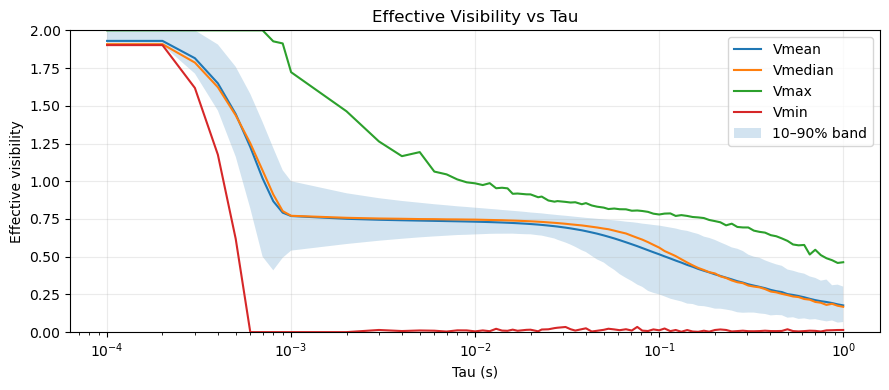

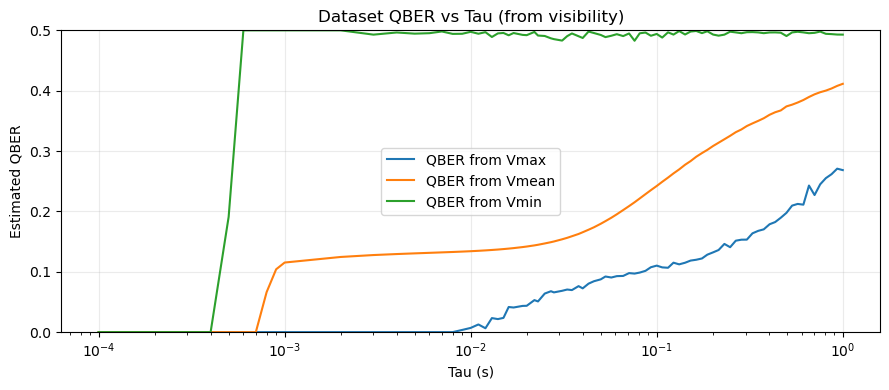

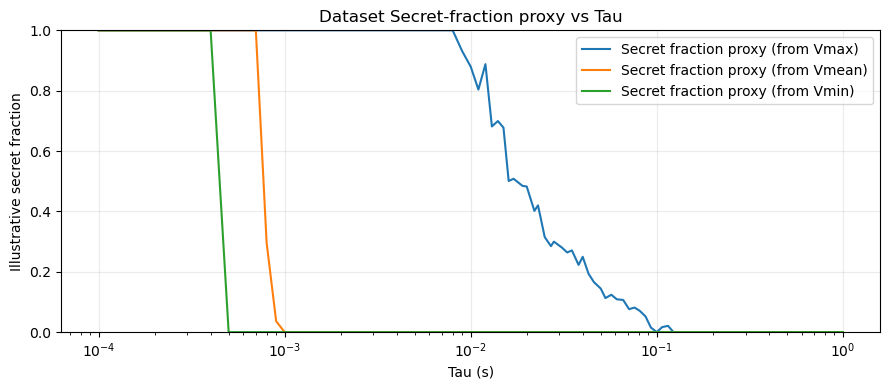

Operating tau (s): 0.001
Knee tau mean (s): 0.011
Knee tau median (s): 0.022


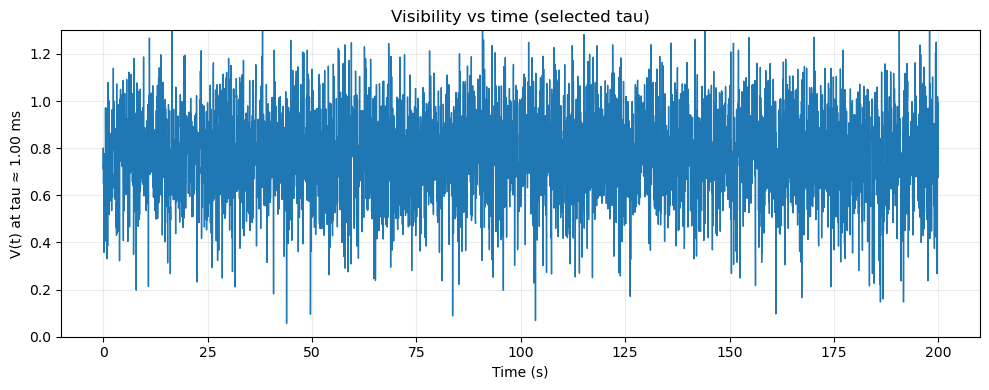

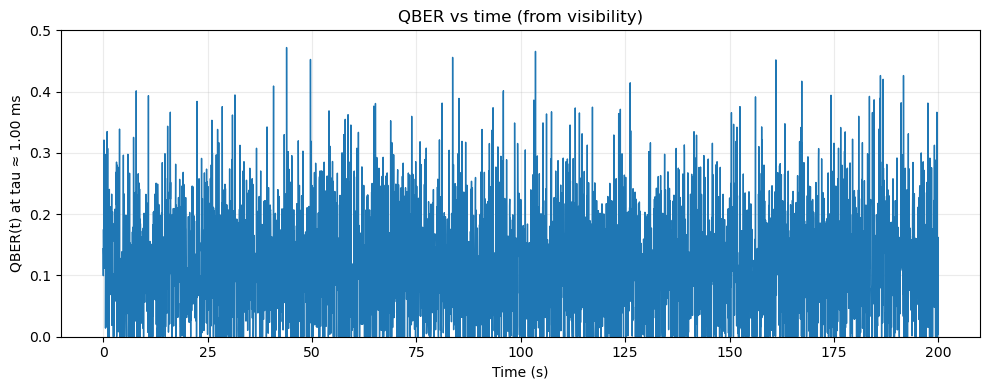

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 10, 'S': 5, 'tau': 0.001, 'step': 0.0005, 'n_windows_total': 399999, 'n_windows_used': 399999, 'mean_counts_per_window_used': 22.19819299548249}
V median: 0.7709412743773679
V mean:   0.7694269747062924
V 10–90%: 0.5402510807600336 … 0.9999956985444332


In [21]:
Vis.AnalyseMeasurement_New(DNF,8,100,1000,1e-4,1,None,1)

In [10]:
for i in range(len(NNF)):
    print(i,NNF[i]['name'])

0 Night_2_1MhzGate_195uWperArm_Rmp1000Hz_voaramp
1 Night_2_1MhzGate_195uWperArm_Rmp100Hz_voaramp
2 Night_2_1MhzGate_195uWperArm_Rmp10Hz_voaramp
3 Night_2_1MhzGate_195uWperArm_Rmp1Hz_voaramp
4 Night_2_1MhzGate_195uWperArm_Rmp1000Hz_nomodulation
5 Night_2_1MhzGate_195uWperArm_Rmp100Hz_nomodulation
6 Night_2_1MhzGate_195uWperArm_Rmp10Hz_nomodulation
7 Night_2_1MhzGate_195uWperArm_Rmp1Hz_nomodulation
8 Night_2_1MhzGate_195uWperArm_Rmp1000Hz
9 Night_2_1MhzGate_195uWperArm_Rmp100Hz
10 Night_2_1MhzGate_195uWperArm_Rmp10Hz
11 Night_2_1MhzGate_195uWperArm_Rmp1Hz
12 Test_Night_2_1MhzGate_195uWperArm_Rmp1Hz_nomodulation
13 Test_Night_2_1MhzGate_195uWperArm_Rmp1Hz_nomodulation


In [104]:
for i in range(len(NF)):
    print(i,NF[i]['name'])

0 Night_2_1MhzGate_153uWperArm_Rmp1000Hz_voaramp
1 Night_2_1MhzGate_153uWperArm_Rmp100Hz_voaramp
2 Night_2_1MhzGate_153uWperArm_Rmp10Hz_voaramp
3 Night_2_1MhzGate_153uWperArm_Rmp1Hz_voaramp
4 Night_2_1MhzGate_153uWperArm_Rmp1000Hz_nomodulation
5 Night_2_1MhzGate_153uWperArm_Rmp100Hz_nomodulation
6 Night_2_1MhzGate_153uWperArm_Rmp10Hz_nomodulation
7 Night_2_1MhzGate_153uWperArm_Rmp1Hz_nomodulation
8 Night_2_1MhzGate_153uWperArm_Rmp1000Hz
9 Night_2_1MhzGate_153uWperArm_Rmp100Hz
10 Night_2_1MhzGate_153uWperArm_Rmp10Hz
11 Night_2_1MhzGate_153uWperArm_Rmp1Hz


In [128]:
for i in range(len(DNF)):
    print(i,DNF[i]['name'])

0 Day_2_1MhzGate_107uWperArm_Rmp1000Hz_voaramp
1 Day_2_1MhzGate_107uWperArm_Rmp100Hz_voaramp
2 Day_2_1MhzGate_107uWperArm_Rmp10Hz_voaramp
3 Day_2_1MhzGate_107uWperArm_Rmp1Hz_voaramp
4 Day_2_1MhzGate_107uWperArm_Rmp1000Hz_nomodulation
5 Day_2_1MhzGate_107uWperArm_Rmp100Hz_nomodulation
6 Day_2_1MhzGate_107uWperArm_Rmp10Hz_nomodulation
7 Day_2_1MhzGate_107uWperArm_Rmp1Hz_nomodulation
8 Day_2_1MhzGate_107uWperArm_Rmp1000Hz
9 Day_2_1MhzGate_107uWperArm_Rmp100Hz
10 Day_2_1MhzGate_107uWperArm_Rmp10Hz
11 Day_2_1MhzGate_107uWperArm_Rmp1Hz


In [130]:
for i in range(len(DF)):
    print(i,DF[i]['name'])

0 Day_2_1MhzGate_85uWperArm_Rmp1Hz
1 Day_2_1MhzGate_85uWperArm_Rmp1000Hz_voaramp
2 Day_2_1MhzGate_85uWperArm_Rmp100Hz_voaramp
3 Day_2_1MhzGate_85uWperArm_Rmp10Hz_voaramp
4 Day_2_1MhzGate_85uWperArm_Rmp1Hz_voaramp
5 Day_2_1MhzGate_85uWperArm_Rmp1000Hz_nomodulation
6 Day_2_1MhzGate_85uWperArm_Rmp100Hz_nomodulation
7 Day_2_1MhzGate_85uWperArm_Rmp10Hz_nomodulation
8 Day_2_1MhzGate_85uWperArm_Rmp1Hz_nomodulation
9 Day_2_1MhzGate_85uWperArm_Rmp1000Hz
10 Day_2_1MhzGate_85uWperArm_Rmp100Hz
11 Day_2_1MhzGate_85uWperArm_Rmp10Hz
12 Day_2_1MhzGate_85uWperArm_Rmp1Hz


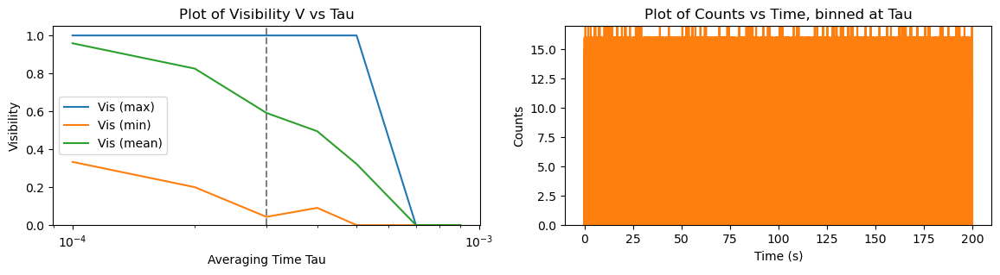

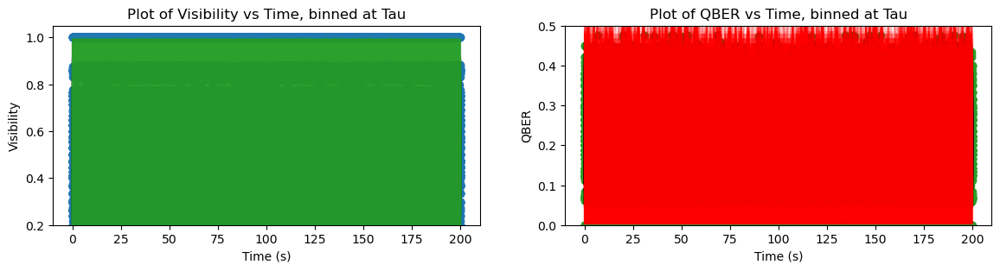

In [200]:
NNF_1000_em=Vis.AnalyseMeasurement(NNF,8,30,0.0003,0.001,secondhalf=True)

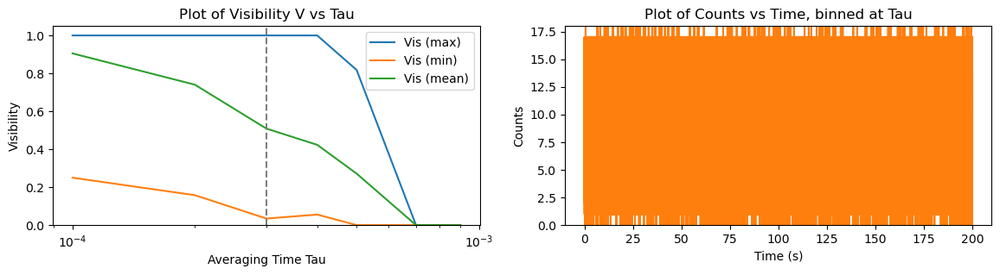

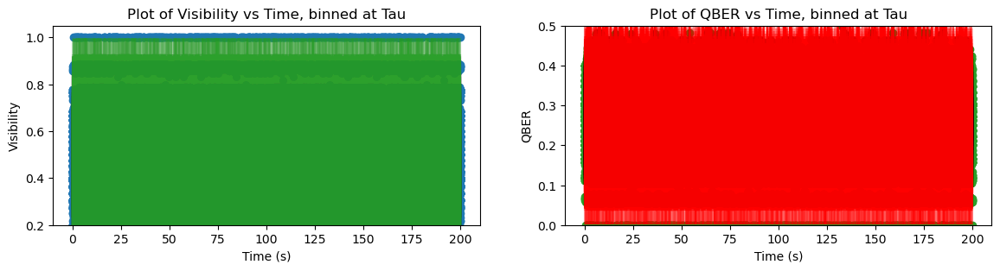

In [201]:
NF_1000_em=Vis.AnalyseMeasurement(NF,8,30,0.0003,0.001,secondhalf=True)

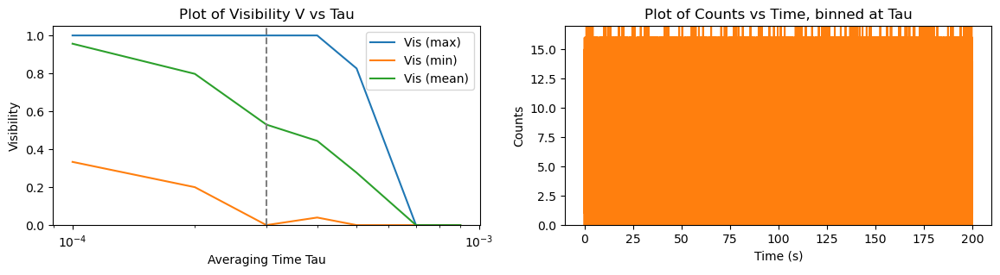

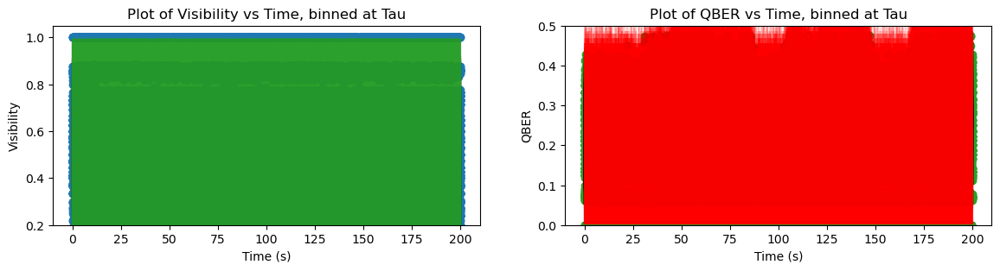

In [85]:
NNF_1000_nm=Vis.AnalyseMeasurement(NNF,4,30,0.0003,0.001,secondhalf=True)

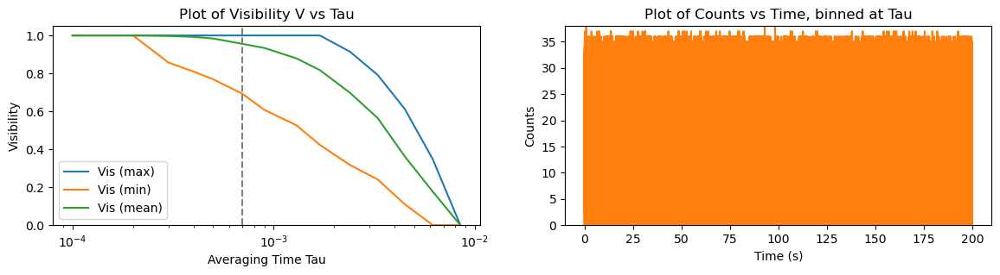

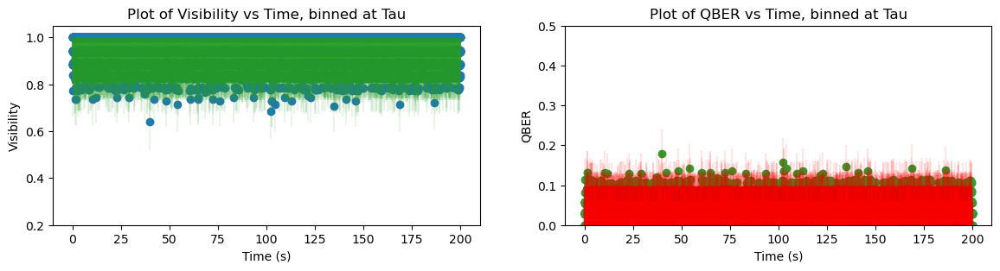

In [152]:
NNF_100_em=Vis.AnalyseMeasurement(NNF,9,30,0.0007,0.01,secondhalf=True)

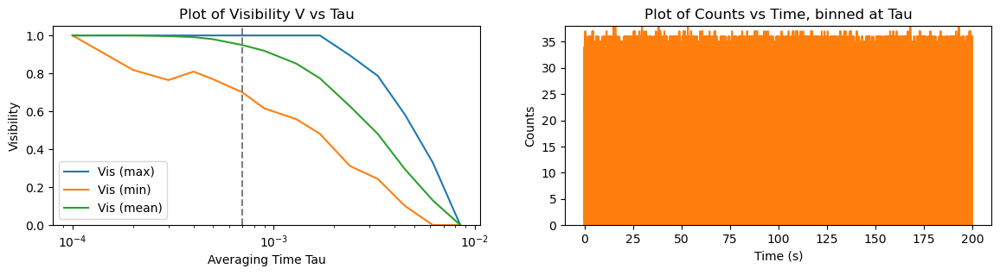

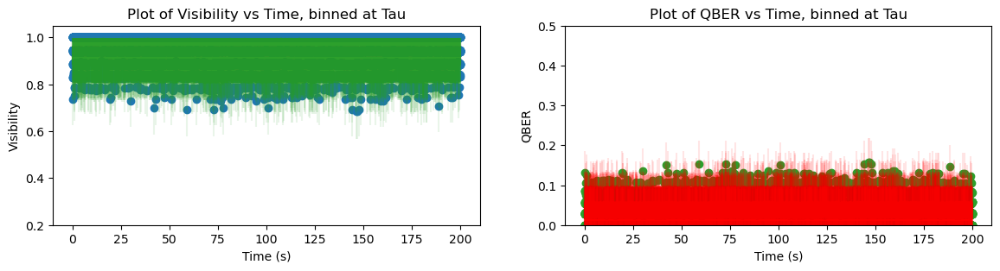

In [153]:
NNF_100_nm=Vis.AnalyseMeasurement(NNF,5,30,0.0007,0.01,secondhalf=True)

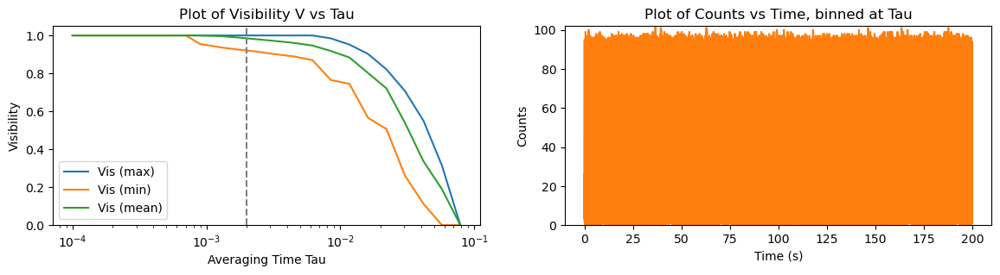

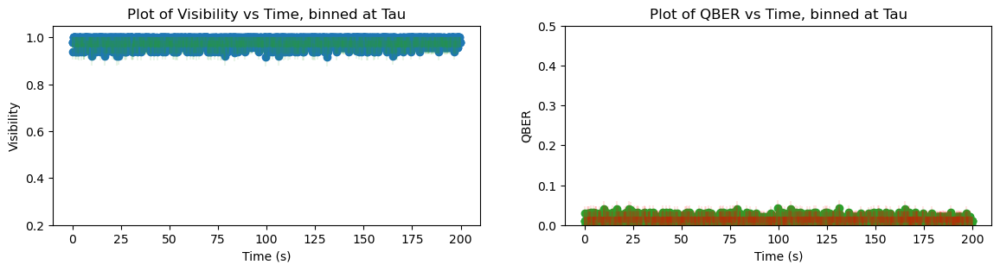

In [90]:
NNF_10_nm=Vis.AnalyseMeasurement(NNF,6,30,0.002,0.1,secondhalf=True)

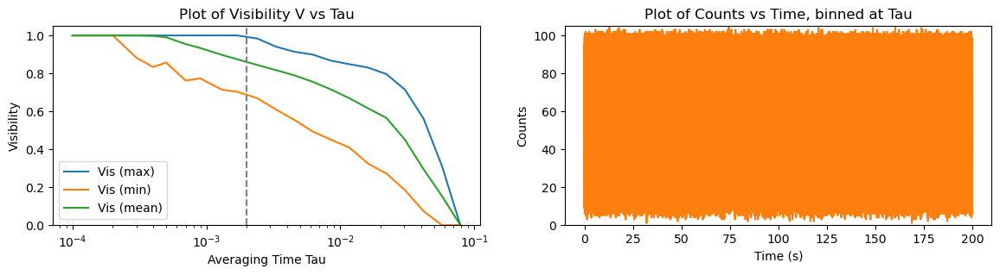

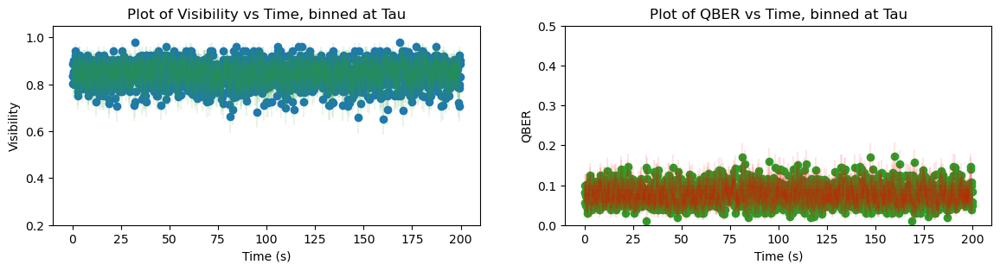

In [108]:
NF_10_nm=Vis.AnalyseMeasurement(NF,6,30,0.002,0.1,secondhalf=True)

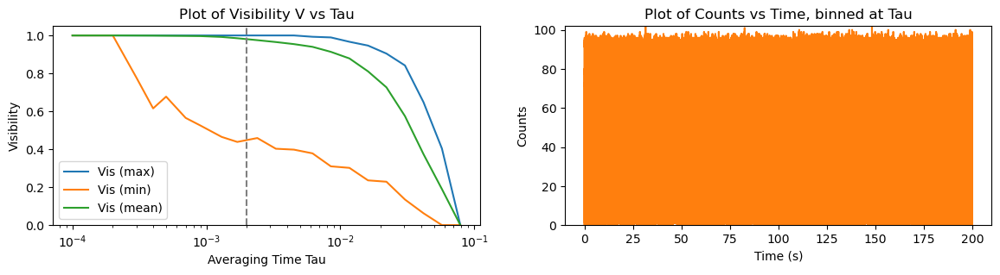

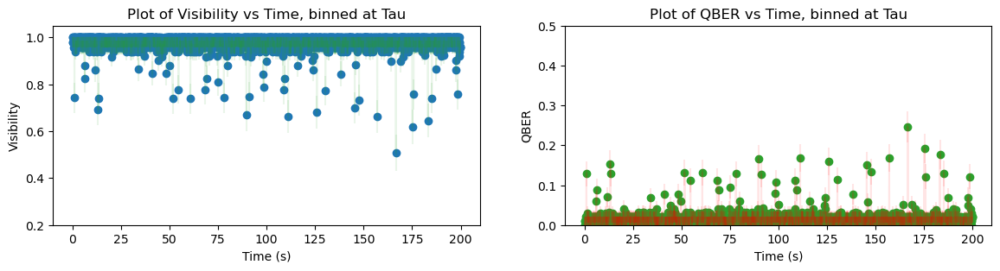

In [91]:
NNF_10_em=Vis.AnalyseMeasurement(NNF,10,30,0.002,0.1,secondhalf=True)

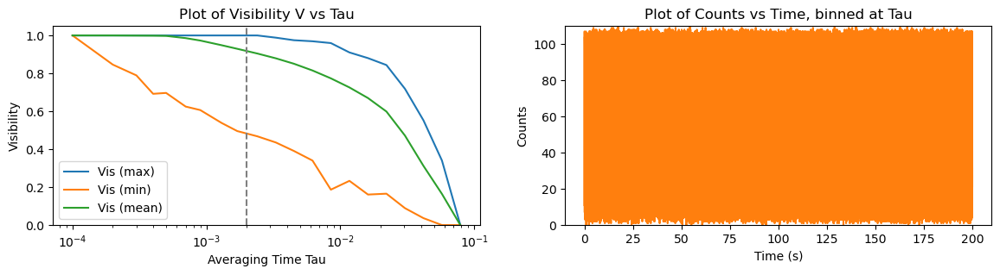

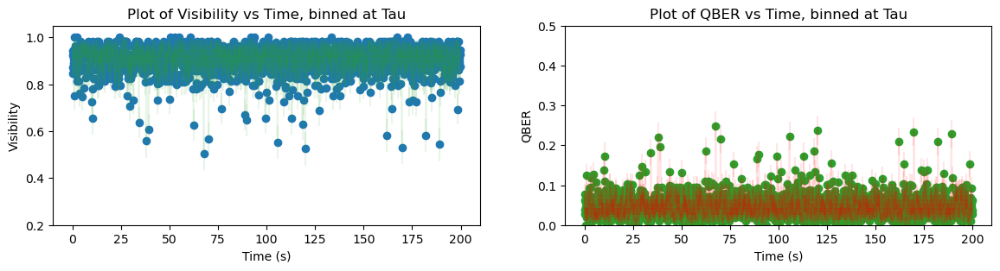

In [110]:
NF_10_em=Vis.AnalyseMeasurement(NF,10,30,0.002,0.1,secondhalf=True)

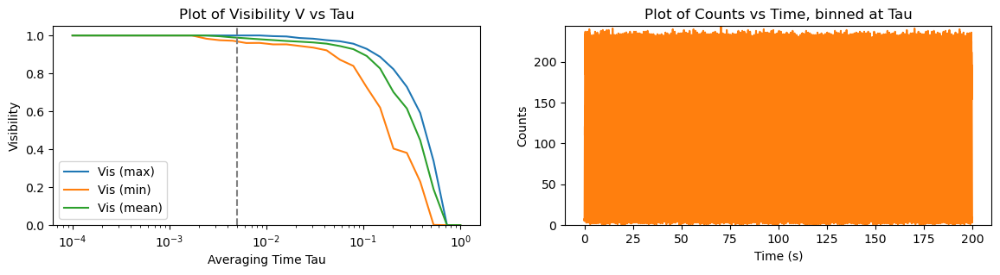

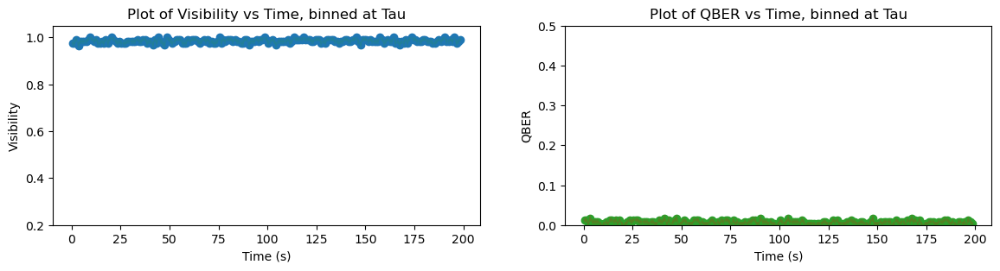

In [100]:
NNF_1_nm=Vis.AnalyseMeasurement(NNF,7,30,0.005,1,secondhalf=True)

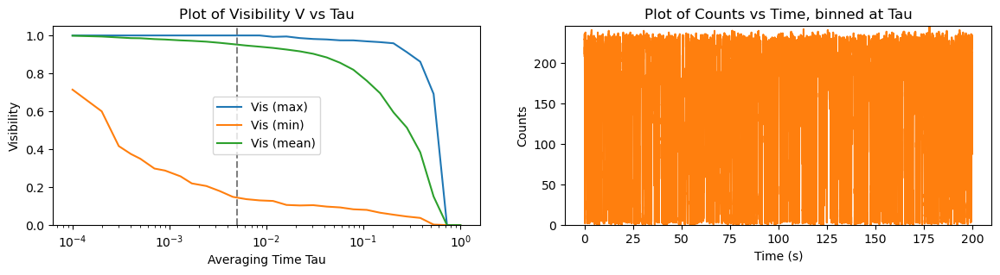

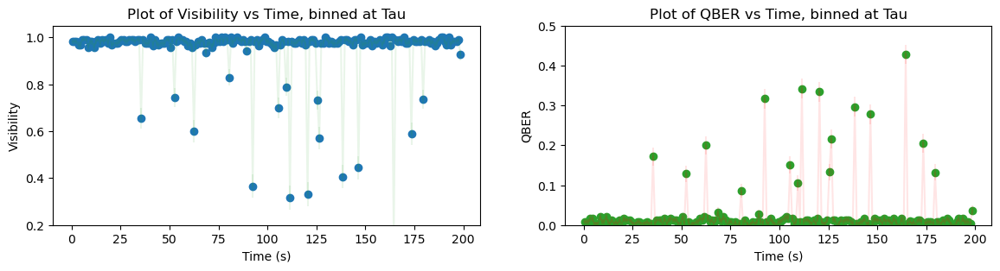

In [102]:
NNF_1_em=Vis.AnalyseMeasurement(NNF,11,30,0.005,1,secondhalf=True)

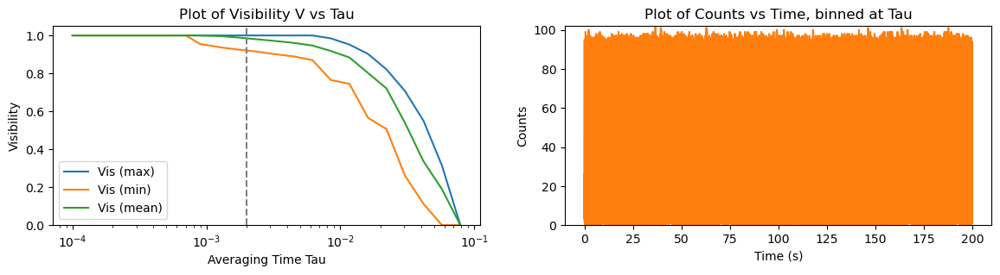

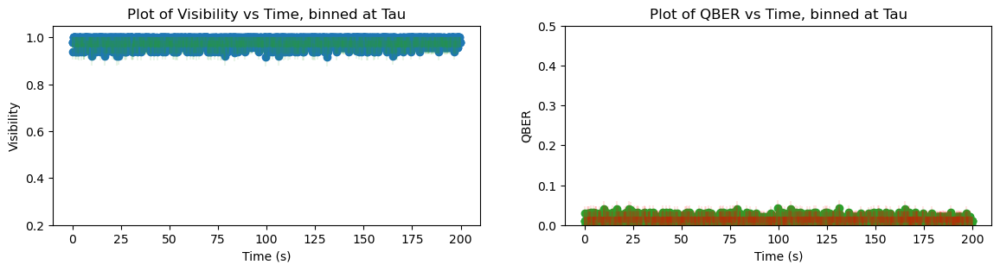

In [118]:
NNF_10_nm=Vis.AnalyseMeasurement(NNF,6,30,0.002,0.1,secondhalf=True)

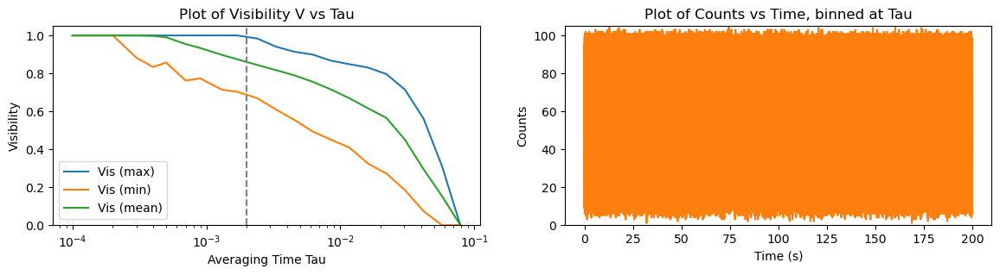

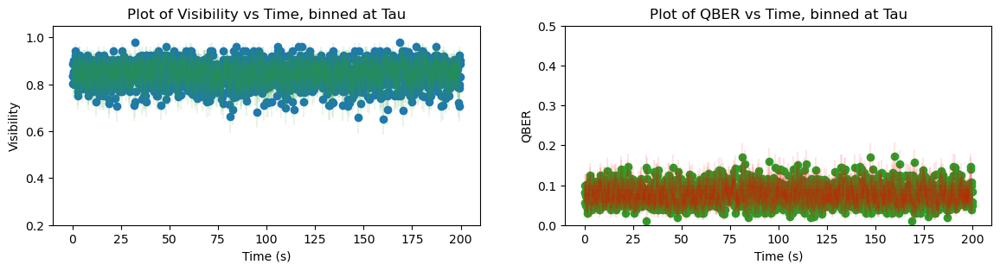

In [120]:
NF_10_nm=Vis.AnalyseMeasurement(NF,6,30,0.002,0.1,secondhalf=True)

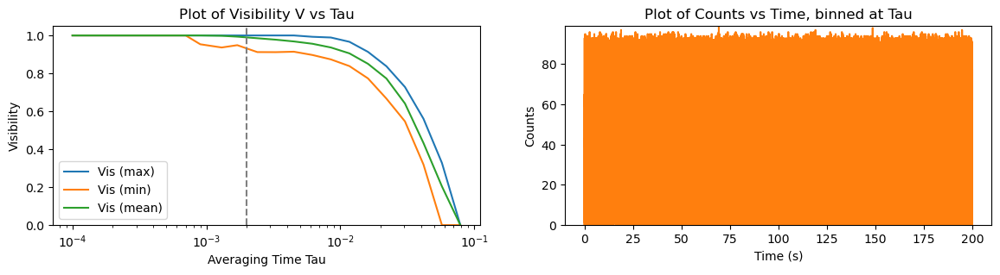

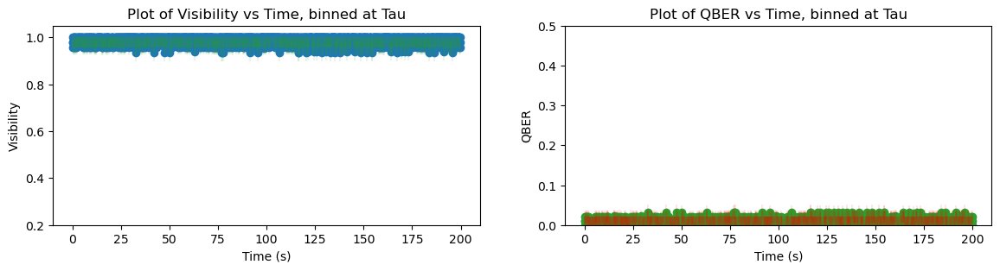

In [122]:
MNF_10_nm=Vis.AnalyseMeasurement(MNF,6,30,0.002,0.1,secondhalf=True)

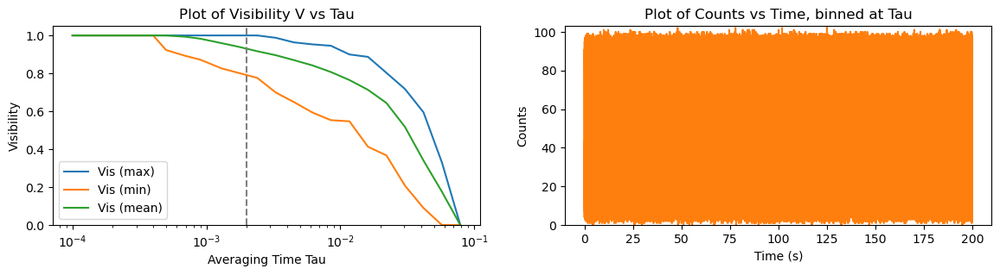

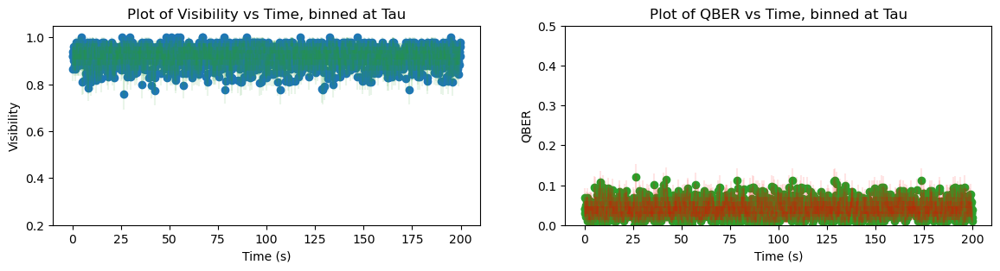

In [126]:
MF_10_nm=Vis.AnalyseMeasurement(MF,6,30,0.002,0.1,secondhalf=True)

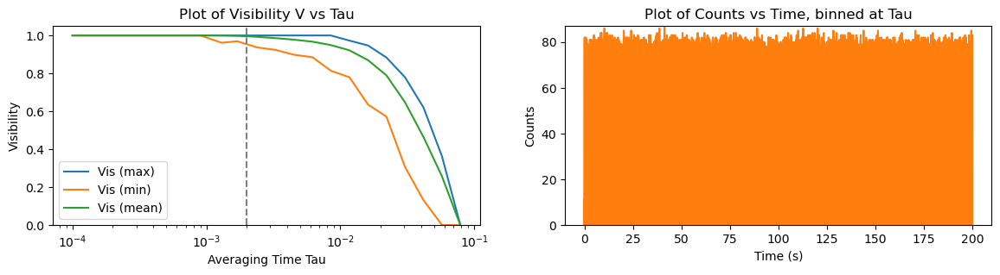

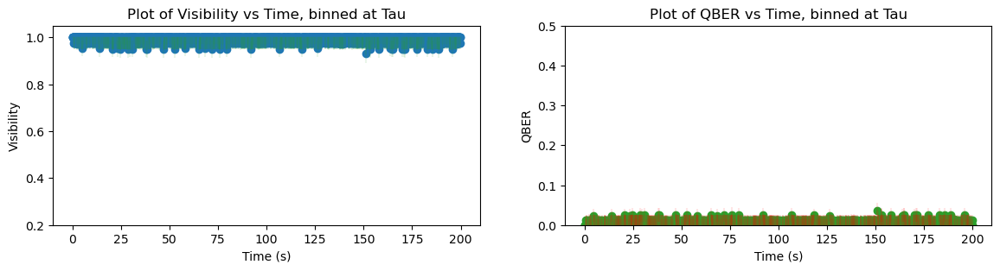

In [132]:
DNF_10_nm=Vis.AnalyseMeasurement(DNF,6,30,0.002,0.1,secondhalf=True)

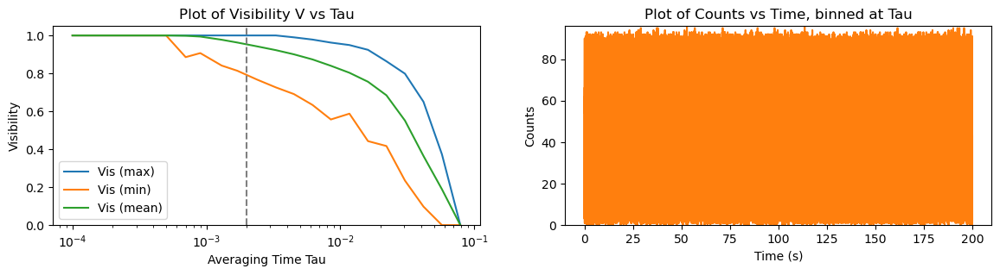

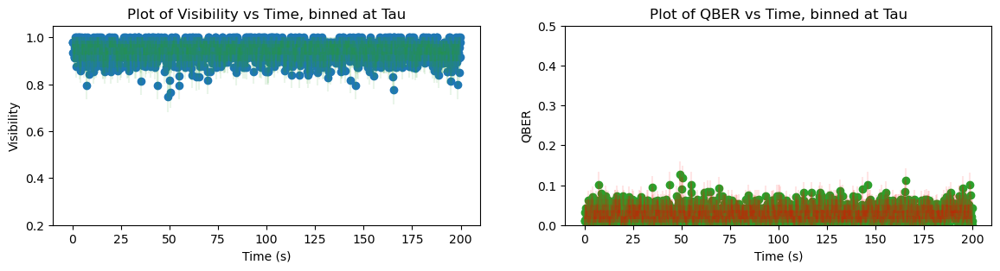

In [133]:
DF_10_nm=Vis.AnalyseMeasurement(DF,7,30,0.002,0.1,secondhalf=True)

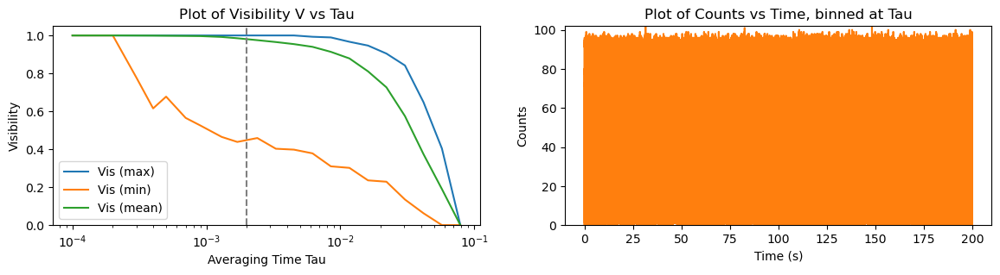

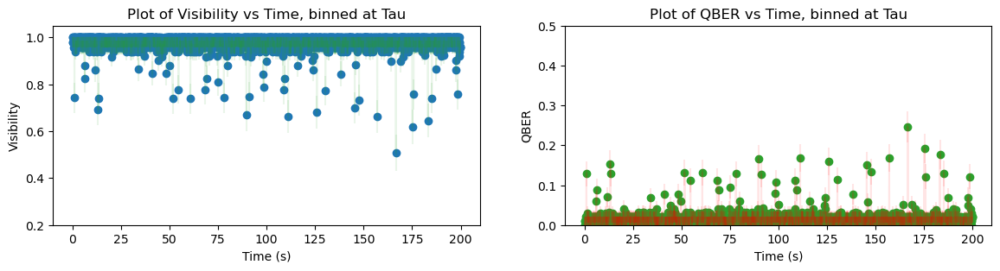

In [136]:
NNF_10_em=Vis.AnalyseMeasurement(NNF,10,30,0.002,0.1,secondhalf=True)

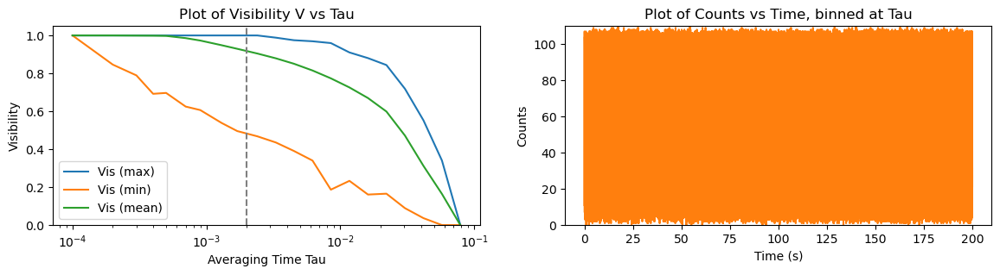

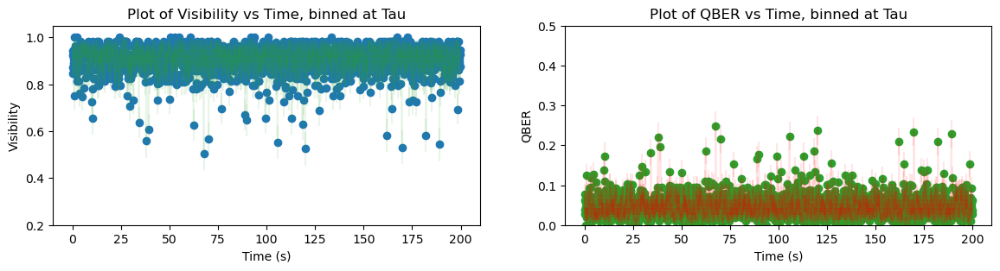

In [137]:
NF_10_em=Vis.AnalyseMeasurement(NF,10,30,0.002,0.1,secondhalf=True)

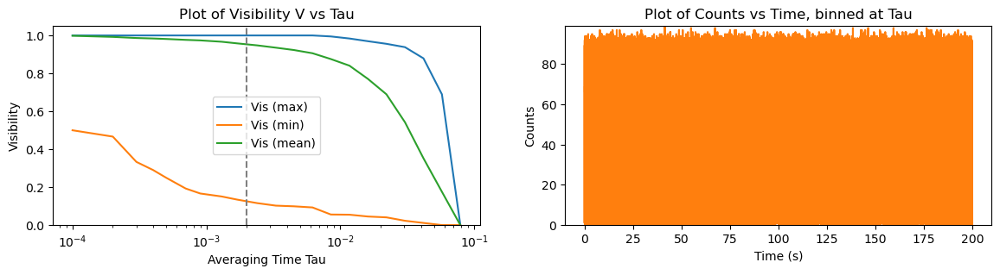

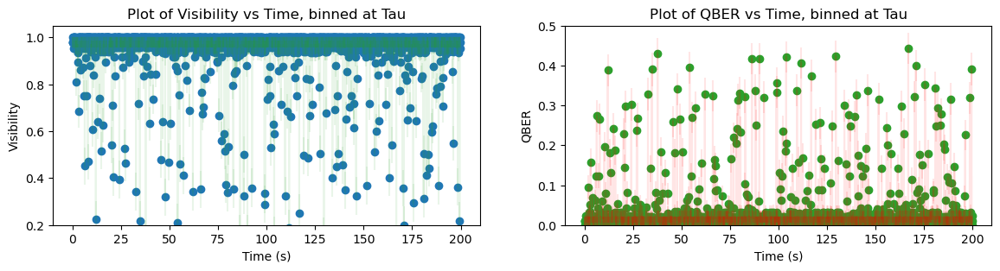

In [138]:
MNF_10_em=Vis.AnalyseMeasurement(MNF,10,30,0.002,0.1,secondhalf=True)

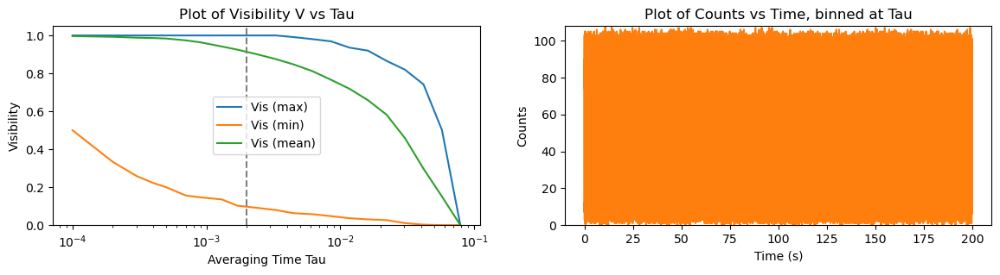

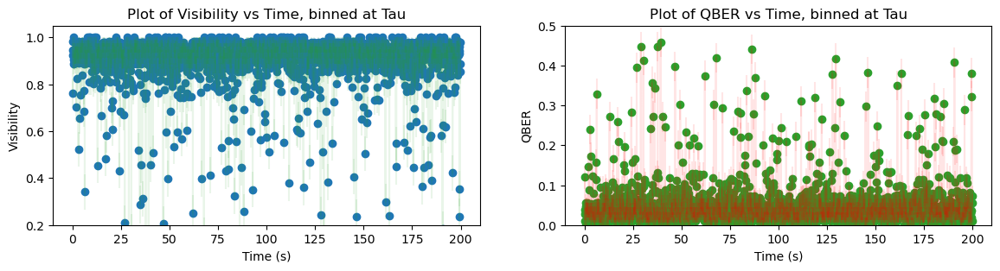

In [140]:
MF_10_em=Vis.AnalyseMeasurement(MF,10,30,0.002,0.1,secondhalf=True)

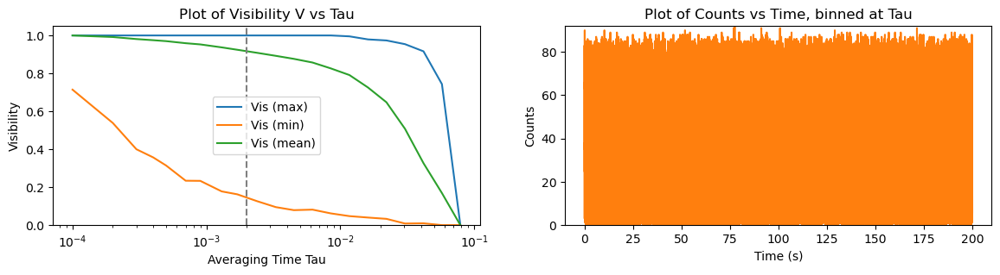

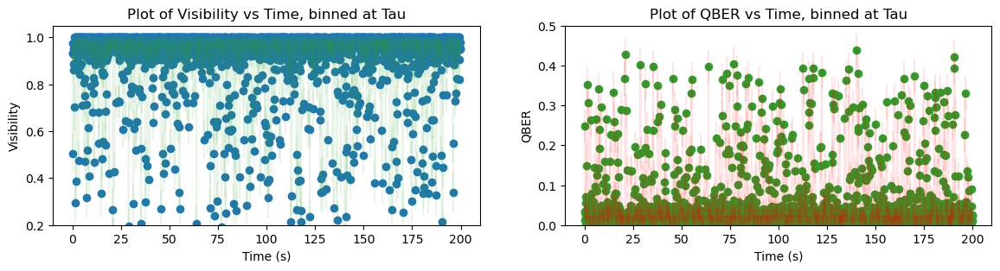

In [141]:
DNF_10_em=Vis.AnalyseMeasurement(DNF,10,30,0.002,0.1,secondhalf=True)

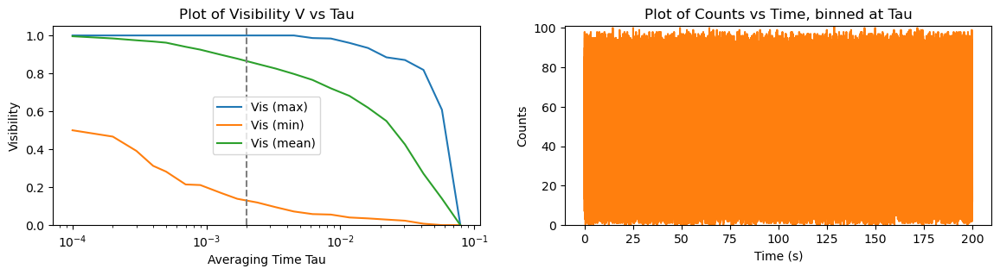

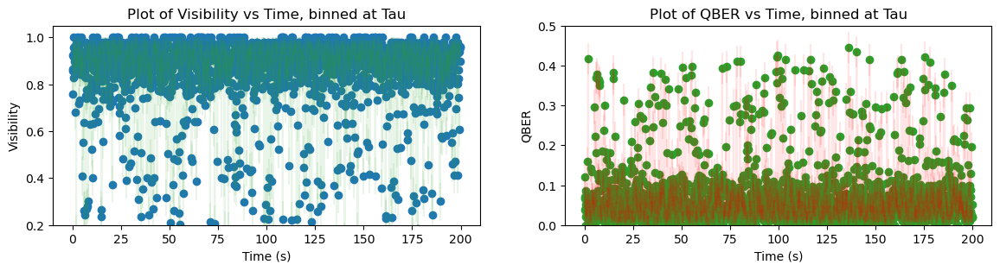

In [143]:
DF_10_em=Vis.AnalyseMeasurement(DF,11,30,0.002,0.1,secondhalf=True)

In [238]:
for i in range(len(NL)):
    print(i,NL[i]['name'])

0 Night_2_1MhzGate_158uWperArm_Rmp1000Hz_voaramp
1 Night_2_1MhzGate_158uWperArm_Rmp100Hz_voaramp
2 Night_2_1MhzGate_158uWperArm_Rmp10Hz_voaramp
3 Night_2_1MhzGate_158uWperArm_Rmp1Hz_voaramp
4 Night_2_1MhzGate_158uWperArm_Rmp1000Hz_nomodulation
5 Night_2_1MhzGate_158uWperArm_Rmp100Hz_nomodulation
6 Night_2_1MhzGate_158uWperArm_Rmp10Hz_nomodulation
7 Night_2_1MhzGate_158uWperArm_Rmp1Hz_nomodulation
8 Night_2_1MhzGate_158uWperArm_Rmp1000Hz
9 Night_2_1MhzGate_158uWperArm_Rmp100Hz
10 Night_2_1MhzGate_158uWperArm_Rmp10Hz
11 Night_2_1MhzGate_158uWperArm_Rmp1Hz
12 Night_2_1MhzGate_158uWperArm_Rmp1Hz


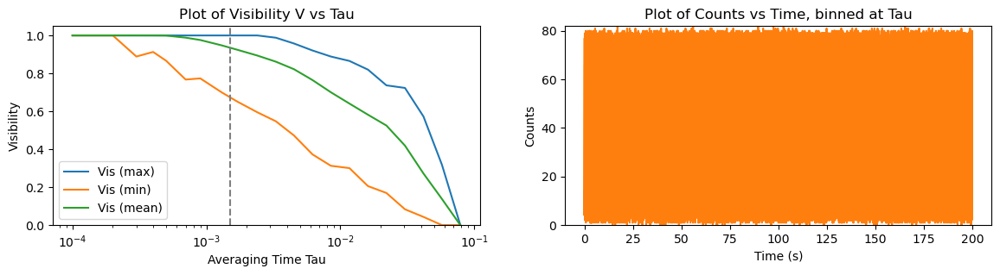

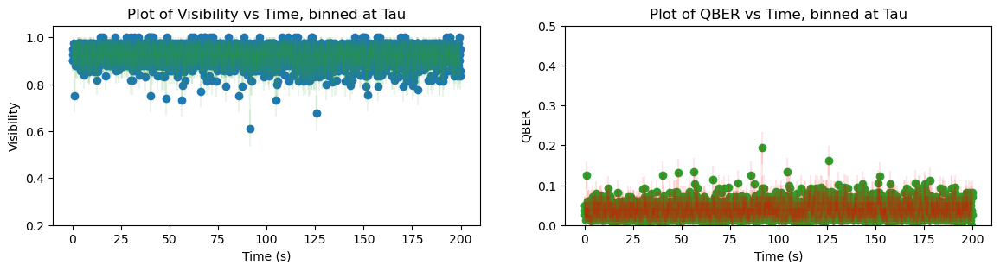

In [9]:
NL_10_em=Vis.AnalyseMeasurement(NL,10,30,0.0015,0.1,secondhalf=True)

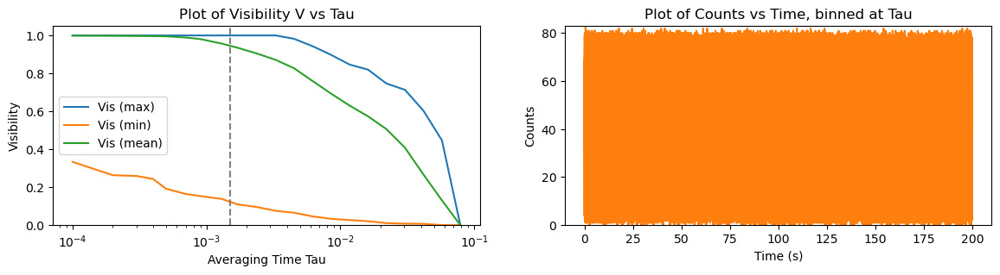

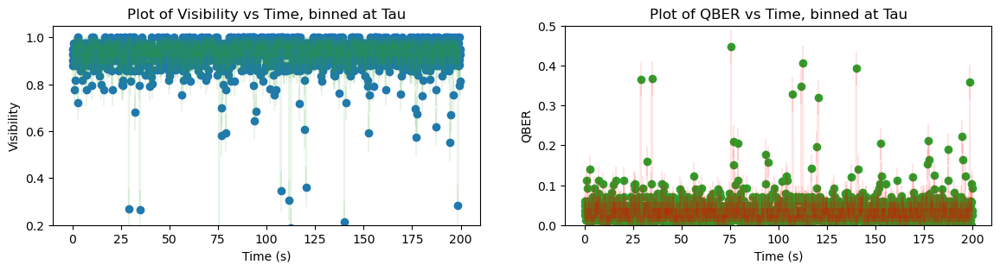

In [10]:
NLF_10_em=Vis.AnalyseMeasurement(NLF,10,30,0.0015,0.1,secondhalf=True)

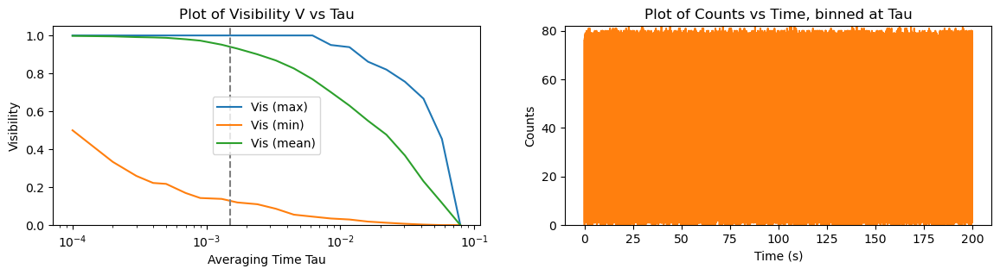

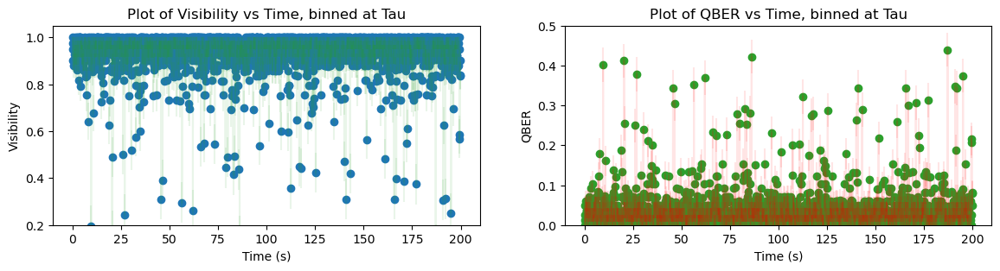

In [13]:
NLVF_10_em=Vis.AnalyseMeasurement(NLVF,10,30,0.0015,0.1,secondhalf=True)

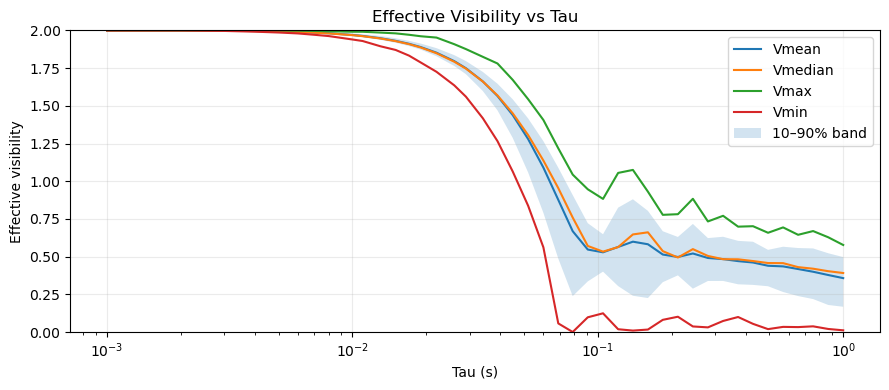

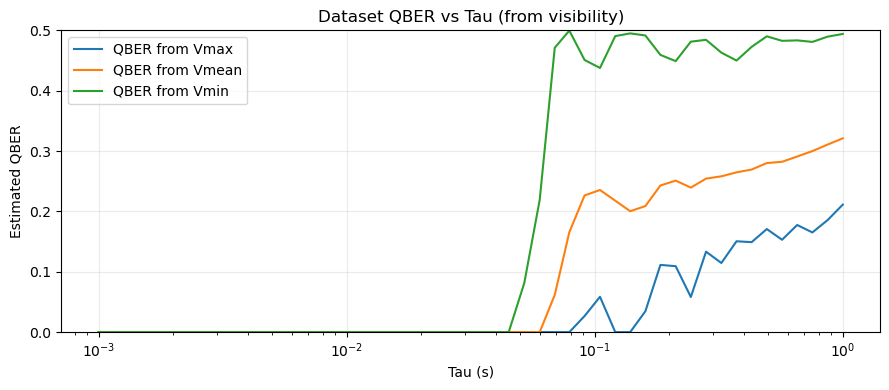

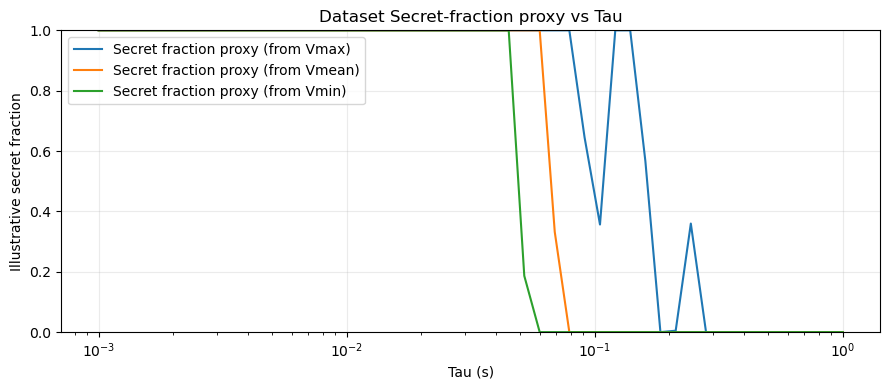

Operating tau (s): 0.0015
Knee tau mean (s): nan
Knee tau median (s): nan


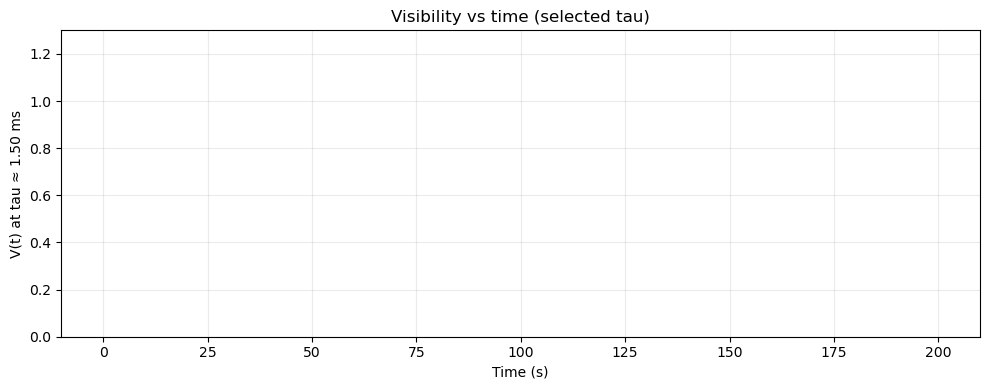

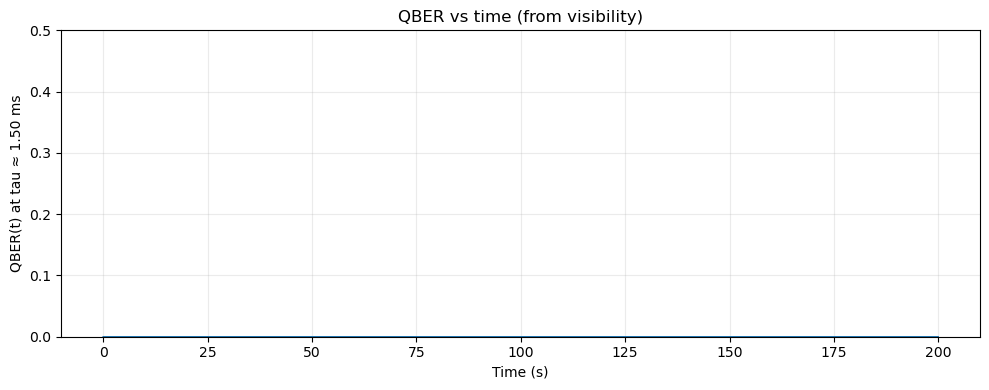

[Selected tau diagnostics]
{'dt': 0.001, 'K': 2, 'S': 1, 'tau': 0.002, 'step': 0.001, 'n_windows_total': 199999, 'n_windows_used': 199985, 'mean_counts_per_window_used': 68.36237217791334}
V median: 1.9990155399117309
V mean:   1.9990603005846723
V 10–90%: 1.9990132174984263 … 1.9991591394902173


In [63]:
NL_10_em2=Vis.AnalyseMeasurement_New(NL,10,50,10,1e-4,1,0.0015,10,binning=True,binfactor=10)

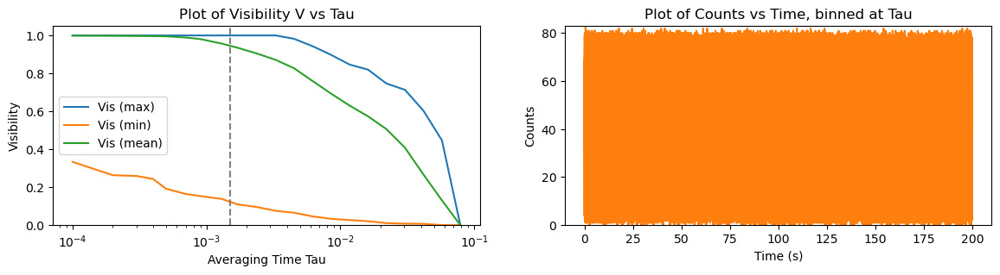

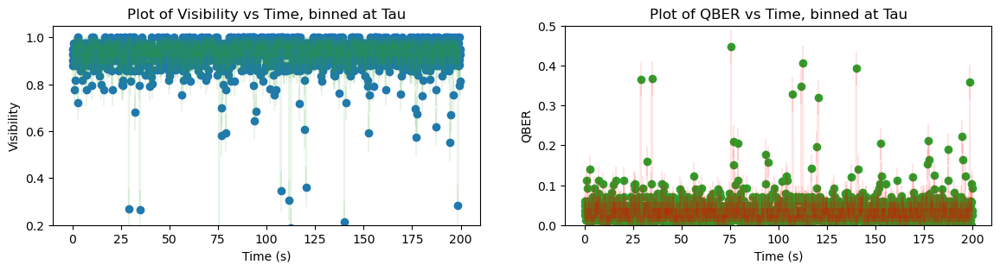

In [10]:
NLF_10_em2=Vis.AnalyseMeasurement_New(NLF,10,100,10,1)

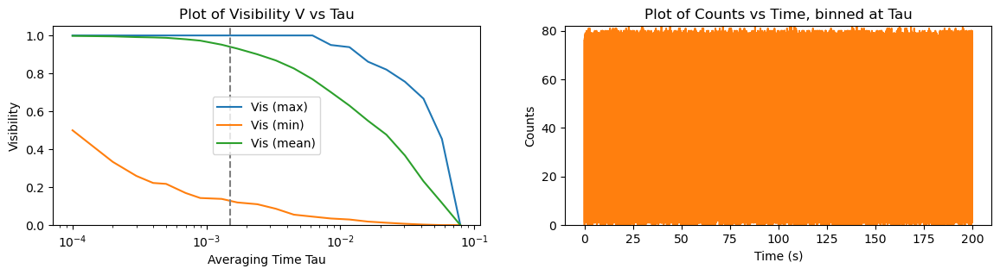

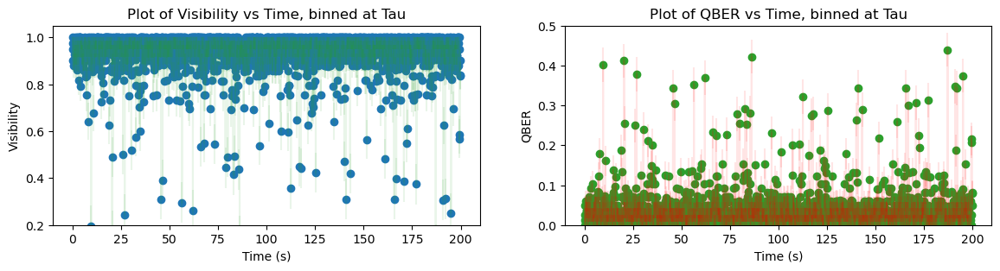

In [13]:
NLVF_10_em2=Vis.AnalyseMeasurement_New(NLVF,10,100,10,1)

In [182]:
np.save('NL_10_em',NL_10_em[2])

In [184]:
np.save('NLF_10_em',NLF_10_em[2])

In [186]:
np.save('NLVF_10_em',NLVF_10_em[2])

In [228]:
len(NL_10_em[2][1])

1999

In [456]:
NL[9]

{'name': 'Night_2_1MhzGate_158uWperArm_Rmp100Hz',
 'timestamp': datetime.datetime(2025, 11, 28, 17, 36, 58, tzinfo=datetime.timezone.utc),
 'npz_path': 'D:\\PhD Thesis Writing\\Data\\2025-11-28\\Night2Long\\Night_2_1MhzGate_158uWperArm_Rmp100Hz_20251128T173658+0000.npz',
 'csv_path': 'D:\\PhD Thesis Writing\\Data\\2025-11-28\\Night2Long\\Night_2_1MhzGate_158uWperArm_Rmp100Hz_20251128T173658+0000.csv',
 'meta_path': 'D:\\PhD Thesis Writing\\Data\\2025-11-28\\Night2Long\\Night_2_1MhzGate_158uWperArm_Rmp100Hz_20251128T173658+0000_meta.txt',
 'data': {'timestamps': array(['2025-11-28T17:36:58.680354000', '2025-11-28T17:36:58.680454000',
         '2025-11-28T17:36:58.680554000', ...,
         '2025-11-28T17:40:18.680054000', '2025-11-28T17:40:18.680154000',
         '2025-11-28T17:40:18.680254000'], dtype='datetime64[ns]'),
  'counts': array([4, 4, 4, ..., 6, 5, 4], dtype=uint32),
  'voa_volts': array([1.72010279, 1.72010279, 1.72010279, ..., 1.74315592, 1.74315592,
         1.74315592]),
 

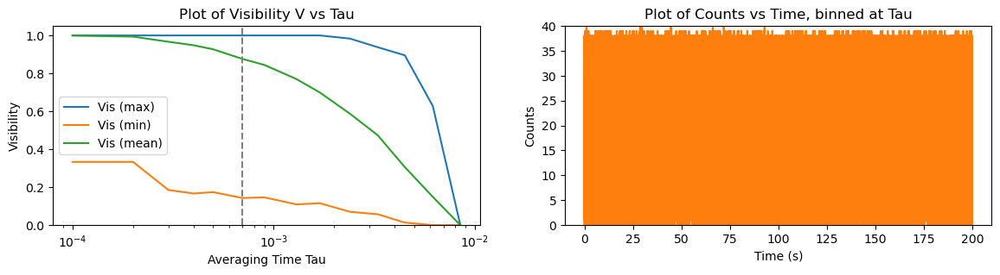

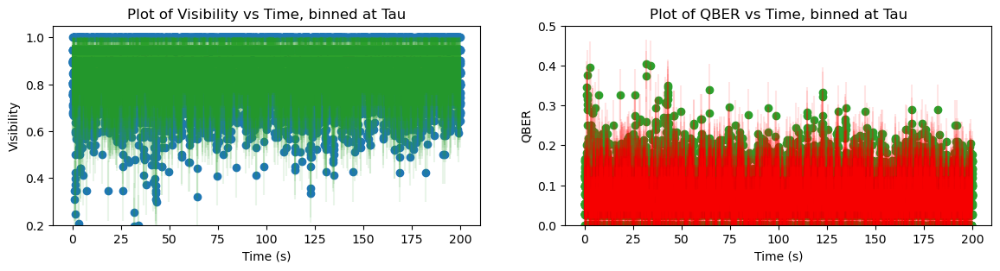

In [29]:
NL_100_em=Vis.AnalyseMeasurement(NL,9,30,0.0007,0.01,secondhalf=True)

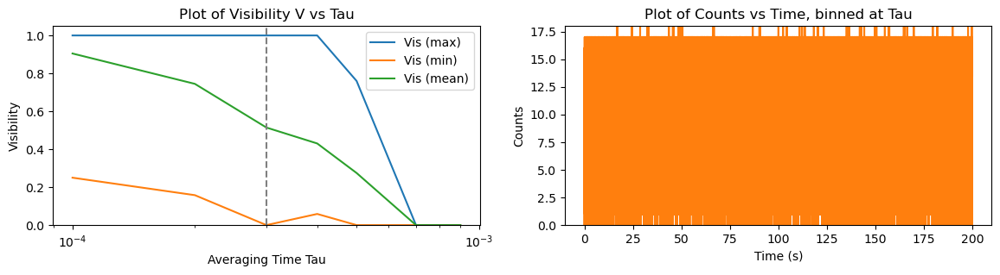

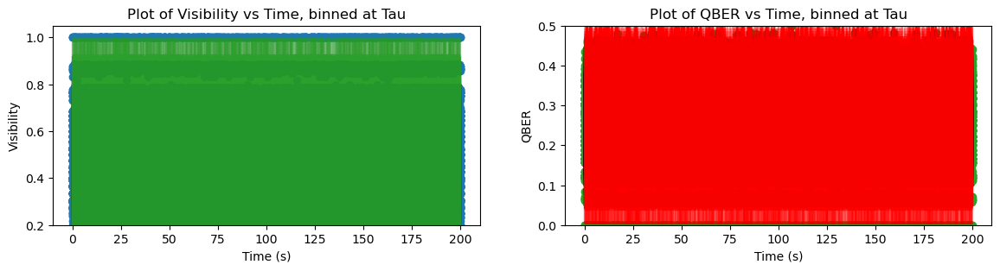

In [33]:
NL_1000_em=Vis.AnalyseMeasurement(NL,8,30,0.0003,0.001,secondhalf=True)

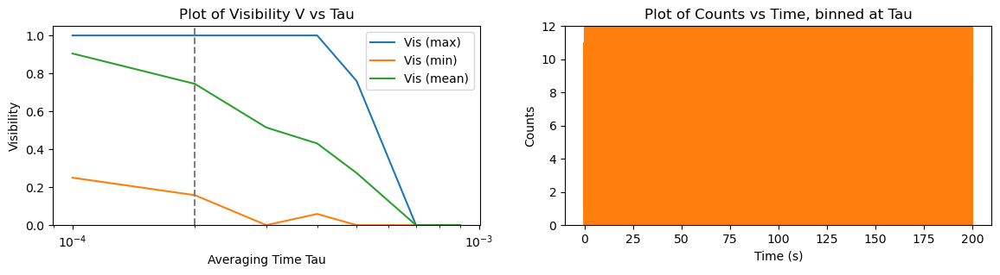

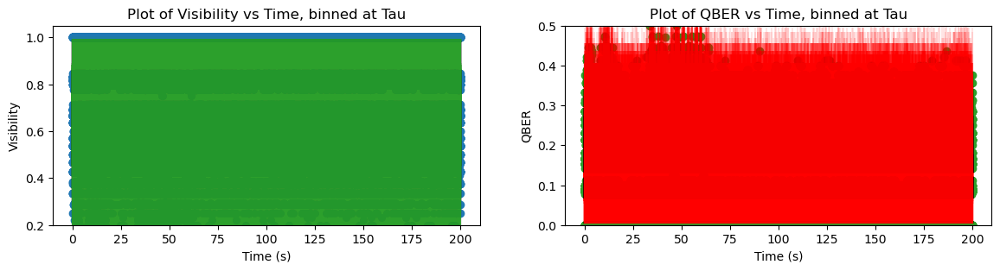

In [39]:
NL_1000_em_2=Vis.AnalyseMeasurement(NL,8,30,0.0002,0.001,secondhalf=True)

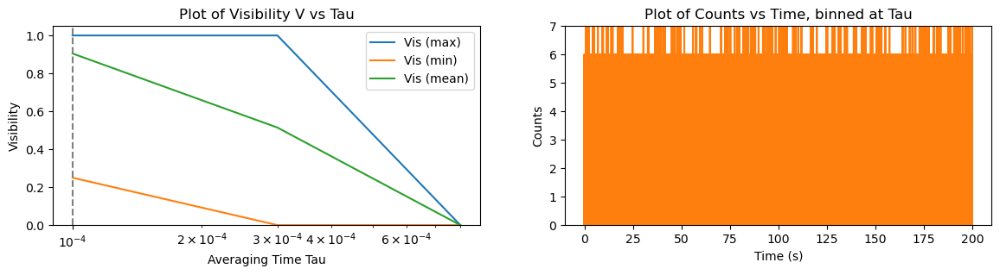

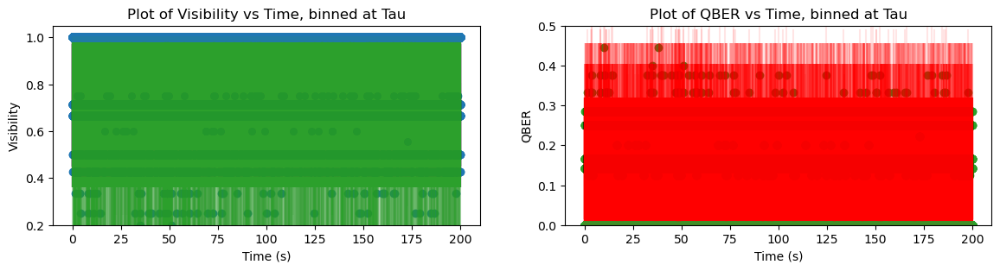

In [13]:
NL_1000_em_3=Vis.AnalyseMeasurement(NL,8,10,0.0001,0.001,secondhalf=True)

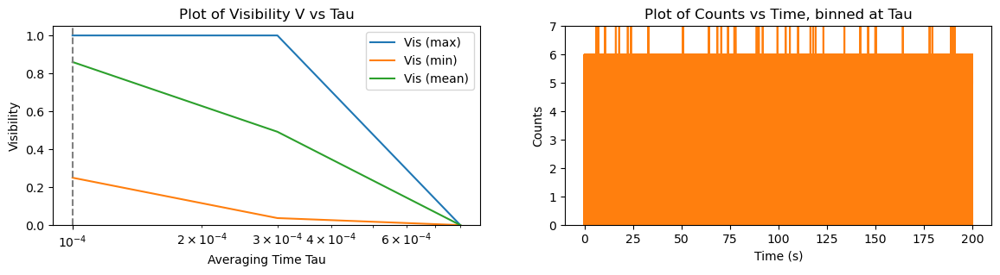

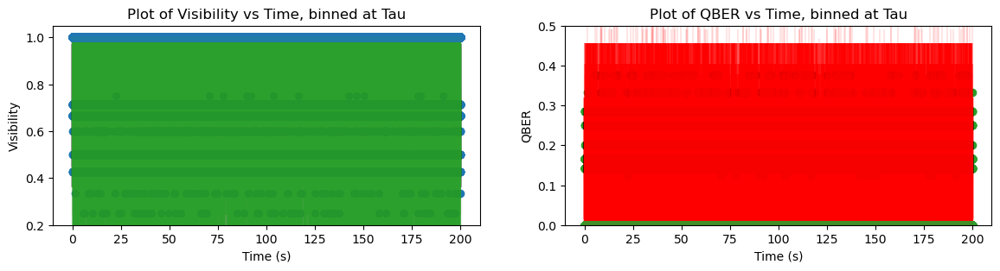

In [162]:
NL_1000_nm_3=Vis.AnalyseMeasurement(NL,4,10,0.0001,0.001,secondhalf=True)

In [17]:
NL_1000_em_3[1][1]

array([5., 5., 6., ..., 4., 5., 4.])

In [21]:
np.save('Data_Rmp1kHz_PhaseAndPowerNoise.npy',(NL_1000_em_3[1][0],NL_1000_em_3[1][1]))

(0.0, 0.2)

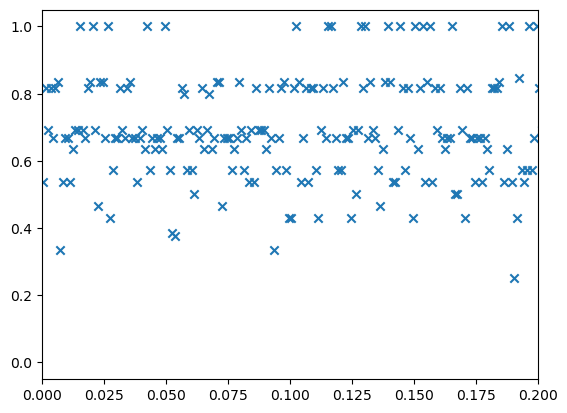

In [47]:
#plt.scatter(NL_1000_em[2][0],NL_1000_em[2][1],marker='x')
plt.scatter(NL_1000_em_2[2][0],NL_1000_em_2[2][1],marker='x')
#plt.scatter(NL_1000_em_3[2][0],NL_1000_em_3[2][1],marker='x')

plt.xlim(0,0.2)

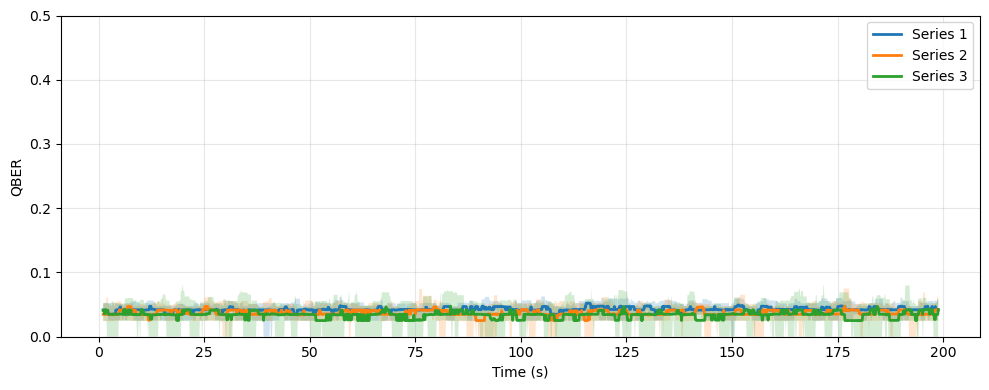

In [240]:
import numpy as np
import matplotlib.pyplot as plt

def rolling_quantile(x, window, q):
    """Simple rolling quantile using stride tricks (fast enough for 2000 pts)."""
    x = np.asarray(x, float)
    n = x.size
    if window < 2 or window > n:
        return np.full(n, np.nan)
    out = np.full(n, np.nan)
    half = window // 2
    for i in range(half, n - half):
        out[i] = np.nanquantile(x[i-half:i+half+1], q)
    return out

def plot_qber_three(
    t,
    q1, q2, q3,
    labels=("Series 1", "Series 2", "Series 3"),
    window=51,
    band=(0.1, 0.9),   # 10–90%
    show_raw=False,
    raw_stride=10,
):
    t = np.asarray(t, float)

    series = [np.asarray(q1, float), np.asarray(q2, float), np.asarray(q3, float)]

    fig, ax = plt.subplots(figsize=(10, 4))

    for y, lab in zip(series, labels):
        med = rolling_quantile(y, window, 0.5)
        lo  = rolling_quantile(y, window, band[0])
        hi  = rolling_quantile(y, window, band[1])

        ax.plot(t, med, label=lab, linewidth=2)
        ax.fill_between(t, lo, hi, alpha=0.2)

        if show_raw:
            ax.plot(t[::raw_stride], y[::raw_stride], alpha=0.07, linewidth=1)

    ax.set_xlabel("Time (s)")
    ax.set_ylabel("QBER")
    ax.set_ylim(0, 0.5)
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

# Usage:
plot_qber_three(NL_10_em[2][0], NL_10_em[2][3], NLF_10_em[2][3], NLVF_10_em[2][3], window=20, show_raw=False)

In [242]:
import numpy as np
import matplotlib.pyplot as plt

def mad_threshold(y, k=4.5):
    """
    Robust high-outlier threshold: median + k * (1.4826*MAD).
    For 1–10% outliers, k ~ 4.0–5.5 is a good range.
    """
    y = np.asarray(y, float)
    med = np.nanmedian(y)
    mad = np.nanmedian(np.abs(y - med))
    sigma = 1.4826 * mad if mad > 0 else 0.0
    return med + k * sigma

def plot_qber_three_with_outliers(
    t, q1, q2, q3,
    labels=("Series 1", "Series 2", "Series 3"),
    k=4.5,
    base_stride=1,          # set to 5 or 10 if you want even less clutter
    base_alpha=0.08,
    marker_size=18,
):
    t = np.asarray(t, float)
    series = [np.asarray(q1, float), np.asarray(q2, float), np.asarray(q3, float)]

    fig, ax = plt.subplots(figsize=(11, 4))

    for y, lab in zip(series, labels):
        # Base trace (keeps all structure but doesn't dominate)
        ax.plot(t[::base_stride], y[::base_stride], linewidth=1, alpha=base_alpha, label=lab)

        # Outliers (high points)
        thr = mad_threshold(y, k=k)
        mask = np.isfinite(y) & (y > thr)

        ax.scatter(t[mask], y[mask], s=marker_size, alpha=0.9)

        # Optional: show threshold level (comment out if you don't want it)
        # ax.hlines(thr, t[0], t[-1], linestyles="dotted", alpha=0.3)

    ax.set_xlabel("Time (s)")
    ax.set_ylabel("QBER")
    ax.set_ylim(0, 0.5)          # adjust if your QBER range differs
    ax.grid(True, alpha=0.25)
    ax.legend()
    plt.tight_layout()
    plt.show()


In [244]:
import numpy as np
import matplotlib.pyplot as plt

def robust_zscore(y):
    """
    Robust z-score using median and MAD.
    z = (y - median) / (1.4826*MAD)
    """
    y = np.asarray(y, float)
    med = np.nanmedian(y)
    mad = np.nanmedian(np.abs(y - med))
    scale = 1.4826 * mad
    if not np.isfinite(scale) or scale == 0:
        # fallback: avoid division by zero; treat as no outliers
        return np.full_like(y, np.nan), med, scale
    z = (y - med) / scale
    return z, med, scale

def plot_qber_three_rare_spikes(
    t, q1, q2, q3,
    labels=("Series 1", "Series 2", "Series 3"),
    z_thr=3.5,
    base_stride=1,        # set 5 or 10 if you want less clutter
    base_alpha=0.08,
    marker_size=20,
):
    t = np.asarray(t, float)
    series = [np.asarray(q1, float), np.asarray(q2, float), np.asarray(q3, float)]

    fig, ax = plt.subplots(figsize=(11, 4))

    for y, lab in zip(series, labels):
        # Base (shows everything, but faint)
        ax.plot(t[::base_stride], y[::base_stride], linewidth=1, alpha=base_alpha, label=lab)

        # Robust outliers
        z, med, scale = robust_zscore(y)
        mask = np.isfinite(z) & (z > z_thr)

        frac = float(np.mean(mask)) if mask.size else 0.0
        print(f"{lab}: median={med:.4f}, MAD*1.4826={scale:.4g}, "
              f"outliers(z>{z_thr}) = {frac*100:.2f}%")

        # Highlight outliers
        ax.scatter(t[mask], y[mask], s=marker_size, alpha=0.9)

    ax.set_xlabel("Time (s)")
    ax.set_ylabel("QBER")
    ax.set_ylim(0, 0.5)       # adjust if needed
    ax.grid(True, alpha=0.25)
    ax.legend()
    plt.tight_layout()
    plt.show()


Series 1: median=0.0370, MAD*1.4826=0.01785, outliers(z>3.5) = 1.05%
Series 2: median=0.0253, MAD*1.4826=0.01877, outliers(z>3.5) = 3.25%
Series 3: median=0.0250, MAD*1.4826=0.01853, outliers(z>3.5) = 7.55%


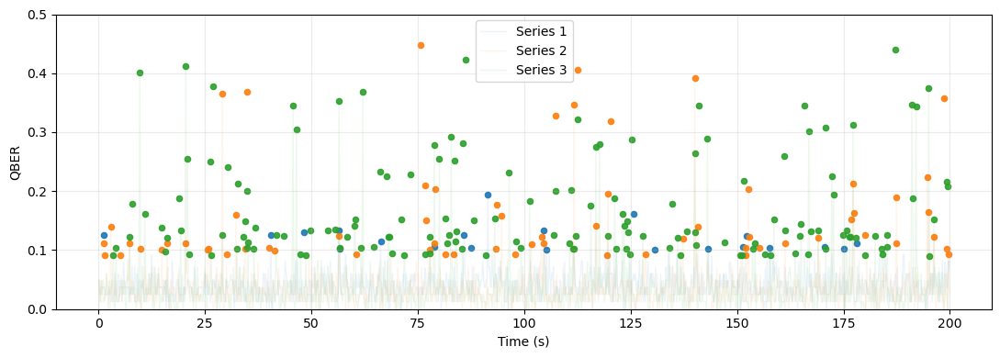

In [246]:
t = np.arange(2000)  # or your actual time array
plot_qber_three_rare_spikes(NL_10_em[2][0], NL_10_em[2][3], NLF_10_em[2][3], NLVF_10_em[2][3], z_thr=3.5, base_stride=2)

In [53]:
Mhz1=Vis.load_measurements(base_dir="D:\PhD Thesis Writing\Data", date_str="2025-11-18", subfolder=r"IdqubeGates\nointerferometer\1mhz", verbose=True)


Loaded 1 measurements from D:\PhD Thesis Writing\Data\2025-11-18\IdqubeGates\nointerferometer\1mhz


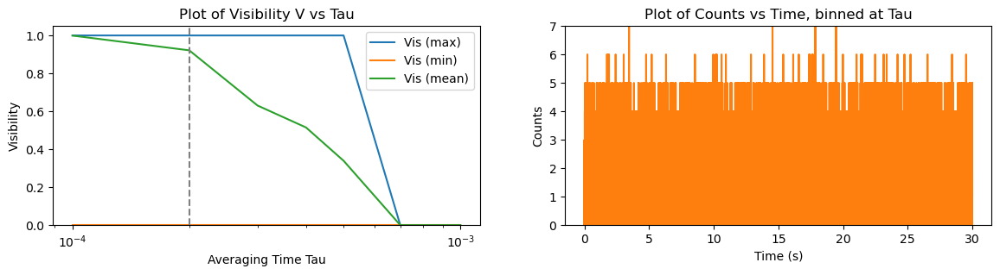

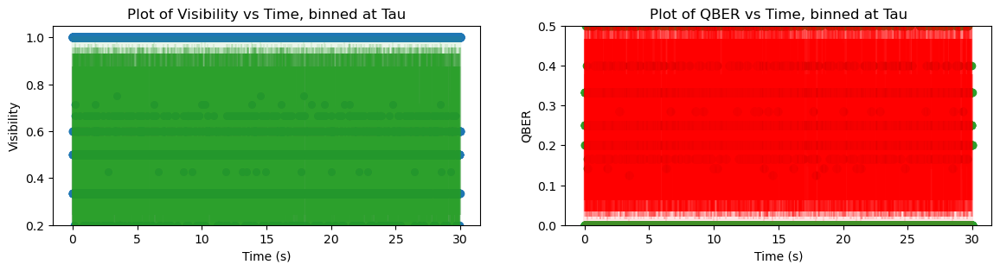

In [93]:
poissoin1mhz=Vis.AnalyseMeasurement(Mhz1,0,50,0.0002,0.001,secondhalf=True)

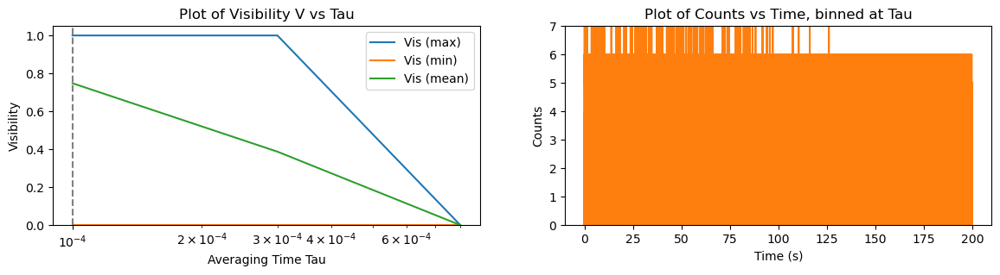

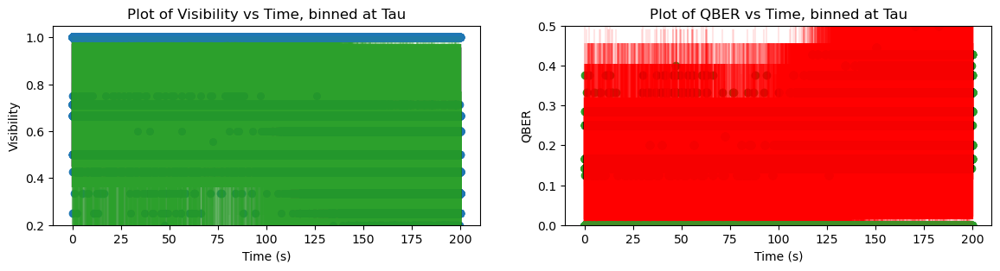

In [5]:
NL_1000_voa_1=Vis.AnalyseMeasurement(NL,0,10,0.0001,0.001,secondhalf=True)

In [7]:
NL_1000_voa_1[1][0]

array([0.000000e+00, 1.000000e-04, 2.000000e-04, ..., 1.999997e+02,
       1.999998e+02, 1.999999e+02])

In [9]:
NL_1000_voa_1[1][1]

array([3., 3., 2., ..., 2., 3., 3.])

In [11]:
np.save('DataTimesCounts.npy', (NL_1000_voa_1[1][0],NL_1000_voa_1[1][1]))

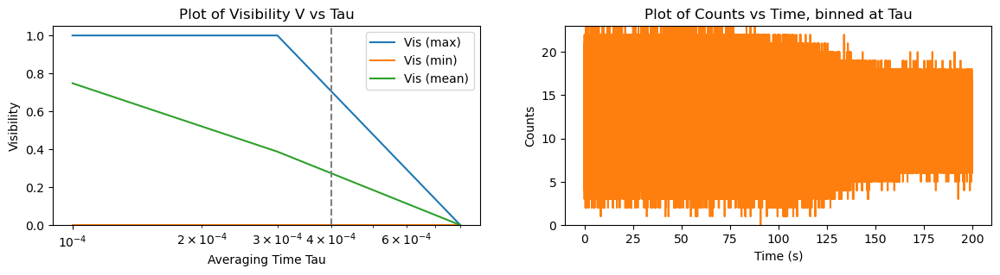

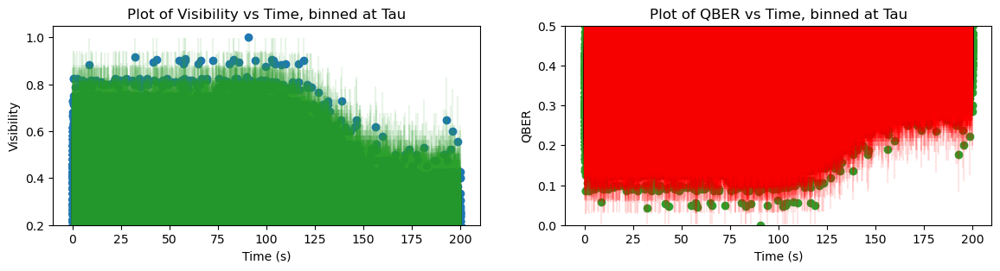

In [87]:
NL_1000_voa_4=Vis.AnalyseMeasurement(NL,0,10,0.0004,0.001,secondhalf=True)

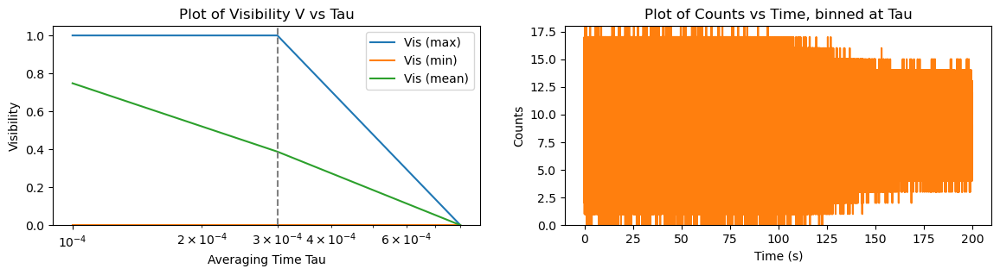

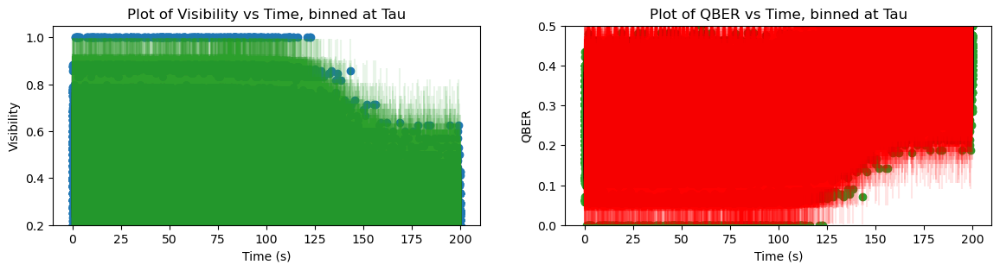

In [88]:
NL_1000_voa_3=Vis.AnalyseMeasurement(NL,0,10,0.0003,0.001,secondhalf=True)

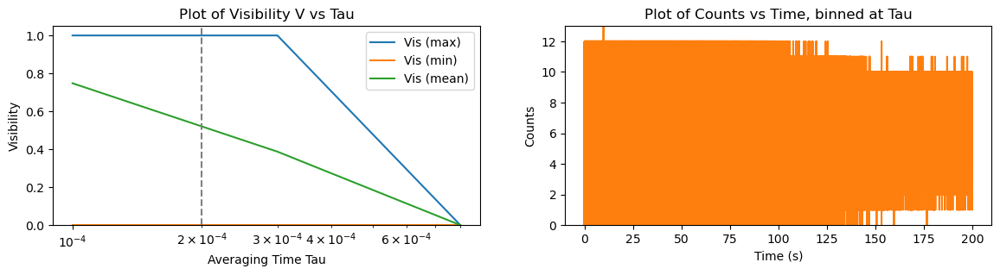

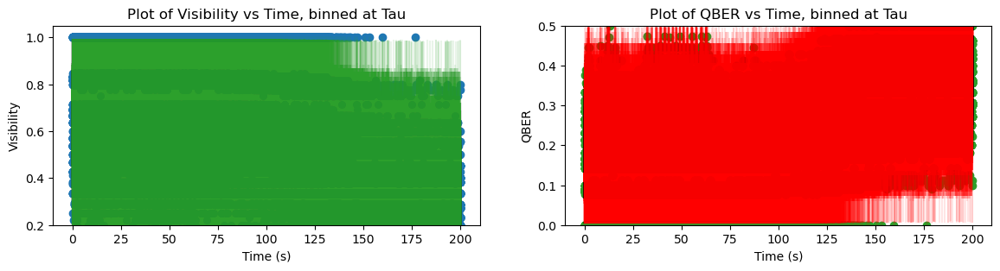

In [90]:
NL_1000_voa_2=Vis.AnalyseMeasurement(NL,0,10,0.0002,0.001,secondhalf=True)

In [67]:
poissoin1mhz

[[array([1.000e-04, 2.000e-04, 3.000e-04, 4.000e-04, 5.000e-04, 7.000e-04,
         8.000e-04, 1.000e-03, 1.200e-03, 1.400e-03, 1.700e-03, 2.000e-03,
         2.400e-03, 2.900e-03, 3.600e-03, 4.300e-03, 5.200e-03, 6.300e-03,
         7.500e-03, 9.100e-03, 1.100e-02, 1.330e-02, 1.600e-02, 1.930e-02,
         2.330e-02, 2.810e-02, 3.390e-02, 4.090e-02, 4.940e-02, 5.960e-02,
         7.200e-02, 8.690e-02, 1.048e-01, 1.265e-01, 1.526e-01, 1.842e-01,
         2.223e-01, 2.683e-01, 3.237e-01, 3.907e-01, 4.715e-01, 5.690e-01,
         6.866e-01, 8.286e-01, 1.000e+00]),
  array([ 1.,  1.,  1.,  1.,  1.,  0.,  0.,  0., nan, nan, nan, nan, nan,
         nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
         nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
         nan, nan, nan, nan, nan, nan]),
  array([ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0., nan, nan, nan, nan, nan,
         nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan,
         nan, nan, n

(0.0, 0.2)

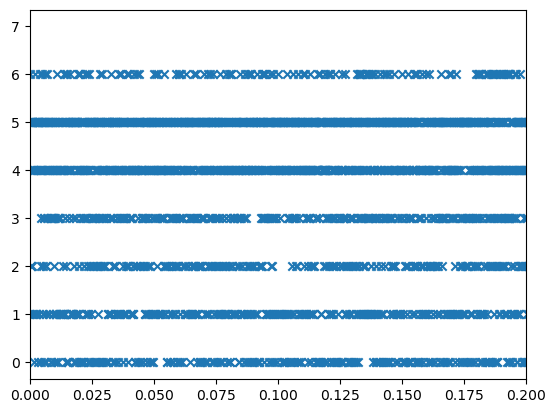

In [79]:
#plt.scatter(poissoin1mhz[1][0],poissoin1mhz[1][1],marker='x')
plt.scatter(NL_1000_em_3[1][0],NL_1000_em_3[1][1],marker='x')

plt.xlim(0,0.2)

In [53]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass
from typing import Optional, Dict, Any, Tuple


# ---------------------------
# Utilities
# ---------------------------

def _cumsum0(a: np.ndarray) -> np.ndarray:
    """Cumulative sum with a leading zero for O(1) range-sum queries."""
    return np.concatenate(([0.0], np.cumsum(a, dtype=float)))


def _h2(p: np.ndarray) -> np.ndarray:
    """Binary entropy (base-2)."""
    p = np.asarray(p, float)
    out = np.zeros_like(p)
    m = (p > 0) & (p < 1)
    out[m] = -(p[m]*np.log2(p[m]) + (1-p[m])*np.log2(1-p[m]))
    return out


@dataclass
class VisibilityTauResult:
    taus: np.ndarray
    n_windows: np.ndarray
    V_max: np.ndarray
    V_min: np.ndarray
    V_mean: np.ndarray
    V_median: np.ndarray
    V_p10: np.ndarray
    V_p90: np.ndarray
    expected_counts_per_window: np.ndarray
    meta: Dict[str, Any]


# ---------------------------
# Core: fast lock-in visibility vs time
# ---------------------------

def lockin_visibility_vs_time_fast(
    ts: np.ndarray,
    counts: np.ndarray,
    f_ramp: float,
    tau: float,
    step: Optional[float] = None,
    phase_offset: float = 0.0,
    n_min: float = 0.0,
    clip: bool = False,
) -> Tuple[np.ndarray, np.ndarray, Dict[str, Any]]:
    """
    Fast lock-in effective visibility in sliding windows.

    Visibility per window:
        V = 2 * sqrt((sum y cos phi)^2 + (sum y sin phi)^2) / (sum y)
    where phi(t) = 2*pi*f_ramp*(t - t0) + phase_offset.

    Returns
    -------
    t_centers : window-center timestamps
    V : visibility estimates per window (NaN if window rejected by n_min or sum y == 0)
    diag : diagnostics dict
    """
    ts = np.asarray(ts, float)
    y  = np.clip(np.nan_to_num(np.asarray(counts, float), nan=0.0), 0, None)
    n = min(ts.size, y.size)
    ts = ts[:n]; y = y[:n]
    if n < 2:
        raise ValueError("Need at least 2 samples.")

    dt = float(np.mean(np.diff(ts)))
    if not np.isfinite(dt) or dt <= 0:
        raise ValueError("Bad timestamps / dt.")

    if step is None:
        step = tau / 2.0
    if tau <= 0 or step <= 0:
        raise ValueError("tau and step must be > 0.")

    K = max(2, int(round(tau / dt)))
    S = max(1, int(round(step / dt)))
    if K > n:
        return np.array([]), np.array([]), {"dt": dt, "K": K, "S": S, "n_windows": 0}

    # Reference phase
    t0 = ts[0]
    phi = 2.0*np.pi*f_ramp*(ts - t0) + phase_offset
    c = np.cos(phi)
    s = np.sin(phi)

    # Prefix sums
    Cy  = _cumsum0(y)
    Cyc = _cumsum0(y * c)
    Cys = _cumsum0(y * s)

    starts = np.arange(0, n - K + 1, S, dtype=int)
    ends = starts + K

    sumy  = Cy[ends]  - Cy[starts]
    sumyc = Cyc[ends] - Cyc[starts]
    sumys = Cys[ends] - Cys[starts]

    V = np.full(starts.size, np.nan, dtype=float)

    good = (sumy >= n_min) & (sumy > 0)
    if np.any(good):
        Vg = 2.0*np.sqrt(sumyc[good]**2 + sumys[good]**2) / sumy[good]
        if clip:
            Vg = np.clip(Vg, 0.0, 1.0)
        V[good] = Vg

    t_centers = ts[starts + (K//2)]

    diag = {
        "dt": dt, "K": int(K), "S": int(S),
        "tau": float(K*dt),
        "step": float(S*dt),
        "n_windows_total": int(starts.size),
        "n_windows_used": int(np.sum(np.isfinite(V))),
        "mean_counts_per_window_used": float(np.nanmean(sumy[good])) if np.any(good) else np.nan,
    }
    return t_centers, V, diag


# ---------------------------
# Sweep tau: Vmax / Vmin / Vmean (+ robust stats)
# ---------------------------

def lockin_visibility_summary_vs_tau(
    ts: np.ndarray,
    counts: np.ndarray,
    f_ramp: float,
    taus: Optional[np.ndarray] = None,
    n_taus: int = 25,
    tau_min: Optional[float] = None,
    tau_max: Optional[float] = None,
    log_bins: bool = True,
    cycles_min: int = 10,     # "trustworthy region" lower bound: tau >= cycles_min / f_ramp
    overlap: float = 0.5,     # step = tau*(1-overlap)
    phase_offset: float = 0.0,
    n_min: float = 50.0,
    clip: bool = False,
) -> VisibilityTauResult:
    """
    Sweep over taus, compute V(t; tau) in sliding windows, and summarize per tau:
    max/min/mean/median + 10–90% band and number of windows.

    If `taus` not provided, creates a grid between tau_min and tau_max.
    """
    ts = np.asarray(ts, float)
    y  = np.clip(np.nan_to_num(np.asarray(counts, float), nan=0.0), 0, None)
    n = min(ts.size, y.size)
    ts = ts[:n]; y = y[:n]
    if n < 2:
        raise ValueError("Need at least 2 samples.")

    dt = float(np.mean(np.diff(ts)))
    duration = float(ts[-1] - ts[0])
    rate = float(np.sum(y) / duration)

    if tau_min is None:
        # at least one cycle and at least one sample
        tau_min = max(dt, 1.0 / f_ramp)
    if tau_max is None:
        tau_max = min(0.5 * duration, 0.2)  # you can override; 0.2 s is a sane default for 1 kHz ramps

    tau_min = float(max(tau_min, dt))
    tau_max = float(max(tau_max, tau_min))

    if taus is None:
        if n_taus <= 1:
            taus = np.array([tau_min], dtype=float)
        else:
            if log_bins:
                taus = np.logspace(np.log10(tau_min), np.log10(tau_max), n_taus)
            else:
                taus = np.linspace(tau_min, tau_max, n_taus)
        taus = np.unique(taus.astype(float))

    # Step is set from overlap fraction
    if not (0.0 <= overlap < 1.0):
        raise ValueError("overlap must be in [0,1).")
    steps = taus * (1.0 - overlap)

    V_max = np.full(taus.size, np.nan)
    V_min = np.full(taus.size, np.nan)
    V_mean = np.full(taus.size, np.nan)
    V_median = np.full(taus.size, np.nan)
    V_p10 = np.full(taus.size, np.nan)
    V_p90 = np.full(taus.size, np.nan)
    n_windows = np.zeros(taus.size, dtype=int)

    for i, (tau, step) in enumerate(zip(taus, steps)):
        tcent, Vt, _ = lockin_visibility_vs_time_fast(
            ts, y, f_ramp=f_ramp, tau=float(tau), step=float(step),
            phase_offset=phase_offset, n_min=n_min, clip=clip
        )
        Vt = Vt[np.isfinite(Vt)]
        n_windows[i] = int(Vt.size)
        if Vt.size == 0:
            continue
        V_max[i] = float(np.max(Vt))
        V_min[i] = float(np.min(Vt))
        V_mean[i] = float(np.mean(Vt))
        V_median[i] = float(np.median(Vt))
        V_p10[i] = float(np.quantile(Vt, 0.10))
        V_p90[i] = float(np.quantile(Vt, 0.90))

    expected_counts = rate * taus
    meta = {
        "dt": dt,
        "duration_s": duration,
        "rate_counts_per_s": rate,
        "cycles_min": cycles_min,
        "trust_tau_min_s": cycles_min / f_ramp,
        "overlap": overlap,
        "n_min_counts_per_window": n_min,
        "clip": clip,
    }
    return VisibilityTauResult(
        taus=taus,
        n_windows=n_windows,
        V_max=V_max,
        V_min=V_min,
        V_mean=V_mean,
        V_median=V_median,
        V_p10=V_p10,
        V_p90=V_p90,
        expected_counts_per_window=expected_counts,
        meta=meta
    )


# ---------------------------
# Choose operating tau + estimate "knee"
# ---------------------------

def choose_operating_tau(
    res: VisibilityTauResult,
    f_ramp: float,
    cycles_min: int = 10,
    within_frac: float = 0.98,
    use: str = "median",
) -> float:
    """
    Choose smallest tau >= cycles_min/f_ramp with statistic within `within_frac` of plateau (max in that region).
    `use` can be 'median' or 'mean'.
    """
    taus = res.taus
    stat = res.V_median if use == "median" else res.V_mean

    trust = (taus >= (cycles_min / f_ramp)) & np.isfinite(stat)
    if not np.any(trust):
        return float("nan")
    plateau = float(np.max(stat[trust]))
    ok = trust & (stat >= within_frac * plateau)
    if not np.any(ok):
        return float("nan")
    return float(np.min(taus[ok]))


def estimate_knee_tau(
    res: VisibilityTauResult,
    f_ramp: float,
    cycles_min: int = 10,
    drop_frac: float = 0.95,
    use: str = "median",
) -> float:
    """
    Find first tau (>= cycles_min/f_ramp) where statistic falls below drop_frac * plateau.
    """
    taus = res.taus
    stat = res.V_median if use == "median" else res.V_mean

    trust = (taus >= (cycles_min / f_ramp)) & np.isfinite(stat)
    if not np.any(trust):
        return float("nan")
    plateau = float(np.max(stat[trust]))
    thresh = drop_frac * plateau
    for i in np.where(trust)[0]:
        if stat[i] < thresh:
            return float(taus[i])
    return float("nan")


# ---------------------------
# Plotting helpers
# ---------------------------

def plot_visibility_vs_tau(res: VisibilityTauResult, title: str = "Effective Visibility vs Tau") -> None:
    taus = res.taus
    m = np.isfinite(res.V_mean)

    plt.figure(figsize=(9, 4))
    plt.plot(taus[m], res.V_mean[m], label="Vmean")
    plt.plot(taus[m], res.V_median[m], label="Vmedian")
    plt.plot(taus[m], res.V_max[m], label="Vmax")
    plt.plot(taus[m], res.V_min[m], label="Vmin")
    plt.fill_between(taus[m], res.V_p10[m], res.V_p90[m], alpha=0.2, label="10–90% band")
    plt.xscale("log")
    plt.ylim(0, 2)
    plt.xlabel("Tau (s)")
    plt.ylabel("Effective visibility")
    plt.title(title)
    plt.grid(True, alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()


def plot_qber_and_secret_proxy(res: VisibilityTauResult, title_prefix: str = "") -> None:
    taus = res.taus

    # QBER mapping from visibility; clip to [0,1] for physical mapping
    Vmax_c = np.clip(res.V_max, 0, 1)
    Vmean_c = np.clip(res.V_mean, 0, 1)
    Vmin_c  = np.clip(res.V_min,  0, 1)
    Qmax = 0.5 * (1 - Vmax_c)
    Qmean = 0.5 * (1 - Vmean_c)
    Qworst = 0.5 * (1 - Vmin_c)

    m = np.isfinite(Qmean)

    plt.figure(figsize=(9, 4))
    plt.plot(taus[m], Qmax[m], label="QBER from Vmax")
    plt.plot(taus[m], Qmean[m], label="QBER from Vmean")
    plt.plot(taus[m], Qworst[m], label="QBER from Vmin")
    plt.xscale("log")
    plt.ylim(0, 0.5)
    plt.xlabel("Tau (s)")
    plt.ylabel("Estimated QBER")
    plt.title((title_prefix + " " if title_prefix else "") + "QBER vs Tau (from visibility)")
    plt.grid(True, alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Illustrative secret fraction proxy (NOT TF-QKD key rate; just sanity proxy)
    s_max  = np.maximum(0.0, 1.0 - 2.0*_h2(Qmax))
    s_mean  = np.maximum(0.0, 1.0 - 2.0*_h2(Qmean))
    s_worst = np.maximum(0.0, 1.0 - 2.0*_h2(Qworst))

    m2 = np.isfinite(s_mean)

    plt.figure(figsize=(9, 4))
    plt.plot(taus[m2], s_max[m2], label="Secret fraction proxy (from Vmax)")
    plt.plot(taus[m2], s_mean[m2], label="Secret fraction proxy (from Vmean)")
    plt.plot(taus[m2], s_worst[m2], label="Secret fraction proxy (from Vmin)")
    plt.xscale("log")
    plt.ylim(0, 1.0)
    plt.xlabel("Tau (s)")
    plt.ylabel("Illustrative secret fraction")
    plt.title((title_prefix + " " if title_prefix else "") + "Secret-fraction proxy vs Tau")
    plt.grid(True, alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()


def plot_visibility_time_series_at_tau(
    ts: np.ndarray,
    counts: np.ndarray,
    f_ramp: float,
    tau: float,
    overlap: float = 0.5,
    phase_offset: float = 0.0,
    n_min: float = 50.0,
    clip_for_qber: bool = True,
    max_points: int = 5000,
) -> None:
    """
    Plot V(t) and QBER(t) at a chosen tau.
    """
    step = tau * (1.0 - overlap)
    tcent, Vt, diag = lockin_visibility_vs_time_fast(
        ts, counts, f_ramp=f_ramp, tau=tau, step=step,
        phase_offset=phase_offset, n_min=n_min, clip=False
    )

    # Downsample for display
    if tcent.size > max_points:
        ds = int(np.ceil(tcent.size / max_points))
    else:
        ds = 1

    plt.figure(figsize=(10, 4))
    plt.plot(tcent[::ds], Vt[::ds], linewidth=1)
    plt.ylim(0, 1.3)
    plt.xlabel("Time (s)")
    plt.ylabel(f"V(t) at tau ≈ {tau*1e3:.2f} ms")
    plt.title("Visibility vs time (selected tau)")
    plt.grid(True, alpha=0.25)
    plt.tight_layout()
    plt.show()

    Vc = np.clip(Vt, 0, 1) if clip_for_qber else Vt
    Q = 0.5 * (1 - Vc)

    plt.figure(figsize=(10, 4))
    plt.plot(tcent[::ds], Q[::ds], linewidth=1)
    plt.ylim(0, 0.5)
    plt.xlabel("Time (s)")
    plt.ylabel(f"QBER(t) at tau ≈ {tau*1e3:.2f} ms")
    plt.title("QBER vs time (from visibility)")
    plt.grid(True, alpha=0.25)
    plt.tight_layout()
    plt.show()

    print("[Selected tau diagnostics]")
    print(diag)
    finite = np.isfinite(Vt)
    if np.any(finite):
        print("V median:", float(np.nanmedian(Vt)))
        print("V mean:  ", float(np.nanmean(Vt)))
        print("V 10–90%:", float(np.nanquantile(Vt, 0.10)), "…", float(np.nanquantile(Vt, 0.90)))

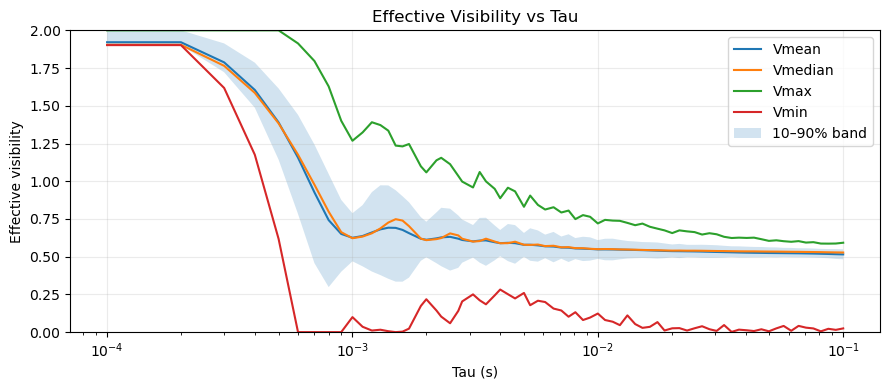

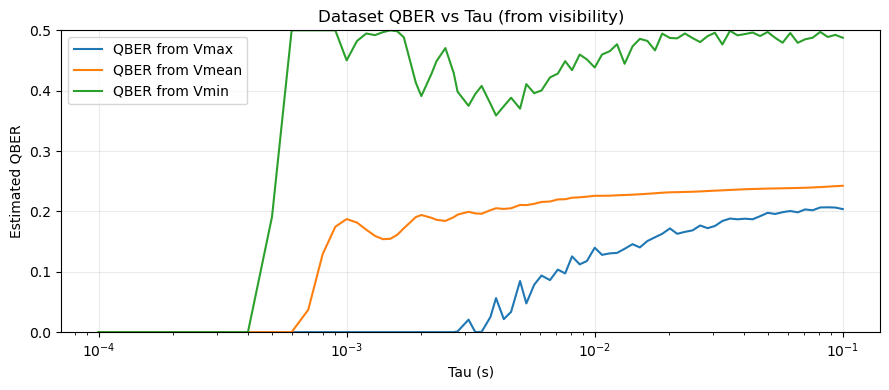

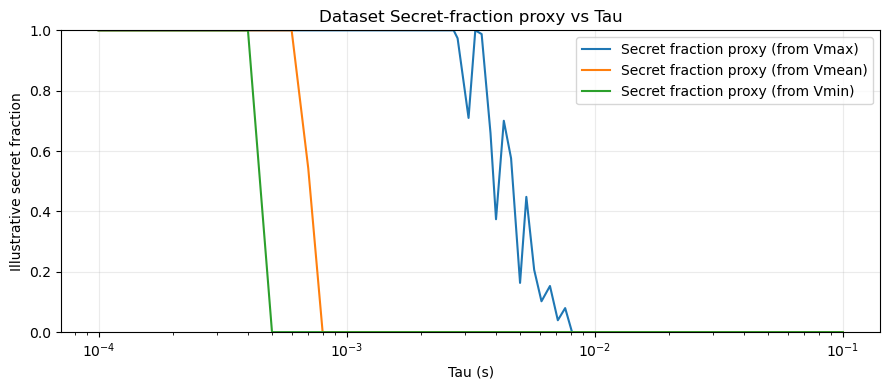

In [198]:

# ---------------------------
# Example usage
# ---------------------------
if __name__ == "__main__":
    # Example: load your npy which stores (ts, counts)
    ts, counts = NL_1000_em_3[1][0],NL_1000_em_3[1][1]

    # Set your ramp frequency
    f_ramp = 1000.0
    dt = np.mean(np.diff(ts))
    tau_min = 1e-4
    tau_max = 0.1
    n_taus = 100

    K_min = int(np.ceil(tau_min / dt))
    K_max = int(np.floor(tau_max / dt))

    Ks = np.unique(
        np.round(
            np.logspace(
                np.log10(K_min),
                np.log10(K_max),
                n_taus
            )
        ).astype(int)
    )

    taus = Ks * dt
    # Run tau sweep
    res = lockin_visibility_summary_vs_tau(ts, counts, f_ramp=f_ramp, taus=taus,overlap=0.5, n_min=0, clip=False)

    # Plot results
    plot_visibility_vs_tau(res)
    plot_qber_and_secret_proxy(res, title_prefix="Dataset")

Operating tau (s): 0.0015
Knee tau mean (s): 0.001
Knee tau median (s): 0.001


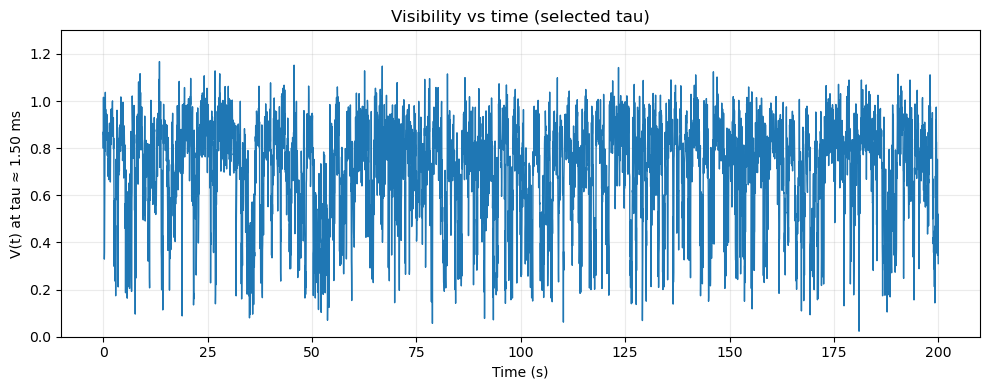

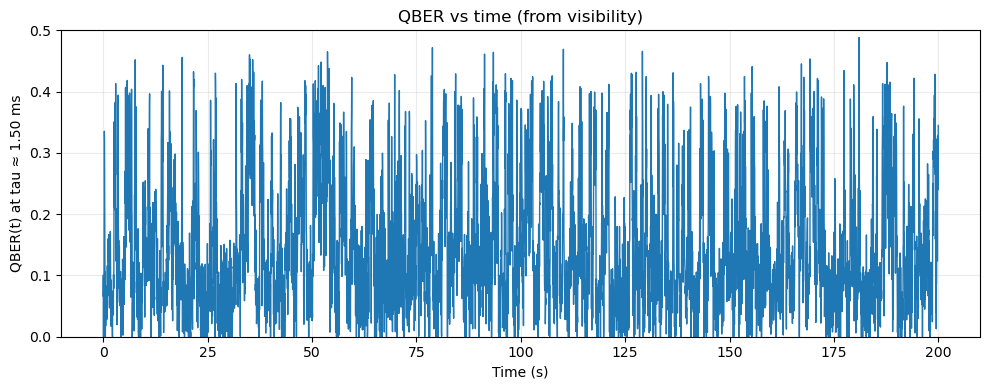

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 15, 'S': 8, 'tau': 0.0015, 'step': 0.0008, 'n_windows_total': 249999, 'n_windows_used': 249999, 'mean_counts_per_window_used': 51.8559554238217}
V median: 0.7484156417650543
V mean:   0.6908359637389557
V 10–90%: 0.3346379331302837 … 0.940346607843502


In [202]:

# ---------------------------
# Example usage
# ---------------------------
if __name__ == "__main__":
    # Choose operating tau and knee
    tau_op = choose_operating_tau(res, f_ramp=f_ramp, cycles_min=1, within_frac=0.99, use="median")
    tau_knee_mean = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=1, drop_frac=0.999, use="mean")
    tau_knee_med  = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=1, drop_frac=0.999, use="median")
    print("Operating tau (s):", tau_op)
    print("Knee tau mean (s):", tau_knee_mean)
    print("Knee tau median (s):", tau_knee_med)

    #Plot time series at operating tau
    plot_visibility_time_series_at_tau(ts, counts, f_ramp=f_ramp, tau=tau_op, overlap=0.5, n_min=0)
    pass

In [63]:
import numpy as np
import matplotlib.pyplot as plt

def annotate_tau_regimes(res, *,
                         f_ramp,
                         cycles_min=10,
                         min_counts_per_window=100,
                         width_threshold=0.25,
                         use_counts=True):
    """
    Returns a dict with masks:
      - poisson_like: likely Poisson/estimator-dominated (unreliable)
      - physical_like: more interpretable (enough counts + stable band)
    Heuristics:
      - tau >= cycles_min / f_ramp  (phase coverage)
      - expected_counts_per_window >= min_counts_per_window
      - band width (P90-P10) <= width_threshold
    """
    taus = res.taus
    width = res.V_p90 - res.V_p10

    phase_ok = taus >= (cycles_min / f_ramp)
    width_ok = np.isfinite(width) & (width <= width_threshold)

    if use_counts:
        cnt_ok = np.isfinite(res.expected_counts_per_window) & (res.expected_counts_per_window >= min_counts_per_window)
    else:
        cnt_ok = np.ones_like(taus, dtype=bool)

    physical_like = phase_ok & cnt_ok & width_ok
    poisson_like = ~physical_like

    return {
        "width": width,
        "phase_ok": phase_ok,
        "cnt_ok": cnt_ok,
        "width_ok": width_ok,
        "physical_like": physical_like,
        "poisson_like": poisson_like
    }

def plot_visibility_vs_tau_with_regimes(res, regimes, title="Effective Visibility vs Tau"):
    taus = res.taus
    m = np.isfinite(res.V_mean)

    plt.figure(figsize=(9,4))
    plt.plot(taus[m], res.V_mean[m], label="Vmean")
    plt.plot(taus[m], res.V_median[m], label="Vmedian")
    plt.fill_between(taus[m], res.V_p10[m], res.V_p90[m], alpha=0.2, label="10–90% band")

    # Shade likely “unreliable” region(s)
    bad = regimes["poisson_like"] & np.isfinite(taus)
    if np.any(bad):
        # Shade continuous spans
        idx = np.where(bad)[0]
        # find contiguous blocks
        blocks = np.split(idx, np.where(np.diff(idx) != 1)[0] + 1)
        for b in blocks:
            plt.axvspan(taus[b[0]], taus[b[-1]], alpha=0.08)

    plt.xscale("log")
    plt.ylim(0, 1.3)
    plt.xlabel("Tau (s)")
    plt.ylabel("Effective visibility")
    plt.title(title + " (shaded = likely Poisson/estimator dominated)")
    plt.grid(True, alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()

def plot_bandwidth_vs_tau(res, regimes, title="Stability (10–90% width) vs Tau"):
    taus = res.taus
    w = regimes["width"]
    m = np.isfinite(w)

    plt.figure(figsize=(9,4))
    plt.plot(taus[m], w[m], label="P90 - P10")
    plt.xscale("log")
    plt.xlabel("Tau (s)")
    plt.ylabel("10–90% band width")
    plt.title(title)
    plt.grid(True, alpha=0.25)
    plt.tight_layout()
    plt.show()


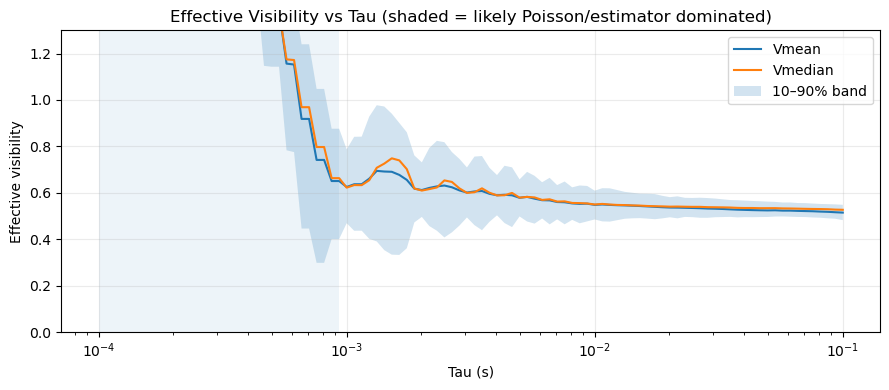

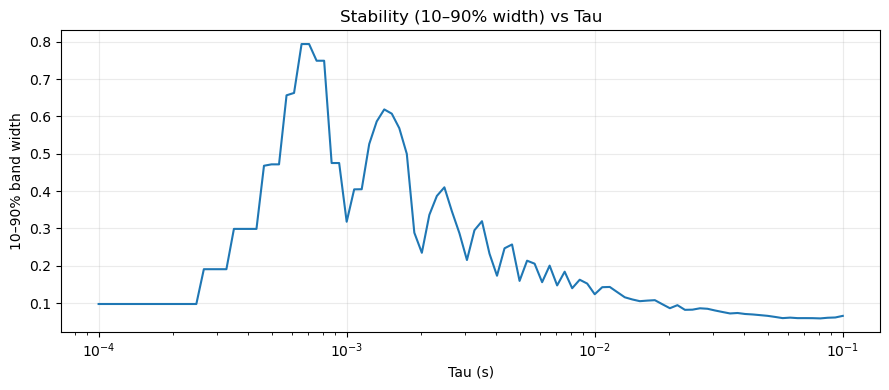

In [100]:
reg = annotate_tau_regimes(res, f_ramp=1000.0,
                           cycles_min=1,
                           min_counts_per_window=0,
                           width_threshold=0.99)

plot_visibility_vs_tau_with_regimes(res, reg)
plot_bandwidth_vs_tau(res, reg)

In [ ]:
NL_1000_voa_1[1][0],NL_1000_voa_1[1][1]

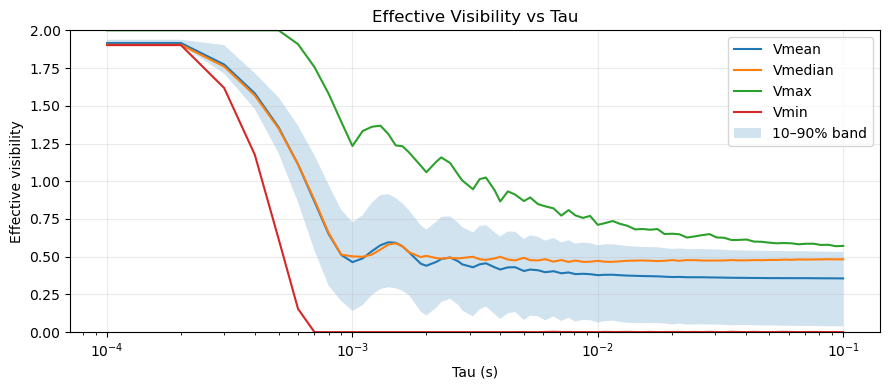

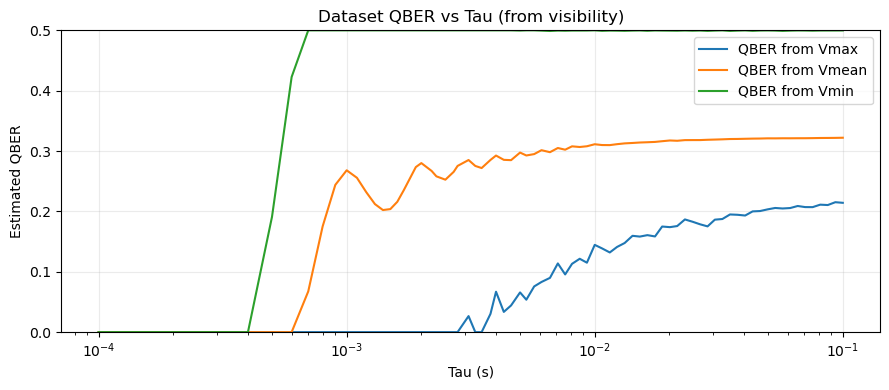

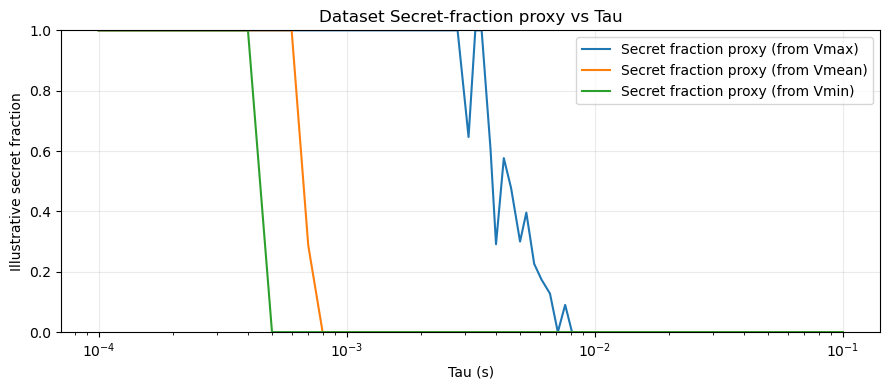

In [204]:
if __name__ == "__main__":
    # Example: load your npy which stores (ts, counts)
    ts, counts = NL_1000_voa_1[1][0],NL_1000_voa_1[1][1]

    # Set your ramp frequency
    f_ramp = 1000.0
    dt = np.mean(np.diff(ts))
    tau_min = 1e-4
    tau_max = 0.1
    n_taus = 100

    K_min = int(np.ceil(tau_min / dt))
    K_max = int(np.floor(tau_max / dt))

    Ks = np.unique(
        np.round(
            np.logspace(
                np.log10(K_min),
                np.log10(K_max),
                n_taus
            )
        ).astype(int)
    )

    taus = Ks * dt
    # Run tau sweep
    res = lockin_visibility_summary_vs_tau(ts, counts, f_ramp=f_ramp, taus=taus,overlap=0.5, n_min=0, clip=False)

    # Plot results
    plot_visibility_vs_tau(res)
    plot_qber_and_secret_proxy(res, title_prefix="Dataset")

Operating tau (s): 0.0142
Knee tau mean (s): 0.0327
Knee tau median (s): nan


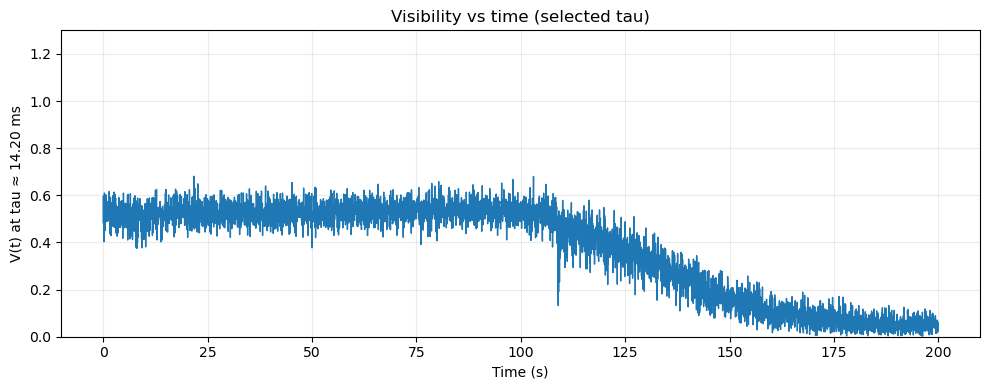

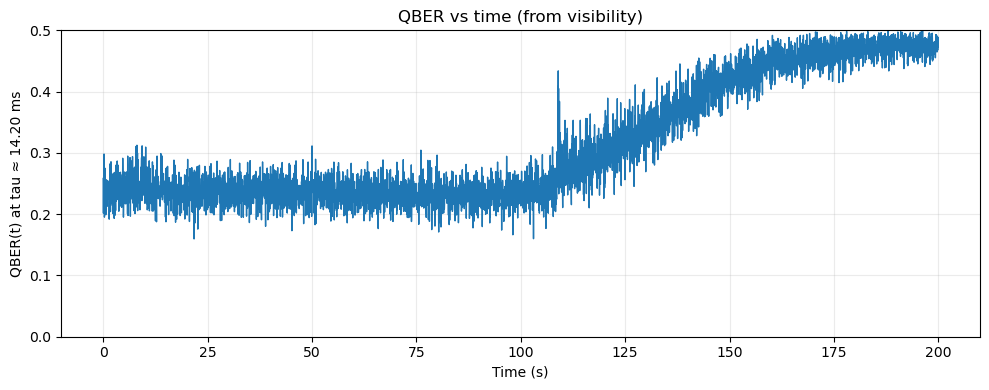

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 142, 'S': 71, 'tau': 0.0142, 'step': 0.0071, 'n_windows_total': 28168, 'n_windows_used': 28168, 'mean_counts_per_window_used': 471.74101817665434}
V median: 0.474026331818614
V mean:   0.3732241429610407
V 10–90%: 0.06065128856254512 … 0.5669465730953955


In [216]:
if __name__ == "__main__":
    # Choose operating tau and knee
    tau_op = choose_operating_tau(res, f_ramp=f_ramp, cycles_min=10, within_frac=0.98, use="median")
    tau_knee_mean = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=10, drop_frac=0.95, use="mean")
    tau_knee_med  = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=10, drop_frac=0.95, use="median")
    print("Operating tau (s):", tau_op)
    print("Knee tau mean (s):", tau_knee_mean)
    print("Knee tau median (s):", tau_knee_med)

    #Plot time series at operating tau
    plot_visibility_time_series_at_tau(ts, counts, f_ramp=f_ramp, tau=tau_op, overlap=0.5, n_min=0)
    pass

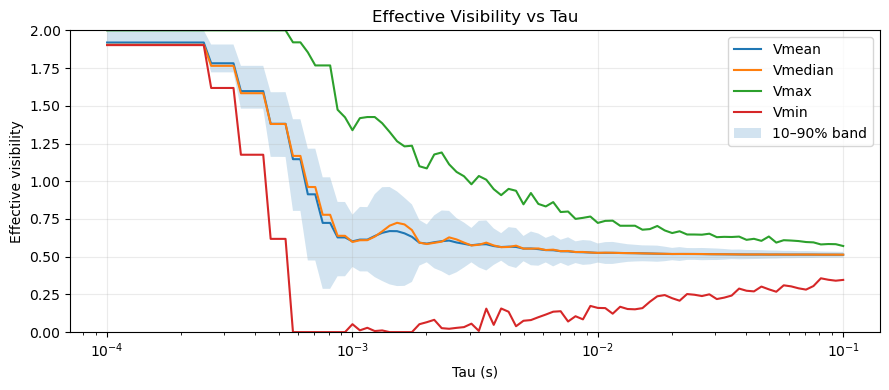

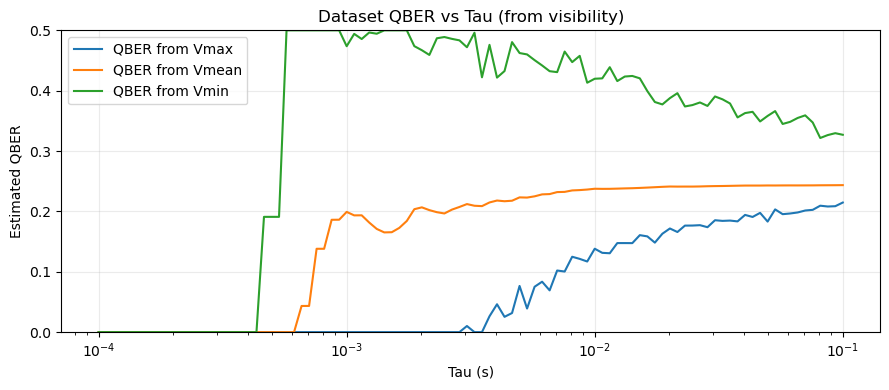

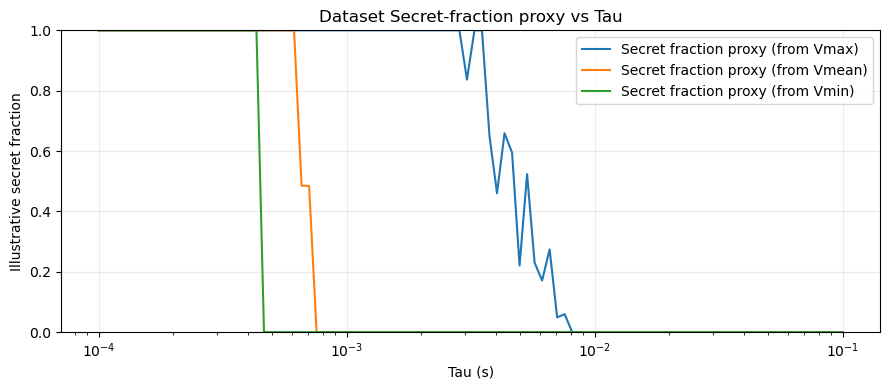

Operating tau (s): 0.0015199110829529332
Knee tau mean (s): 0.001
Knee tau median (s): 0.001


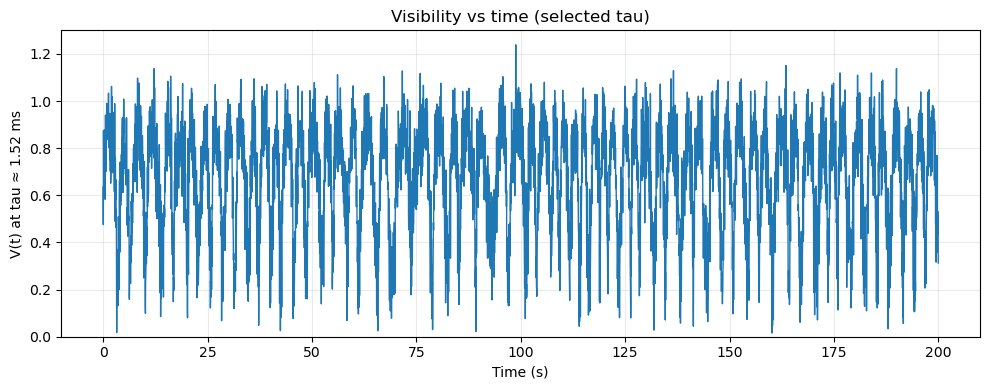

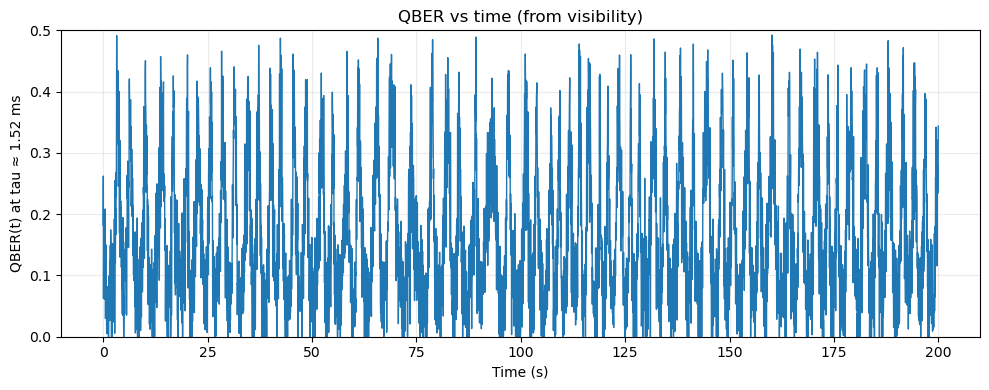

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 15, 'S': 8, 'tau': 0.0015, 'step': 0.0008, 'n_windows_total': 249999, 'n_windows_used': 249999, 'mean_counts_per_window_used': 48.74093496373985}
V median: 0.7244348115047323
V mean:   0.6689428290793458
V 10–90%: 0.3052526799538475 … 0.9322259306073282


In [166]:
if __name__ == "__main__":
    # Example: load your npy which stores (ts, counts)
    ts, counts = NL_1000_nm_3[1][0],NL_1000_nm_3[1][1]

    # Set your ramp frequency
    f_ramp = 1000.0
    dt = np.mean(np.diff(ts))
    tau_min = 1e-4
    tau_max = 0.1
    n_taus = 100

    K_min = int(np.ceil(tau_min / dt))
    K_max = int(np.floor(tau_max / dt))

    Ks = np.unique(
        np.round(
            np.logspace(
                np.log10(K_min),
                np.log10(K_max),
                n_taus
            )
        ).astype(int)
    )

    taus = Ks * dt
    # Run tau sweep
    res = lockin_visibility_summary_vs_tau(ts, counts, f_ramp=f_ramp, taus=taus,overlap=0.5, n_min=0, clip=False)

    # Plot results
    plot_visibility_vs_tau(res)
    plot_qber_and_secret_proxy(res, title_prefix="Dataset")
    # Choose operating tau and knee
    tau_op = choose_operating_tau(res, f_ramp=f_ramp, cycles_min=1, within_frac=0.98, use="median")
    tau_knee_mean = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=1, drop_frac=0.95, use="mean")
    tau_knee_med  = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=1, drop_frac=0.95, use="median")
    print("Operating tau (s):", tau_op)
    print("Knee tau mean (s):", tau_knee_mean)
    print("Knee tau median (s):", tau_knee_med)

    #Plot time series at operating tau
    plot_visibility_time_series_at_tau(ts, counts, f_ramp=f_ramp, tau=tau_op, overlap=0.5, n_min=0)
    pass

Operating tau (s): 0.0015199110829529332
Knee tau mean (s): 0.001
Knee tau median (s): 0.001


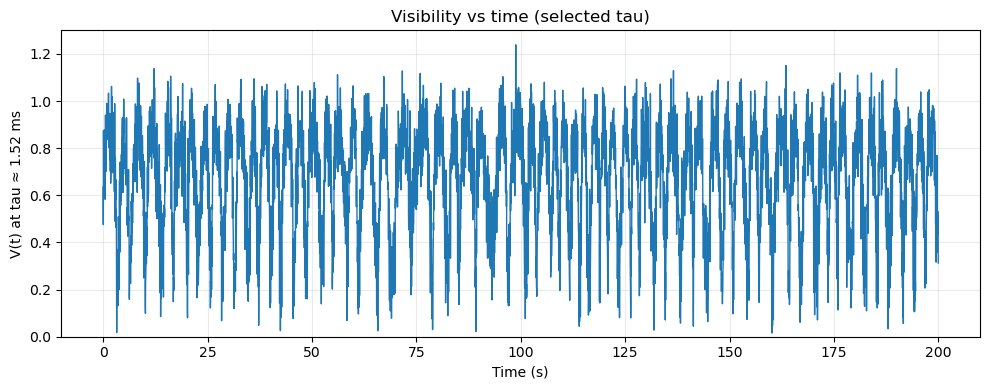

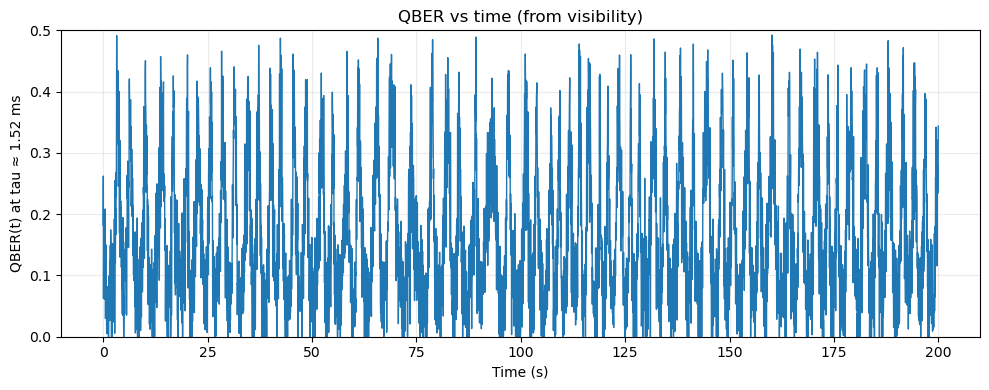

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 15, 'S': 8, 'tau': 0.0015, 'step': 0.0008, 'n_windows_total': 249999, 'n_windows_used': 249999, 'mean_counts_per_window_used': 48.74093496373985}
V median: 0.7244348115047323
V mean:   0.6689428290793458
V 10–90%: 0.3052526799538475 … 0.9322259306073282


In [192]:
if __name__ == "__main__":
    # Choose operating tau and knee
    tau_op = choose_operating_tau(res, f_ramp=f_ramp, cycles_min=1, within_frac=0.98, use="median")
    tau_knee_mean = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=1, drop_frac=0.95, use="mean")
    tau_knee_med  = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=1, drop_frac=0.95, use="median")
    print("Operating tau (s):", tau_op)
    print("Knee tau mean (s):", tau_knee_mean)
    print("Knee tau median (s):", tau_knee_med)

    #Plot time series at operating tau
    plot_visibility_time_series_at_tau(ts, counts, f_ramp=f_ramp, tau=tau_op, overlap=0.5, n_min=0)
    pass

In [194]:
res

VisibilityTauResult(taus=array([0.0001    , 0.00010723, 0.00011498, 0.00012328, 0.00013219,
       0.00014175, 0.00015199, 0.00016298, 0.00017475, 0.00018738,
       0.00020092, 0.00021544, 0.00023101, 0.00024771, 0.00026561,
       0.0002848 , 0.00030539, 0.00032745, 0.00035112, 0.00037649,
       0.0004037 , 0.00043288, 0.00046416, 0.0004977 , 0.00053367,
       0.00057224, 0.00061359, 0.00065793, 0.00070548, 0.00075646,
       0.00081113, 0.00086975, 0.0009326 , 0.001     , 0.00107227,
       0.00114976, 0.00123285, 0.00132194, 0.00141747, 0.00151991,
       0.00162975, 0.00174753, 0.00187382, 0.00200923, 0.00215443,
       0.00231013, 0.00247708, 0.00265609, 0.00284804, 0.00305386,
       0.00327455, 0.00351119, 0.00376494, 0.00403702, 0.00432876,
       0.00464159, 0.00497702, 0.0053367 , 0.00572237, 0.00613591,
       0.00657933, 0.0070548 , 0.00756463, 0.00811131, 0.00869749,
       0.00932603, 0.01      , 0.01072267, 0.01149757, 0.01232847,
       0.01321941, 0.01417474, 0.0151

In [334]:
NL[5]

{'name': 'Night_2_1MhzGate_158uWperArm_Rmp100Hz_nomodulation',
 'timestamp': datetime.datetime(2025, 11, 28, 17, 50, 45, tzinfo=datetime.timezone.utc),
 'npz_path': 'D:\\PhD Thesis Writing\\Data\\2025-11-28\\Night2Long\\Night_2_1MhzGate_158uWperArm_Rmp100Hz_nomodulation_20251128T175045+0000.npz',
 'csv_path': 'D:\\PhD Thesis Writing\\Data\\2025-11-28\\Night2Long\\Night_2_1MhzGate_158uWperArm_Rmp100Hz_nomodulation_20251128T175045+0000.csv',
 'meta_path': 'D:\\PhD Thesis Writing\\Data\\2025-11-28\\Night2Long\\Night_2_1MhzGate_158uWperArm_Rmp100Hz_nomodulation_20251128T175045+0000_meta.txt',
 'data': {'timestamps': array(['2025-11-28T17:50:45.532625000', '2025-11-28T17:50:45.532725000',
         '2025-11-28T17:50:45.532825000', ...,
         '2025-11-28T17:54:05.532325000', '2025-11-28T17:54:05.532425000',
         '2025-11-28T17:54:05.532525000'], dtype='datetime64[ns]'),
  'counts': array([3, 5, 5, ..., 1, 1, 1], dtype=uint32),
  'voa_volts': array([2.6, 2.6, 2.6, ..., 2.6, 2.6, 2.6]),


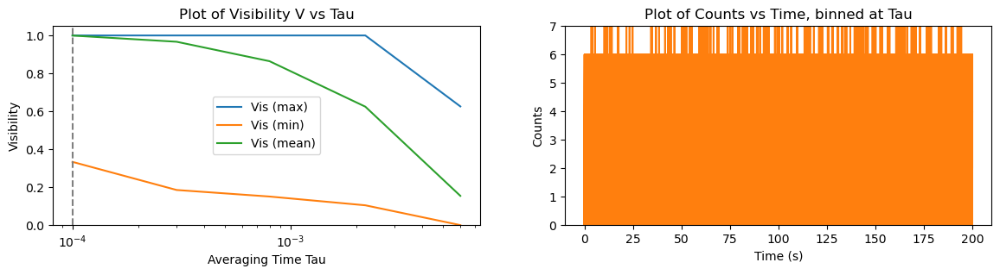

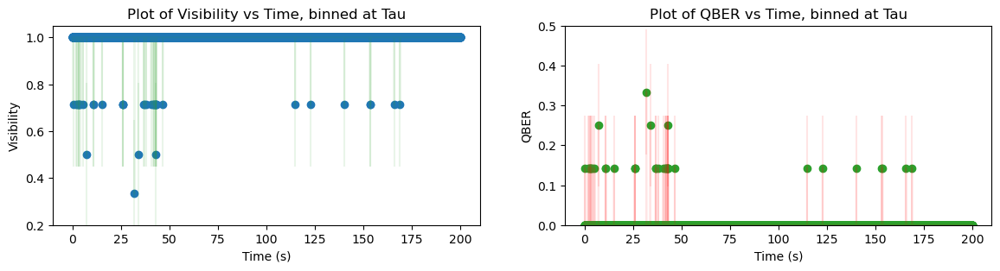

In [310]:
NL_100_em=Vis.AnalyseMeasurement(NL,9,10,0.0001,0.01,secondhalf=True)

In [494]:
NL_100_nm=Vis.AnalyseMeasurement(NL,5,20,0.0005,0.01,secondhalf=True)

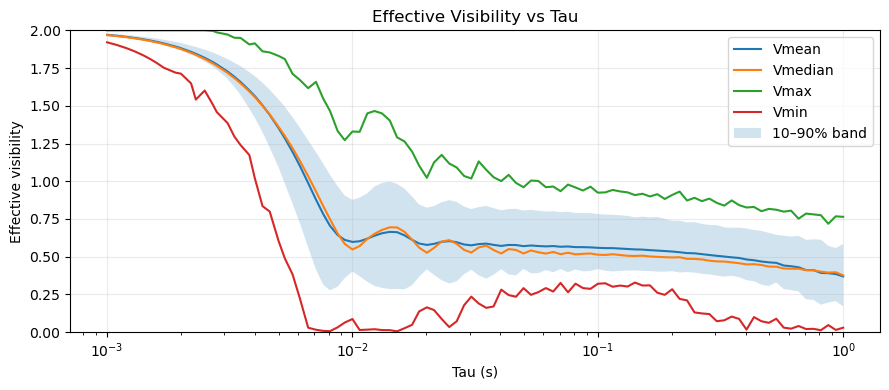

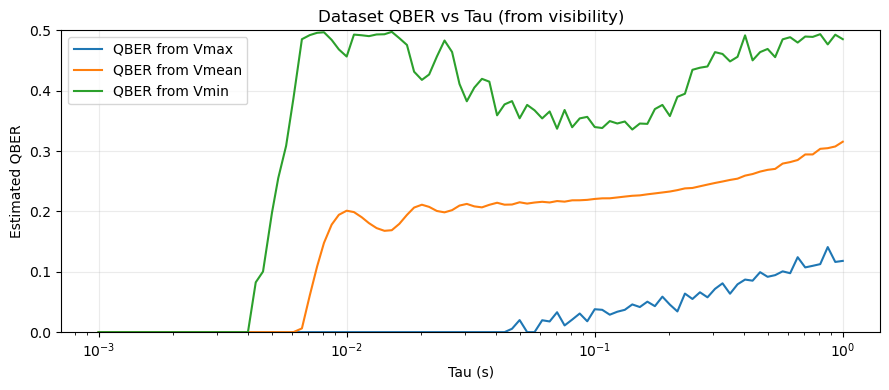

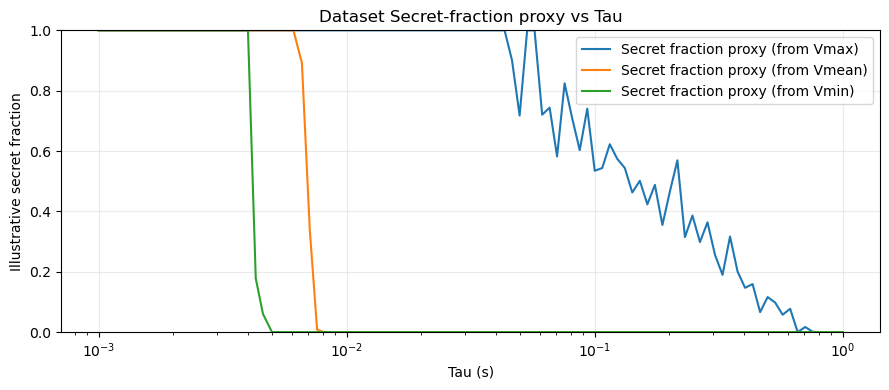

Operating tau (s): 0.0081
Knee tau mean (s): 0.008700000000000001
Knee tau median (s): 0.008700000000000001


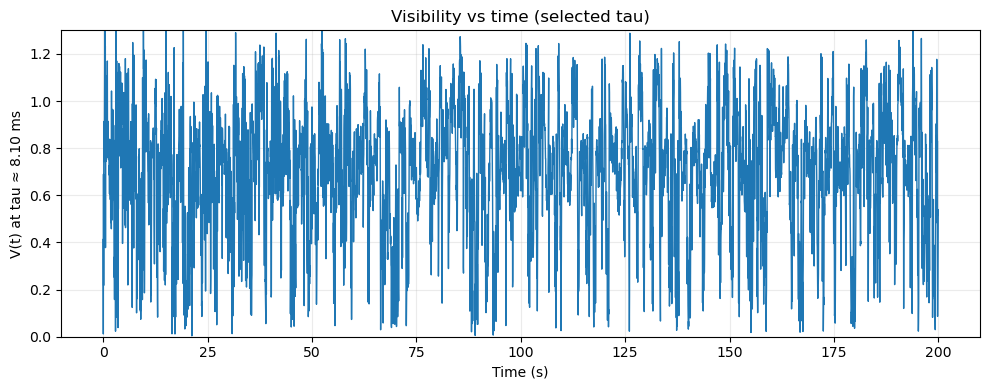

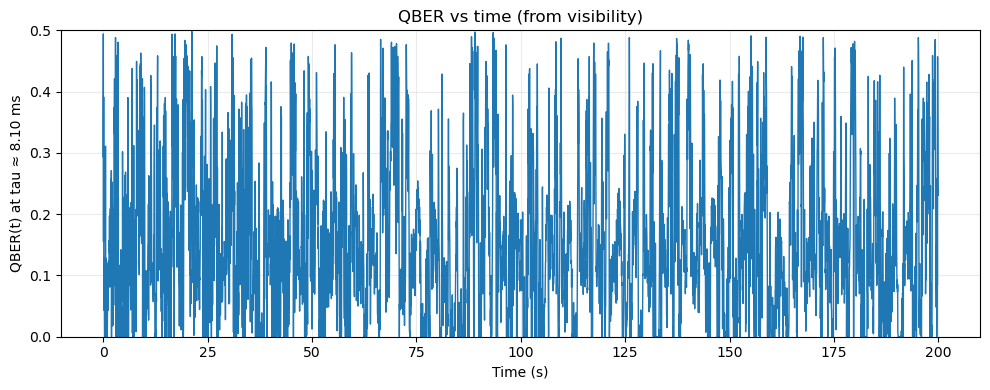

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 81, 'S': 40, 'tau': 0.0081, 'step': 0.004, 'n_windows_total': 49998, 'n_windows_used': 49998, 'mean_counts_per_window_used': 276.46691867674707}
V median: 0.7435789323135618
V mean:   0.7036797570737959
V 10–90%: 0.2770735475210618 … 1.047065382522096


In [352]:
if __name__ == "__main__":
    # Example: load your npy which stores (ts, counts)
    ts, counts = NL_100_em[1][0],NL_100_em[1][1]

    # Set your ramp frequency
    f_ramp = 100.0
    dt = np.mean(np.diff(ts))
    tau_min = 1e-3
    tau_max = 1
    n_taus = 100

    K_min = int(np.ceil(tau_min / dt))
    K_max = int(np.floor(tau_max / dt))

    Ks = np.unique(
        np.round(
            np.logspace(
                np.log10(K_min),
                np.log10(K_max),
                n_taus
            )
        ).astype(int)
    )

    taus = Ks * dt
    # Run tau sweep
    res = lockin_visibility_summary_vs_tau(ts, counts, f_ramp=f_ramp, taus=taus,overlap=0, n_min=0, clip=False)
    # Plot results
    plot_visibility_vs_tau(res)
    plot_qber_and_secret_proxy(res, title_prefix="Dataset")
    cycles=0.8
    # Choose operating tau and knee
    tau_op = choose_operating_tau(res, f_ramp=f_ramp, cycles_min=cycles, within_frac=0.98, use="median")
    tau_knee_mean = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=cycles, drop_frac=0.95, use="mean")
    tau_knee_med  = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=cycles, drop_frac=0.95, use="median")
    print("Operating tau (s):", tau_op)
    print("Knee tau mean (s):", tau_knee_mean)
    print("Knee tau median (s):", tau_knee_med)

    #Plot time series at operating tau
    plot_visibility_time_series_at_tau(ts, counts, f_ramp=f_ramp, tau=tau_op, overlap=0.5, n_min=0)
    pass

Operating tau (s): 0.0142
Knee tau mean (s): 0.008700000000000001
Knee tau median (s): 0.008700000000000001


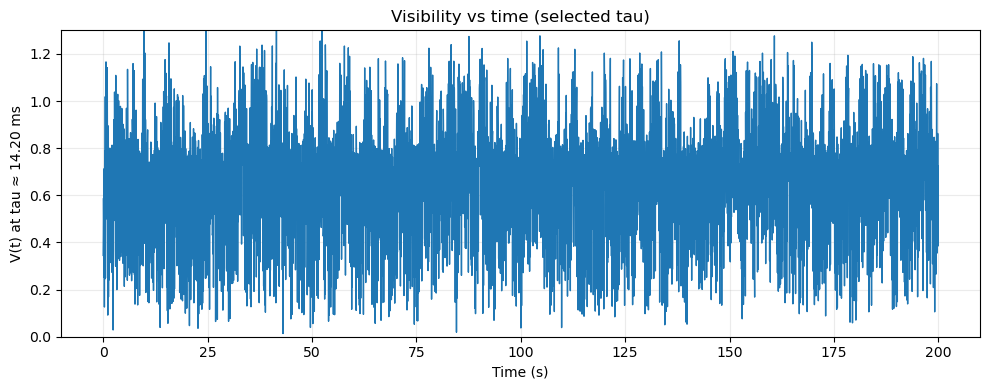

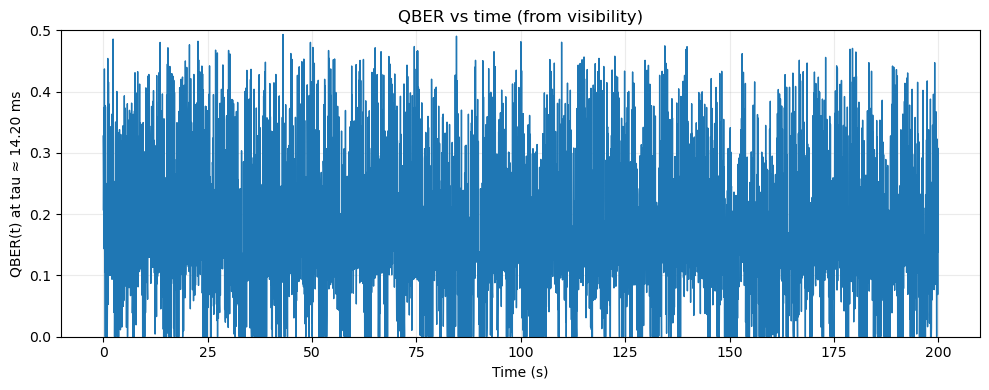

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 142, 'S': 71, 'tau': 0.0142, 'step': 0.0071, 'n_windows_total': 28168, 'n_windows_used': 28168, 'mean_counts_per_window_used': 484.66639449020164}
V median: 0.6946133573069802
V mean:   0.664976839370496
V 10–90%: 0.287363638242954 … 0.9992997730852724


In [382]:
if __name__ == "__main__":
    # Choose operating tau and knee
    cycles=0.82
    # Choose operating tau and knee
    tau_op = choose_operating_tau(res, f_ramp=f_ramp, cycles_min=cycles, within_frac=1, use="median")
    #tau_op = 0.07
    tau_knee_mean = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=cycles, drop_frac=0.99, use="mean")
    tau_knee_med  = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=cycles, drop_frac=0.99, use="median")
    print("Operating tau (s):", tau_op)
    print("Knee tau mean (s):", tau_knee_mean)
    print("Knee tau median (s):", tau_knee_med)

    #Plot time series at operating tau
    plot_visibility_time_series_at_tau(ts, counts, f_ramp=f_ramp, tau=tau_op, overlap=0.5, n_min=0)
    pass

In [424]:
NL_100_nm[1][0]

array([0.000000e+00, 7.000000e-04, 1.400000e-03, ..., 1.999984e+02,
       1.999991e+02, 1.999998e+02])

In [422]:
NL_100_nm[1][1]

array([32., 36., 22., ...,  2.,  7.,  7.])

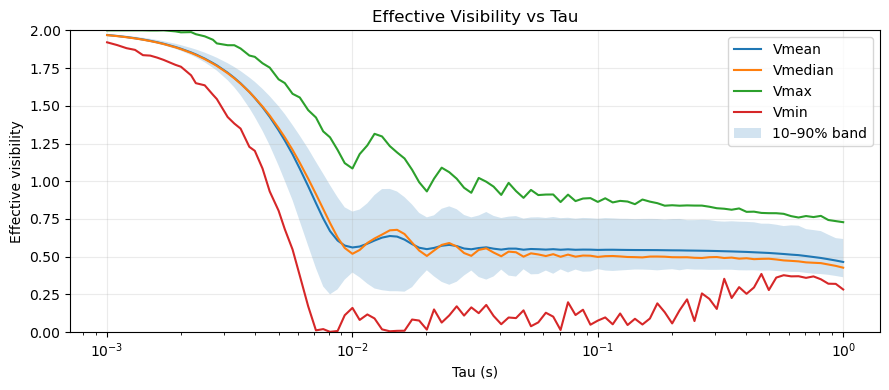

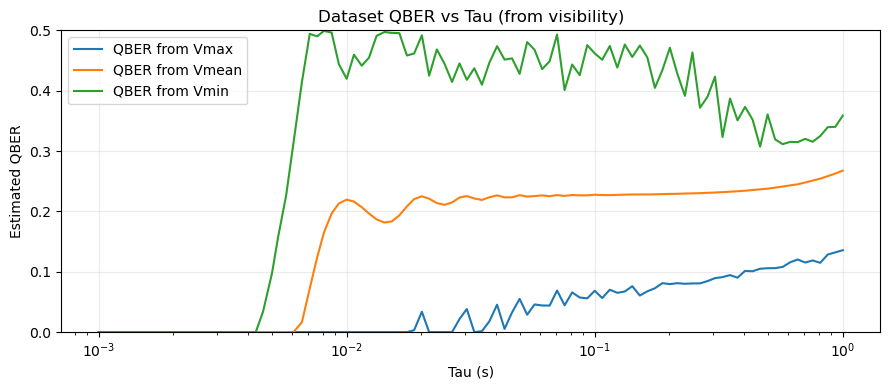

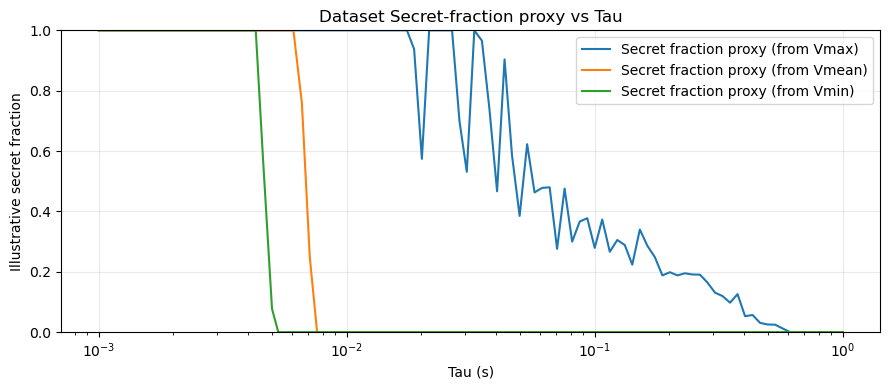

Operating tau (s): 0.0142
Knee tau mean (s): 0.01
Knee tau median (s): 0.01


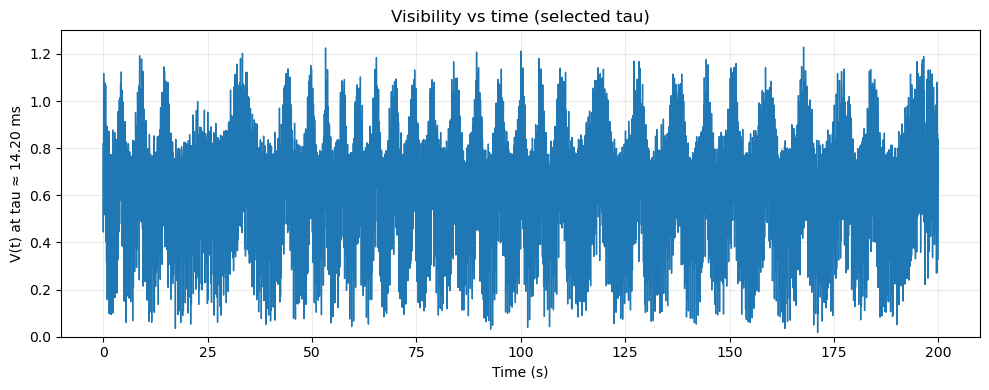

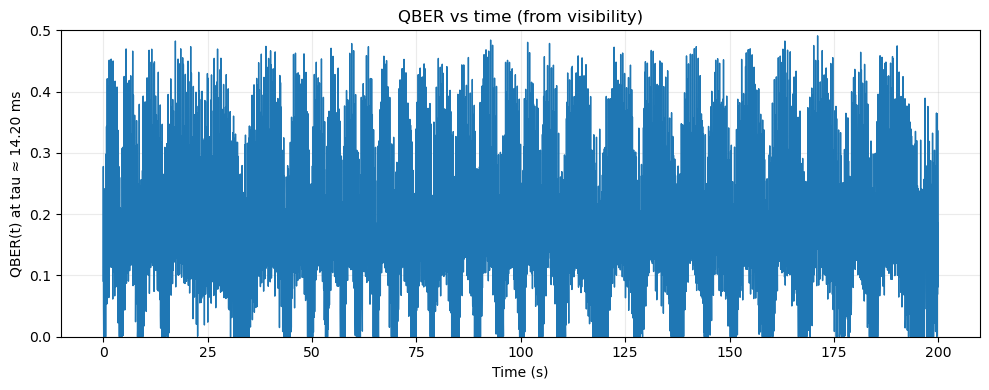

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 142, 'S': 142, 'tau': 0.0142, 'step': 0.0142, 'n_windows_total': 14084, 'n_windows_used': 14084, 'mean_counts_per_window_used': 457.8251917069014}
V median: 0.6745943919031596
V mean:   0.6369568817476695
V 10–90%: 0.271139485199619 … 0.9489959033574434


In [454]:
if __name__ == "__main__":
    # Example: load your npy which stores (ts, counts)
    ts, counts = NL_100_nm[1][0],NL_100_nm[1][1]

    # Set your ramp frequency
    f_ramp = 100.0
    dt = np.mean(np.diff(ts))
    tau_min = 1e-3
    tau_max = 1
    n_taus = 100

    K_min = int(np.ceil(tau_min / dt))
    K_max = int(np.floor(tau_max / dt))

    Ks = np.unique(
        np.round(
            np.logspace(
                np.log10(K_min),
                np.log10(K_max),
                n_taus
            )
        ).astype(int)
    )

    taus = Ks * dt
    # Run tau sweep
    res = lockin_visibility_summary_vs_tau(ts, counts, f_ramp=f_ramp, taus=taus,overlap=0, n_min=0, clip=False)
    # Plot results
    plot_visibility_vs_tau(res)
    plot_qber_and_secret_proxy(res, title_prefix="Dataset")
    cycles=1
    # Choose operating tau and knee
    tau_op = choose_operating_tau(res, f_ramp=f_ramp, cycles_min=cycles, within_frac=0.98, use="median")
    tau_knee_mean = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=cycles, drop_frac=0.95, use="mean")
    tau_knee_med  = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=cycles, drop_frac=0.95, use="median")
    print("Operating tau (s):", tau_op)
    print("Knee tau mean (s):", tau_knee_mean)
    print("Knee tau median (s):", tau_knee_med)

    #Plot time series at operating tau
    plot_visibility_time_series_at_tau(ts, counts, f_ramp=f_ramp, tau=tau_op, overlap=0, n_min=0)
    pass

Operating tau (s): 0.0142
Knee tau mean (s): 0.01
Knee tau median (s): 0.01


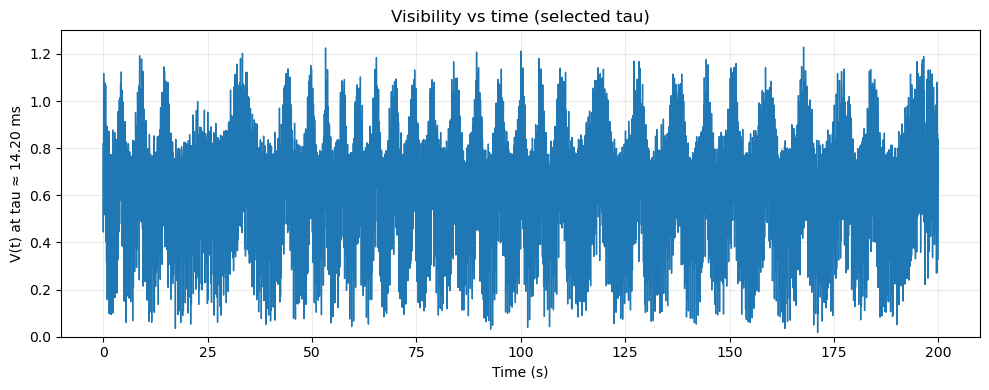

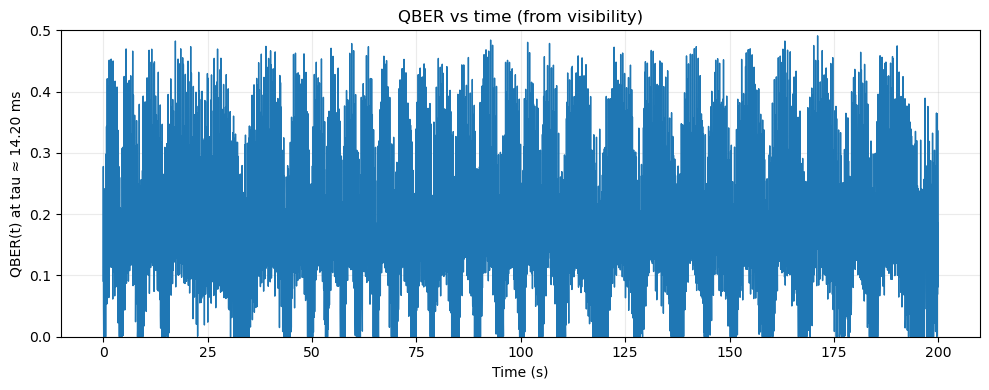

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 142, 'S': 142, 'tau': 0.0142, 'step': 0.0142, 'n_windows_total': 14084, 'n_windows_used': 14084, 'mean_counts_per_window_used': 457.8251917069014}
V median: 0.6745943919031596
V mean:   0.6369568817476695
V 10–90%: 0.271139485199619 … 0.9489959033574434


In [450]:
if __name__ == "__main__":
    # Choose operating tau and knee
    cycles=1
    # Choose operating tau and knee
    tau_op = choose_operating_tau(res, f_ramp=f_ramp, cycles_min=cycles, within_frac=0.98, use="median")
    #tau_op = 0.07
    tau_knee_mean = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=cycles, drop_frac=0.95, use="mean")
    tau_knee_med  = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=cycles, drop_frac=0.95, use="median")
    print("Operating tau (s):", tau_op)
    print("Knee tau mean (s):", tau_knee_mean)
    print("Knee tau median (s):", tau_knee_med)

    #Plot time series at operating tau
    plot_visibility_time_series_at_tau(ts, counts, f_ramp=f_ramp, tau=tau_op, overlap=0, n_min=0)
    pass

In [488]:
pm=NL[5]['data']['pm_volts']

In [504]:
%matplotlib inline

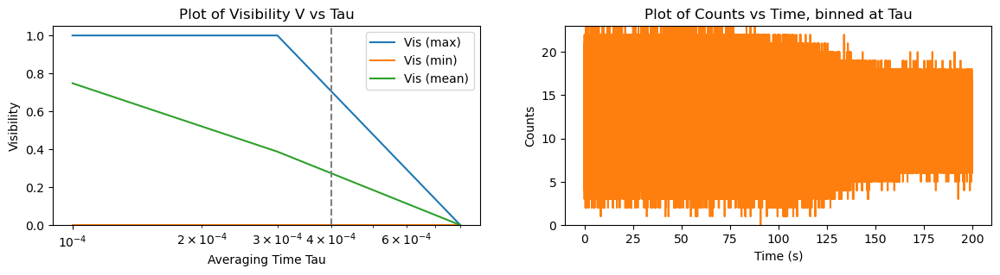

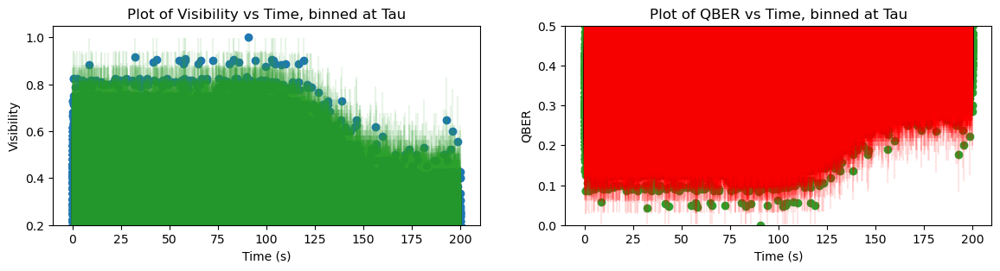

In [524]:
NL_1000_voa=Vis.AnalyseMeasurement(NL,0,10,0.0004,0.001,secondhalf=True)

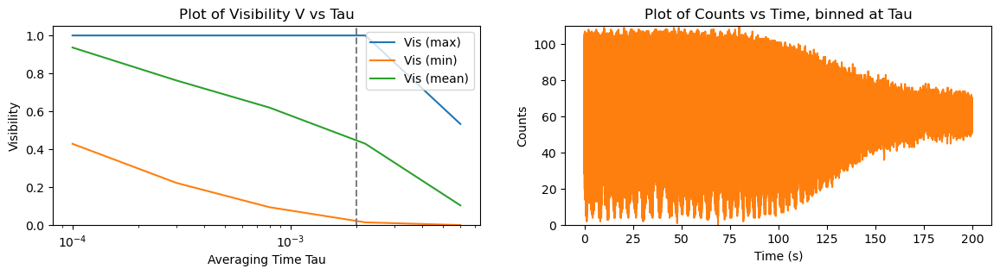

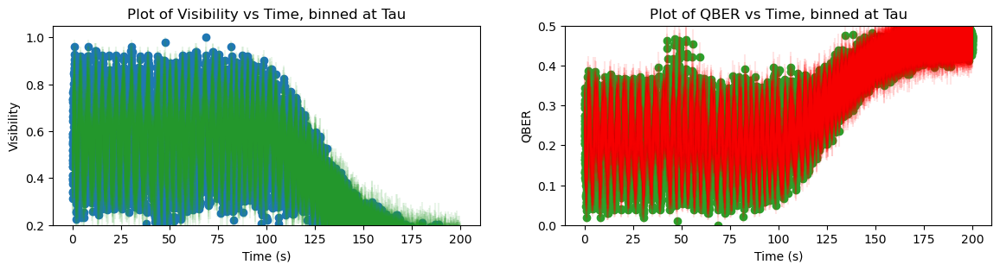

In [516]:
NL_100_voa=Vis.AnalyseMeasurement(NL,1,10,0.002,0.01,secondhalf=True)

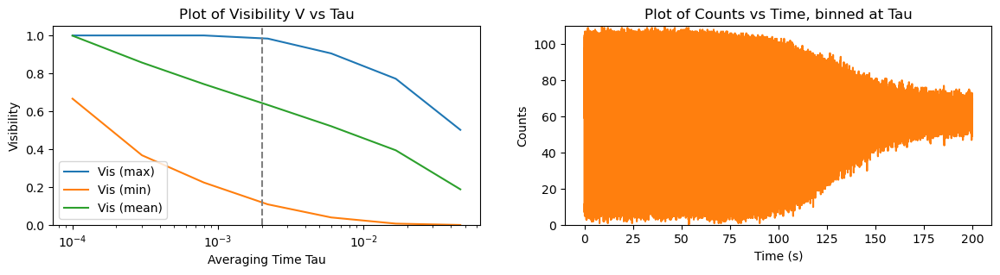

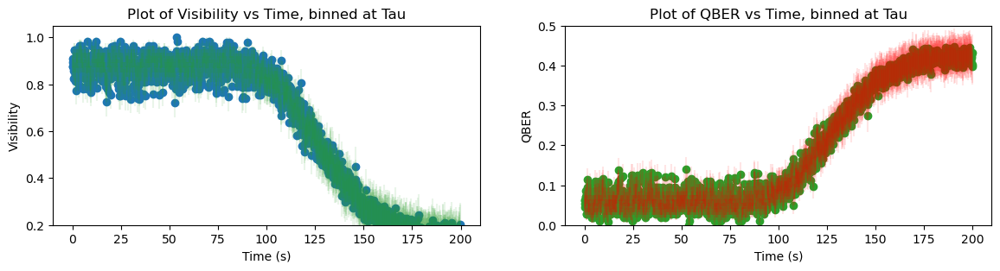

In [518]:
NL_10_voa=Vis.AnalyseMeasurement(NL,2,10,0.002,0.1,secondhalf=True)

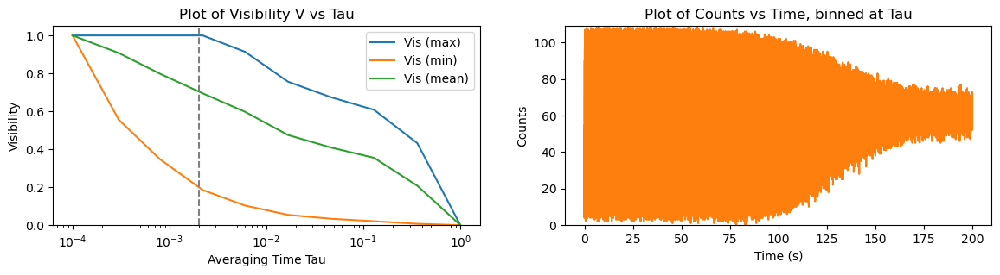

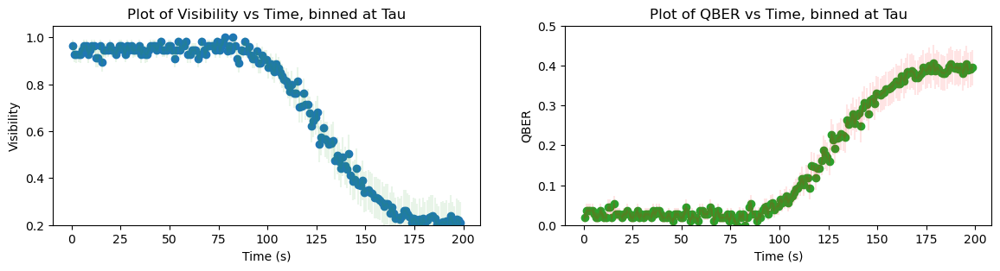

In [520]:
NL_1_voa=Vis.AnalyseMeasurement(NL,3,10,0.002,1,secondhalf=True)

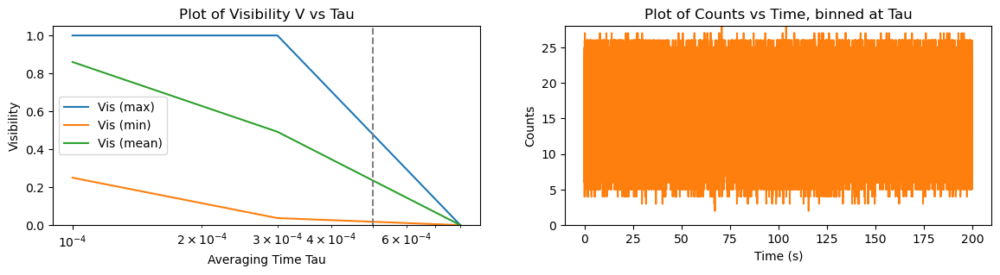

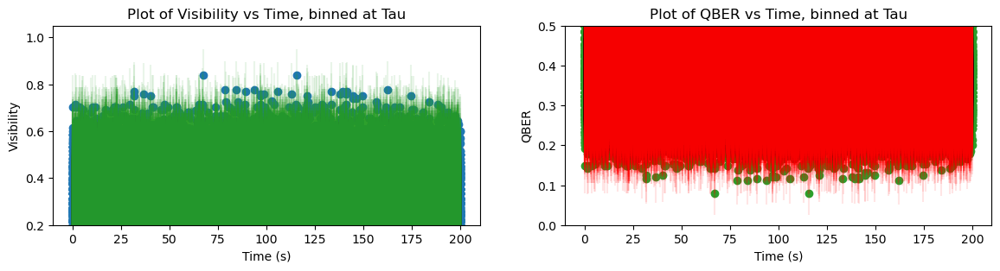

In [536]:
NL_1000_nm=Vis.AnalyseMeasurement(NL,4,10,0.0005,0.001,secondhalf=True)

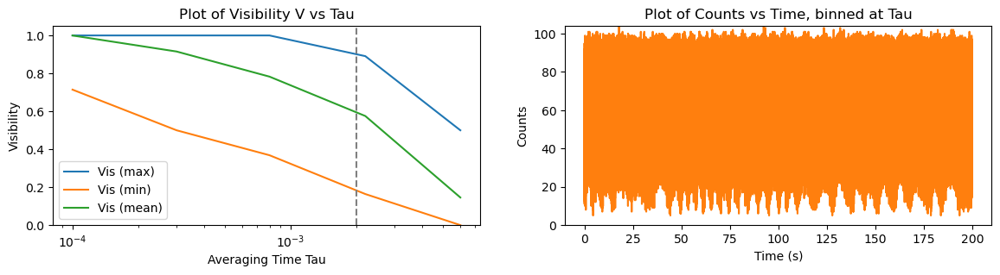

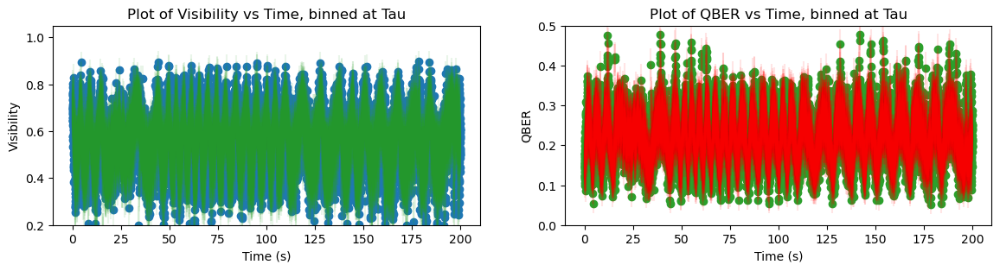

In [529]:
NL_100_nm=Vis.AnalyseMeasurement(NL,5,10,0.002,0.01,secondhalf=True)

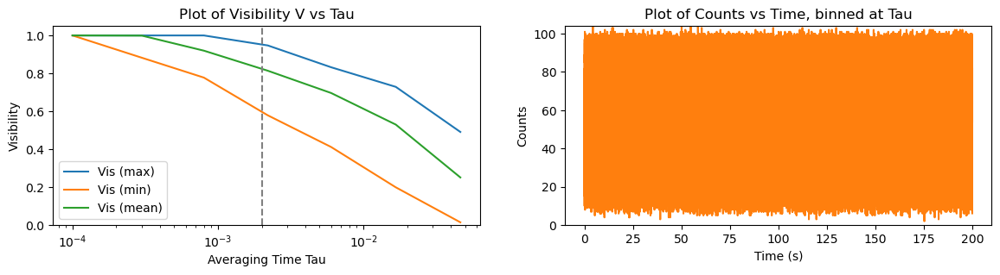

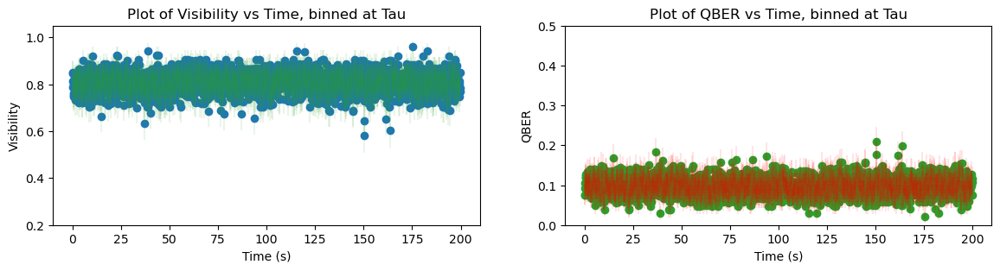

In [530]:
NL_10_nm=Vis.AnalyseMeasurement(NL,6,10,0.002,0.1,secondhalf=True)

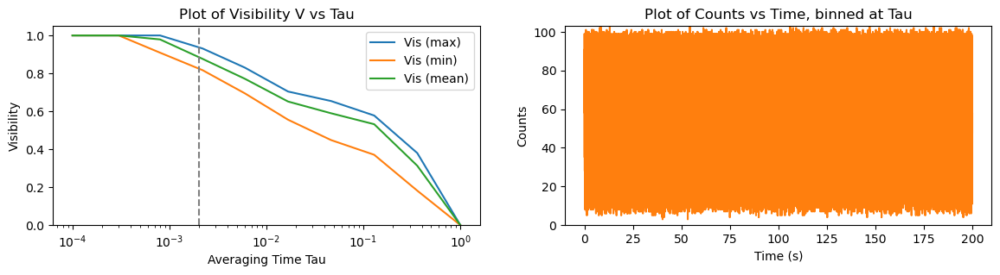

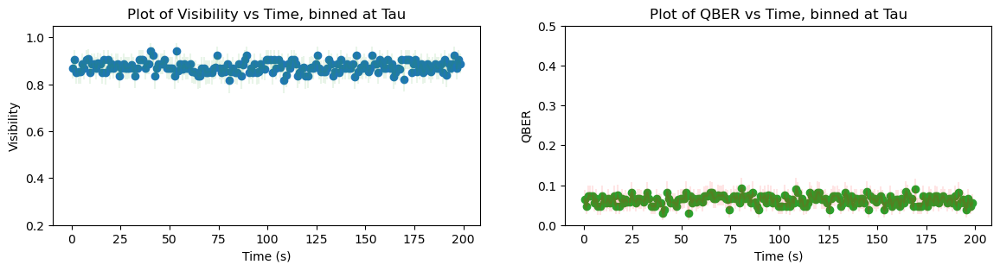

In [531]:
NL_1_nm=Vis.AnalyseMeasurement(NL,7,10,0.002,1,secondhalf=True)

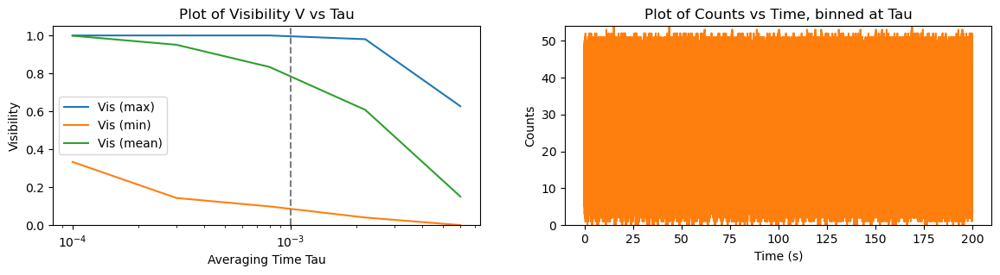

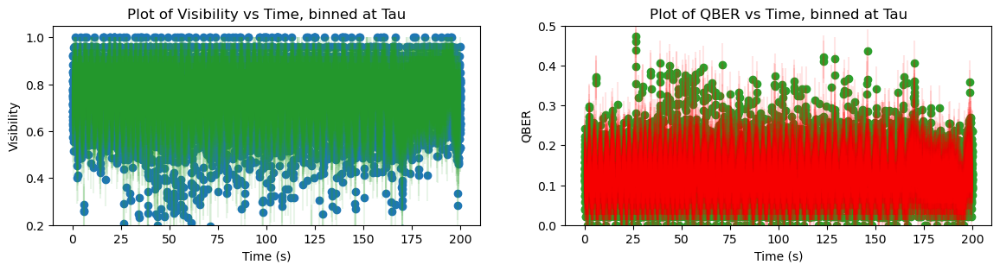

In [556]:
NLF_100_nm=Vis.AnalyseMeasurement(NLF,5,10,0.001,0.01,secondhalf=True)

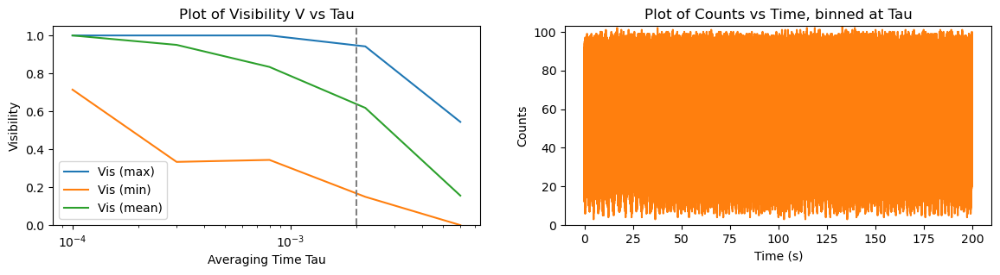

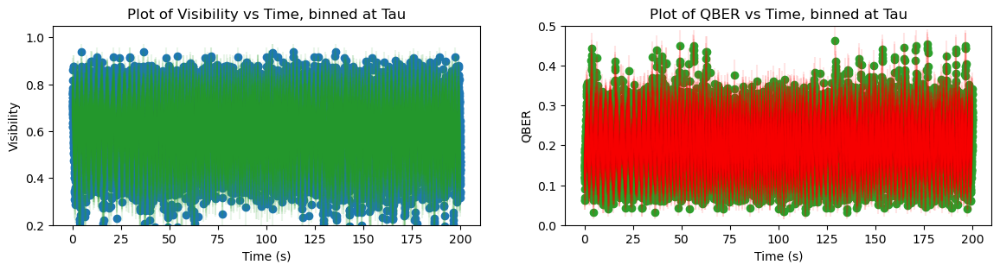

In [566]:
NLVF_100_nm=Vis.AnalyseMeasurement(NLVF,5,10,0.002,0.01,secondhalf=True)

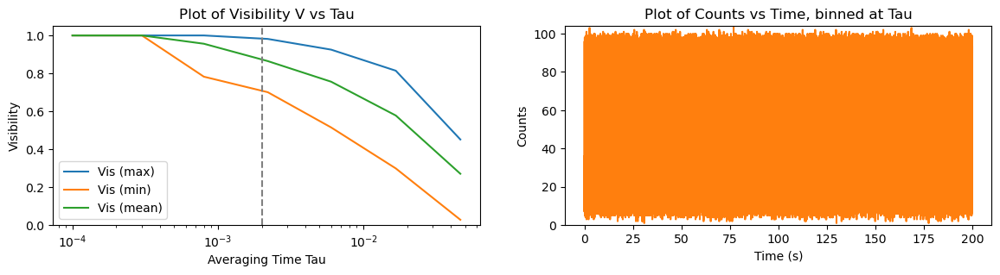

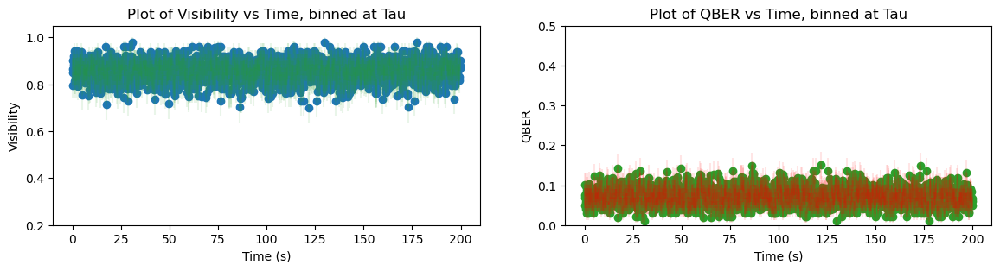

In [562]:
NLVF_10_nm=Vis.AnalyseMeasurement(NLVF,6,10,0.002,0.1,secondhalf=True)

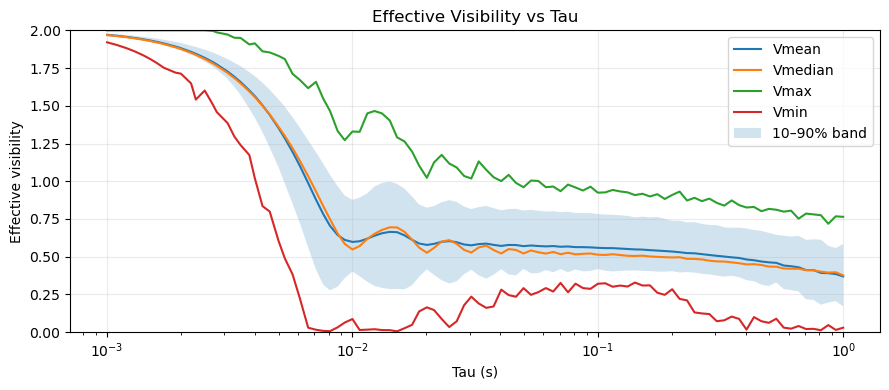

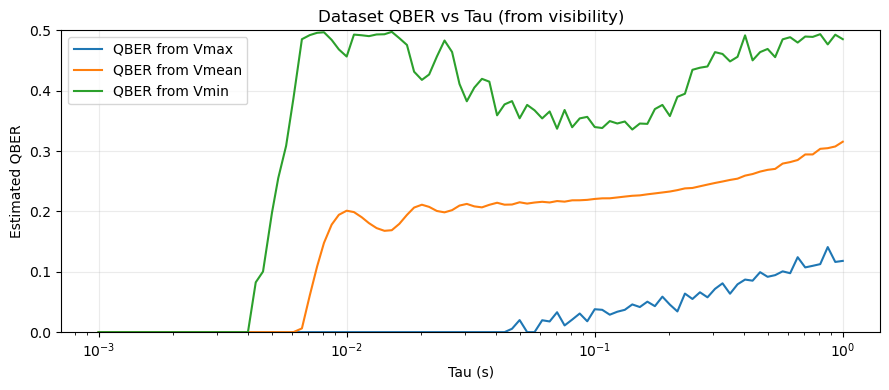

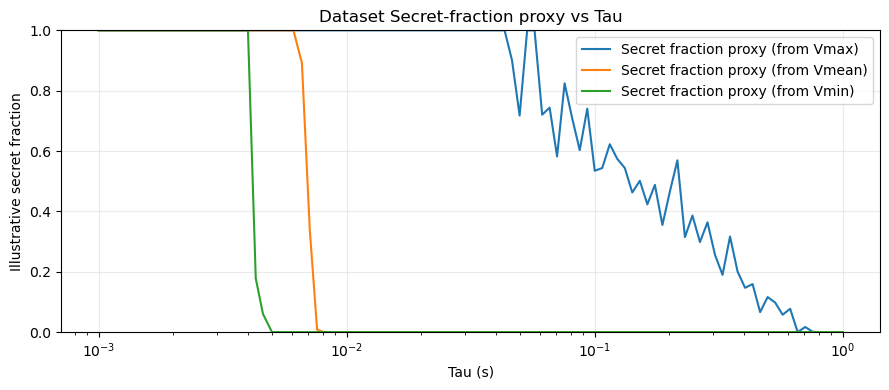

Operating tau (s): 0.0081
Knee tau mean (s): 0.008700000000000001
Knee tau median (s): 0.008700000000000001


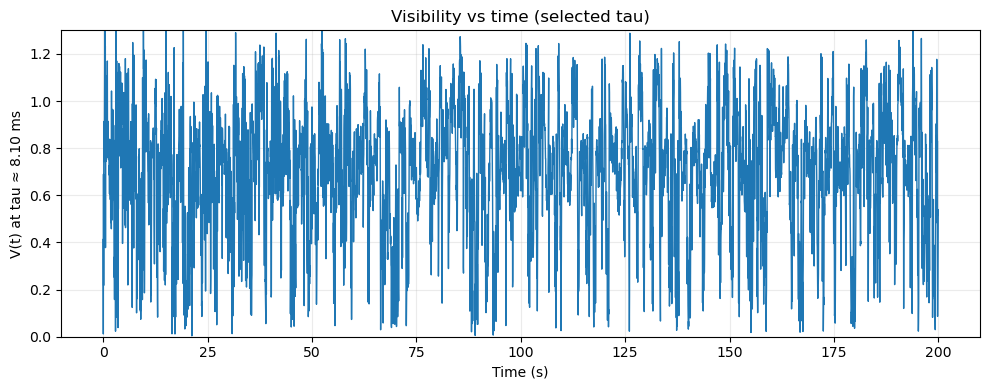

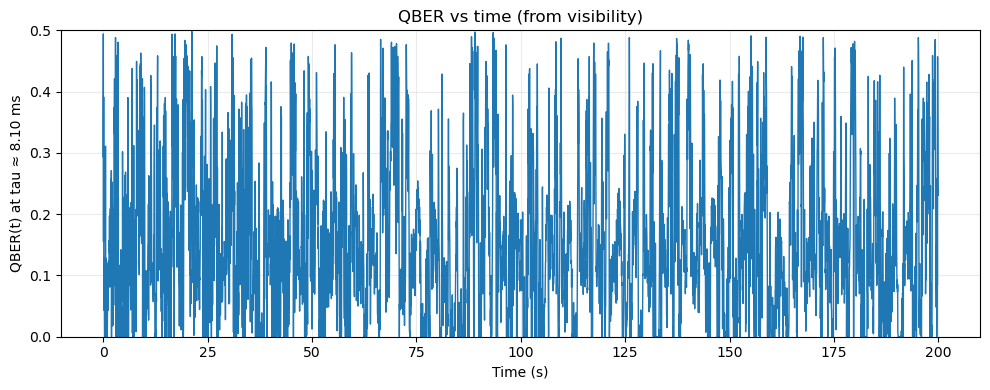

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 81, 'S': 40, 'tau': 0.0081, 'step': 0.004, 'n_windows_total': 49998, 'n_windows_used': 49998, 'mean_counts_per_window_used': 276.46691867674707}
V median: 0.7435789323135618
V mean:   0.7036797570737959
V 10–90%: 0.2770735475210618 … 1.047065382522096


In [352]:
if __name__ == "__main__":
    # Example: load your npy which stores (ts, counts)
    ts, counts = NL_100_em[1][0],NL_100_em[1][1]

    # Set your ramp frequency
    f_ramp = 100.0
    dt = np.mean(np.diff(ts))
    tau_min = 1e-3
    tau_max = 1
    n_taus = 100

    K_min = int(np.ceil(tau_min / dt))
    K_max = int(np.floor(tau_max / dt))

    Ks = np.unique(
        np.round(
            np.logspace(
                np.log10(K_min),
                np.log10(K_max),
                n_taus
            )
        ).astype(int)
    )

    taus = Ks * dt
    # Run tau sweep
    res = lockin_visibility_summary_vs_tau(ts, counts, f_ramp=f_ramp, taus=taus,overlap=0, n_min=0, clip=False)
    # Plot results
    plot_visibility_vs_tau(res)
    plot_qber_and_secret_proxy(res, title_prefix="Dataset")
    cycles=0.8
    # Choose operating tau and knee
    tau_op = choose_operating_tau(res, f_ramp=f_ramp, cycles_min=cycles, within_frac=0.98, use="median")
    tau_knee_mean = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=cycles, drop_frac=0.95, use="mean")
    tau_knee_med  = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=cycles, drop_frac=0.95, use="median")
    print("Operating tau (s):", tau_op)
    print("Knee tau mean (s):", tau_knee_mean)
    print("Knee tau median (s):", tau_knee_med)

    #Plot time series at operating tau
    plot_visibility_time_series_at_tau(ts, counts, f_ramp=f_ramp, tau=tau_op, overlap=0.5, n_min=0)
    pass

Operating tau (s): 0.0142
Knee tau mean (s): 0.008700000000000001
Knee tau median (s): 0.008700000000000001


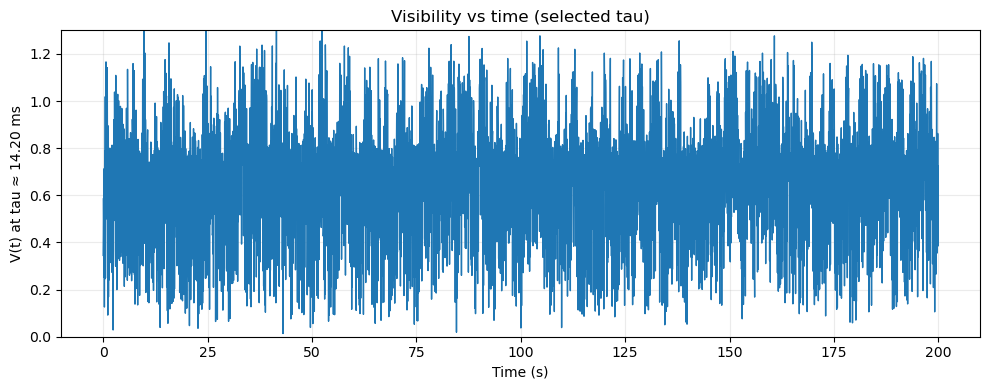

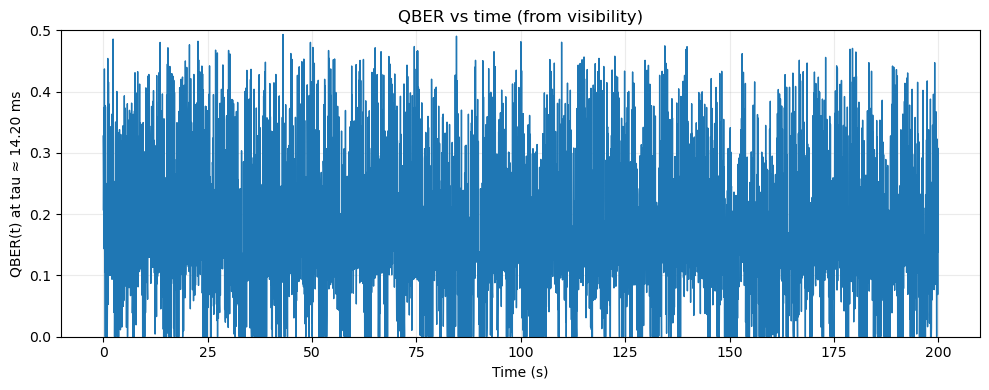

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 142, 'S': 71, 'tau': 0.0142, 'step': 0.0071, 'n_windows_total': 28168, 'n_windows_used': 28168, 'mean_counts_per_window_used': 484.66639449020164}
V median: 0.6946133573069802
V mean:   0.664976839370496
V 10–90%: 0.287363638242954 … 0.9992997730852724


In [382]:
if __name__ == "__main__":
    # Choose operating tau and knee
    cycles=0.82
    # Choose operating tau and knee
    tau_op = choose_operating_tau(res, f_ramp=f_ramp, cycles_min=cycles, within_frac=1, use="median")
    #tau_op = 0.07
    tau_knee_mean = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=cycles, drop_frac=0.99, use="mean")
    tau_knee_med  = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=cycles, drop_frac=0.99, use="median")
    print("Operating tau (s):", tau_op)
    print("Knee tau mean (s):", tau_knee_mean)
    print("Knee tau median (s):", tau_knee_med)

    #Plot time series at operating tau
    plot_visibility_time_series_at_tau(ts, counts, f_ramp=f_ramp, tau=tau_op, overlap=0.5, n_min=0)
    pass

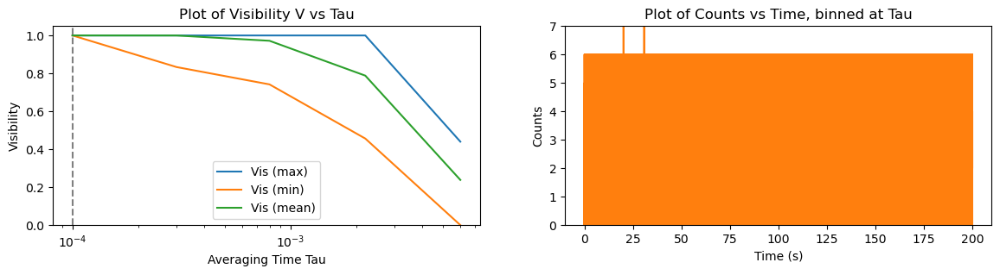

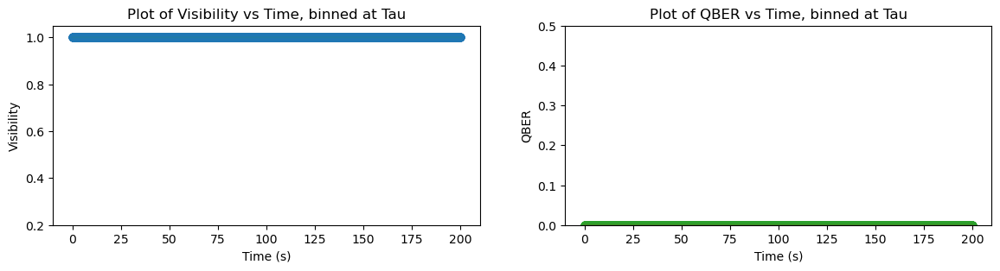

In [568]:
DNF_100_nm=Vis.AnalyseMeasurement(DNF,5,10,0.0001,0.01,secondhalf=True)

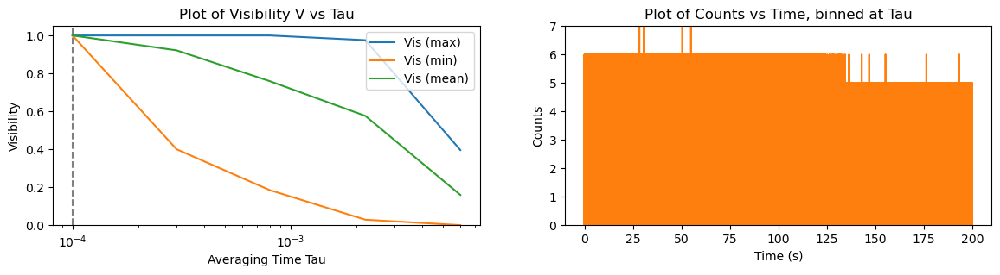

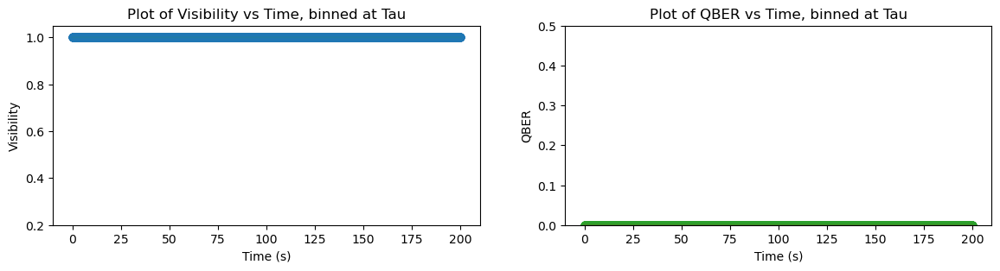

In [570]:
DNF_100_voa=Vis.AnalyseMeasurement(DNF,1,10,0.0001,0.01,secondhalf=True)

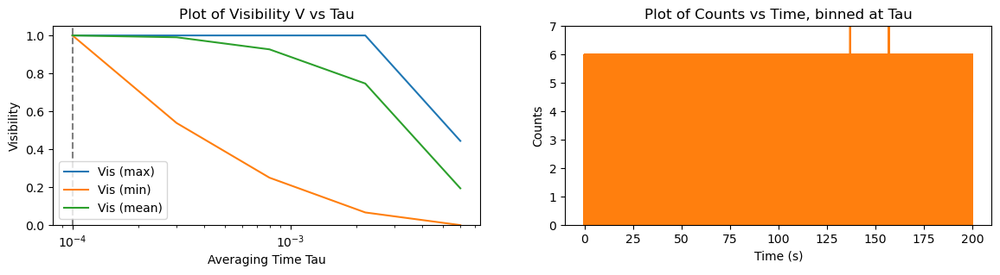

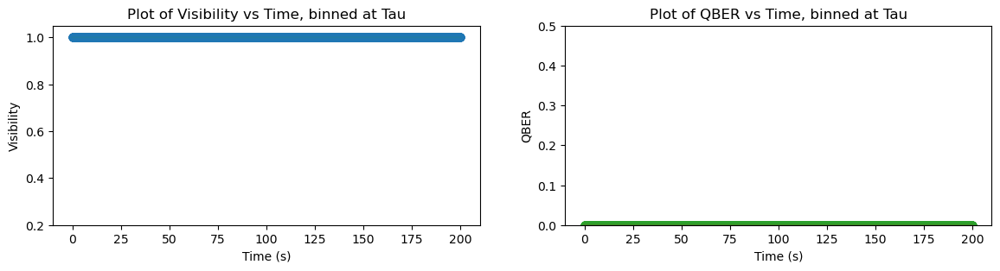

In [572]:
DNF_100_em=Vis.AnalyseMeasurement(DNF,9,10,0.0001,0.01,secondhalf=True)

In [526]:
for i in range(len(NL)):
    print(i,NL[i]['name'])

0 Night_2_1MhzGate_158uWperArm_Rmp1000Hz_voaramp
1 Night_2_1MhzGate_158uWperArm_Rmp100Hz_voaramp
2 Night_2_1MhzGate_158uWperArm_Rmp10Hz_voaramp
3 Night_2_1MhzGate_158uWperArm_Rmp1Hz_voaramp
4 Night_2_1MhzGate_158uWperArm_Rmp1000Hz_nomodulation
5 Night_2_1MhzGate_158uWperArm_Rmp100Hz_nomodulation
6 Night_2_1MhzGate_158uWperArm_Rmp10Hz_nomodulation
7 Night_2_1MhzGate_158uWperArm_Rmp1Hz_nomodulation
8 Night_2_1MhzGate_158uWperArm_Rmp1000Hz
9 Night_2_1MhzGate_158uWperArm_Rmp100Hz
10 Night_2_1MhzGate_158uWperArm_Rmp10Hz
11 Night_2_1MhzGate_158uWperArm_Rmp1Hz
12 Night_2_1MhzGate_158uWperArm_Rmp1Hz


In [550]:
for i in range(len(DNF)):
    print(i,DNF[i]['name'])

0 Day_2_1MhzGate_107uWperArm_Rmp1000Hz_voaramp
1 Day_2_1MhzGate_107uWperArm_Rmp100Hz_voaramp
2 Day_2_1MhzGate_107uWperArm_Rmp10Hz_voaramp
3 Day_2_1MhzGate_107uWperArm_Rmp1Hz_voaramp
4 Day_2_1MhzGate_107uWperArm_Rmp1000Hz_nomodulation
5 Day_2_1MhzGate_107uWperArm_Rmp100Hz_nomodulation
6 Day_2_1MhzGate_107uWperArm_Rmp10Hz_nomodulation
7 Day_2_1MhzGate_107uWperArm_Rmp1Hz_nomodulation
8 Day_2_1MhzGate_107uWperArm_Rmp1000Hz
9 Day_2_1MhzGate_107uWperArm_Rmp100Hz
10 Day_2_1MhzGate_107uWperArm_Rmp10Hz
11 Day_2_1MhzGate_107uWperArm_Rmp1Hz


In [584]:
for i in range(len(DF)):
    print(i,DF[i]['name'])

NameError: name 'DF' is not defined

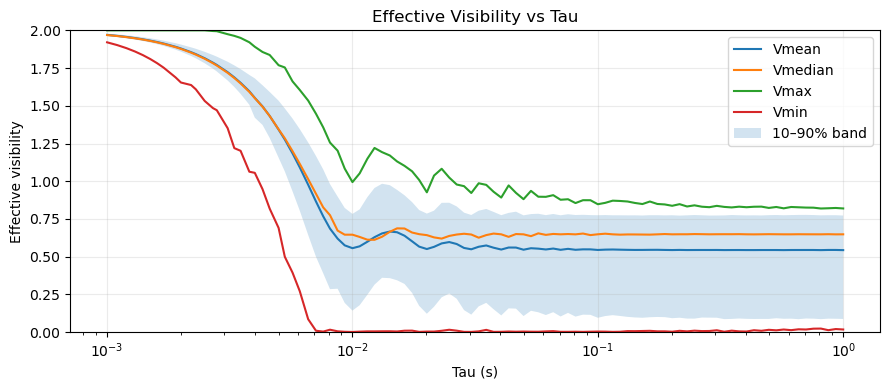

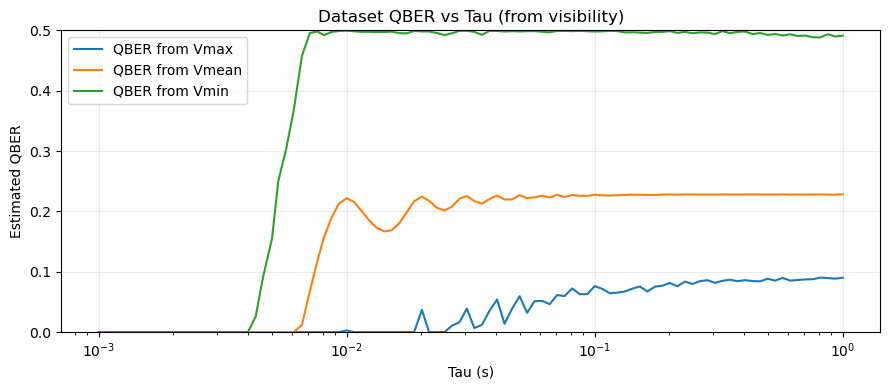

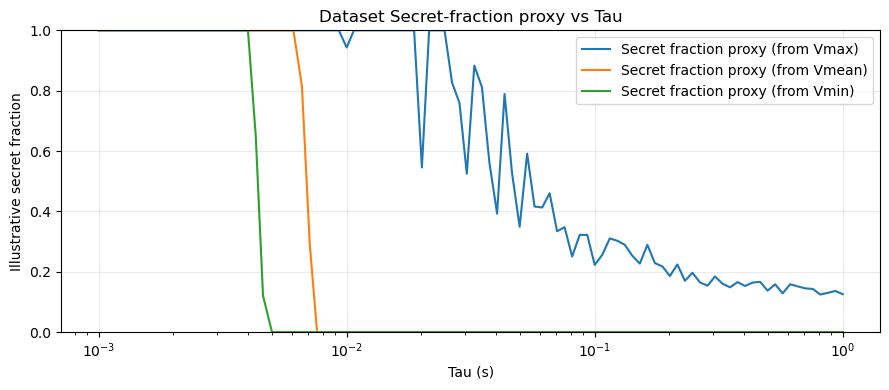

Operating tau (s): 0.1
Knee tau mean (s): nan
Knee tau median (s): nan


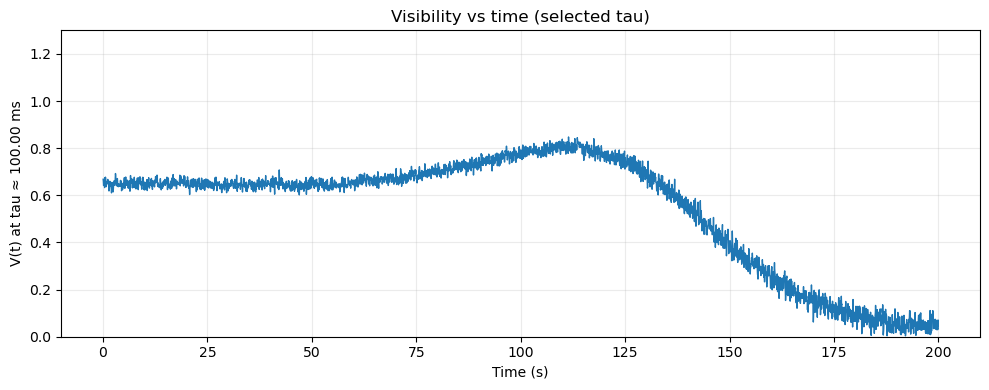

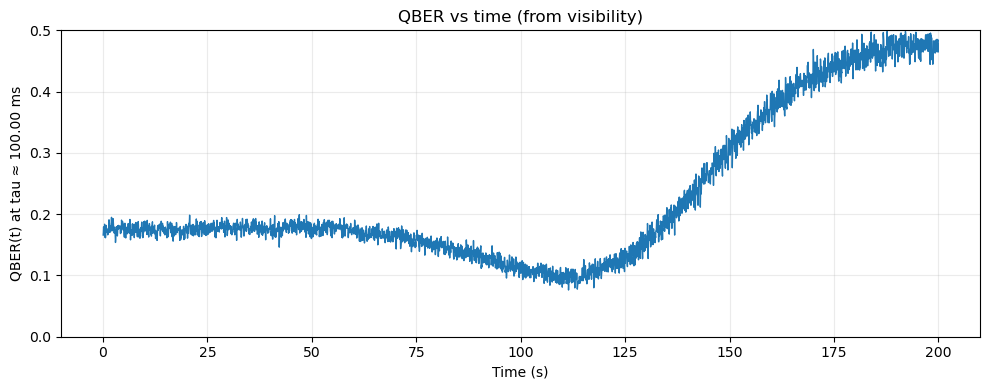

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 1000, 'S': 500, 'tau': 0.1, 'step': 0.05, 'n_windows_total': 3999, 'n_windows_used': 3999, 'mean_counts_per_window_used': 2196.699424856214}
V median: 0.6484073355077167
V mean:   0.5445238386373025
V 10–90%: 0.09502675620025695 … 0.7747120750358294


In [578]:
if __name__ == "__main__":
    # Example: load your npy which stores (ts, counts)
    ts, counts = DNF_100_voa[1][0],DNF_100_voa[1][1]

    # Set your ramp frequency
    f_ramp = 100.0
    dt = np.mean(np.diff(ts))
    tau_min = 1e-3
    tau_max = 1
    n_taus = 100

    K_min = int(np.ceil(tau_min / dt))
    K_max = int(np.floor(tau_max / dt))

    Ks = np.unique(
        np.round(
            np.logspace(
                np.log10(K_min),
                np.log10(K_max),
                n_taus
            )
        ).astype(int)
    )

    taus = Ks * dt
    # Run tau sweep
    res = lockin_visibility_summary_vs_tau(ts, counts, f_ramp=f_ramp, taus=taus,overlap=0.5, n_min=0, clip=False)
    # Plot results
    plot_visibility_vs_tau(res)
    plot_qber_and_secret_proxy(res, title_prefix="Dataset")
    cycles=10
    # Choose operating tau and knee
    tau_op = choose_operating_tau(res, f_ramp=f_ramp, cycles_min=cycles, within_frac=0.98, use="median")
    tau_knee_mean = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=cycles, drop_frac=0.95, use="mean")
    tau_knee_med  = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=cycles, drop_frac=0.95, use="median")
    print("Operating tau (s):", tau_op)
    print("Knee tau mean (s):", tau_knee_mean)
    print("Knee tau median (s):", tau_knee_med)

    #Plot time series at operating tau
    plot_visibility_time_series_at_tau(ts, counts, f_ramp=f_ramp, tau=tau_op, overlap=0.5, n_min=0)
    pass

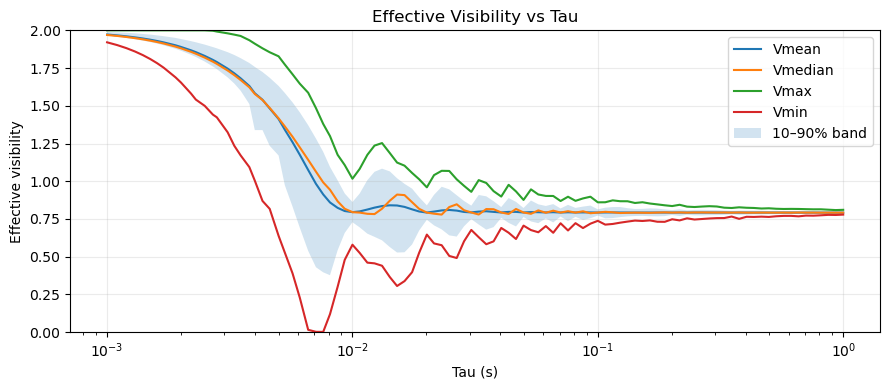

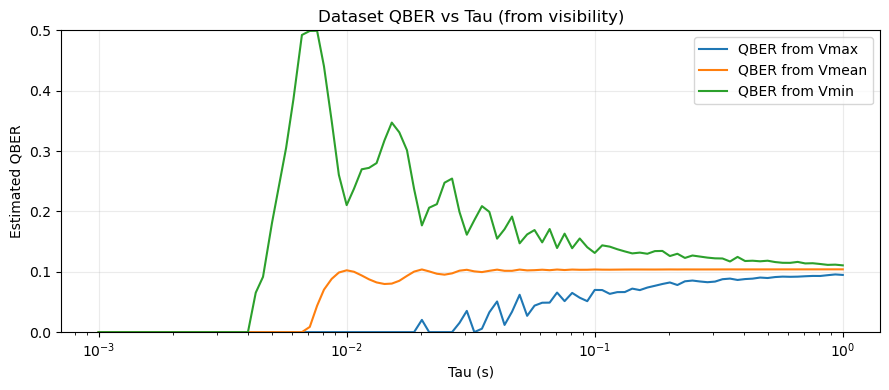

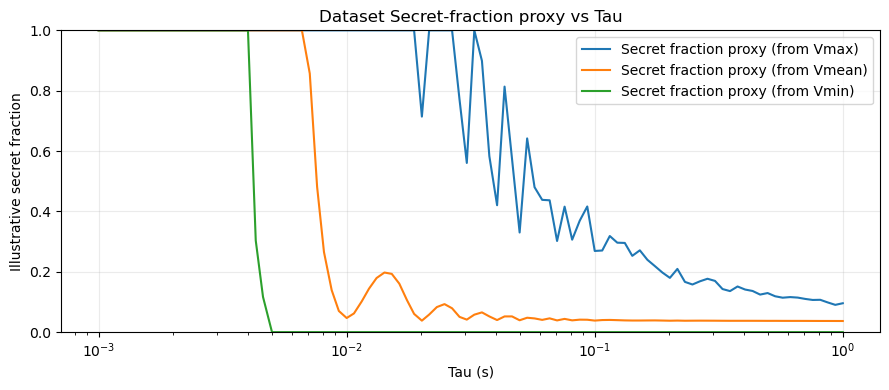

Operating tau (s): 0.1
Knee tau mean (s): nan
Knee tau median (s): nan


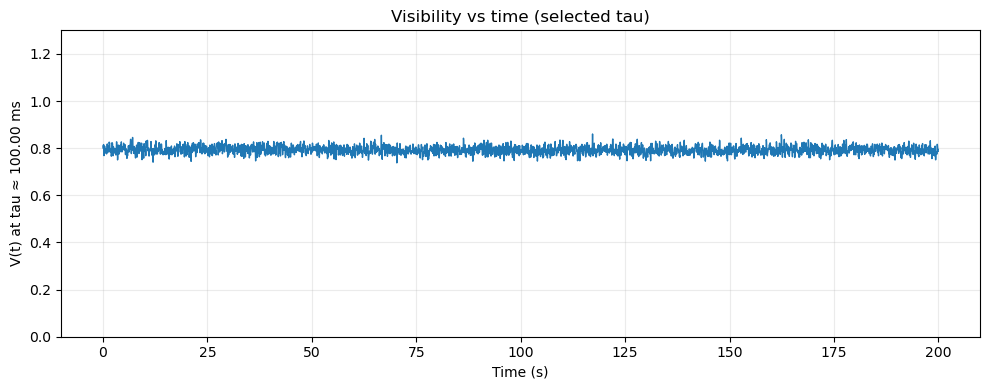

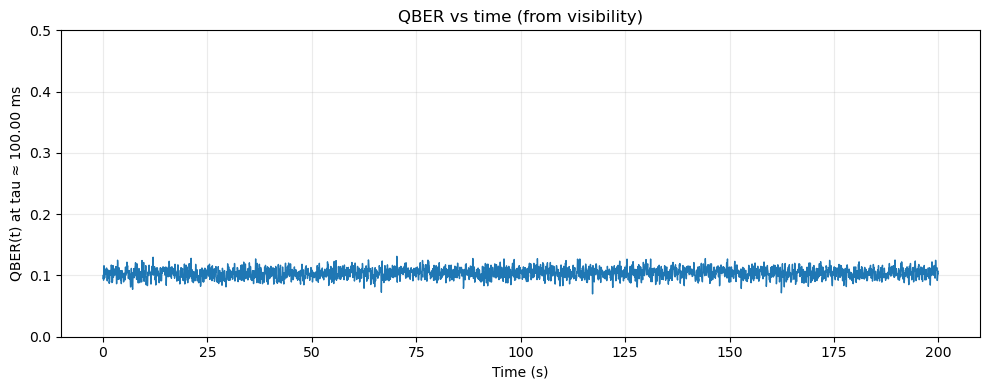

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 1000, 'S': 500, 'tau': 0.1, 'step': 0.05, 'n_windows_total': 3999, 'n_windows_used': 3999, 'mean_counts_per_window_used': 2203.835458864716}
V median: 0.7923334196051983
V mean:   0.7924323439549542
V 10–90%: 0.7724042778954883 … 0.813458893298894


In [580]:
if __name__ == "__main__":
    # Example: load your npy which stores (ts, counts)
    ts, counts = DNF_100_nm[1][0],DNF_100_nm[1][1]

    # Set your ramp frequency
    f_ramp = 100.0
    dt = np.mean(np.diff(ts))
    tau_min = 1e-3
    tau_max = 1
    n_taus = 100

    K_min = int(np.ceil(tau_min / dt))
    K_max = int(np.floor(tau_max / dt))

    Ks = np.unique(
        np.round(
            np.logspace(
                np.log10(K_min),
                np.log10(K_max),
                n_taus
            )
        ).astype(int)
    )

    taus = Ks * dt
    # Run tau sweep
    res = lockin_visibility_summary_vs_tau(ts, counts, f_ramp=f_ramp, taus=taus,overlap=0.5, n_min=0, clip=False)
    # Plot results
    plot_visibility_vs_tau(res)
    plot_qber_and_secret_proxy(res, title_prefix="Dataset")
    cycles=10
    # Choose operating tau and knee
    tau_op = choose_operating_tau(res, f_ramp=f_ramp, cycles_min=cycles, within_frac=0.98, use="median")
    tau_knee_mean = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=cycles, drop_frac=0.95, use="mean")
    tau_knee_med  = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=cycles, drop_frac=0.95, use="median")
    print("Operating tau (s):", tau_op)
    print("Knee tau mean (s):", tau_knee_mean)
    print("Knee tau median (s):", tau_knee_med)

    #Plot time series at operating tau
    plot_visibility_time_series_at_tau(ts, counts, f_ramp=f_ramp, tau=tau_op, overlap=0.5, n_min=0)
    pass

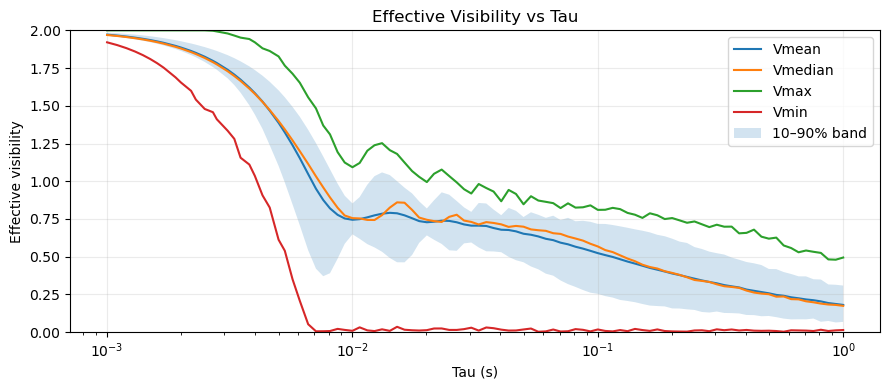

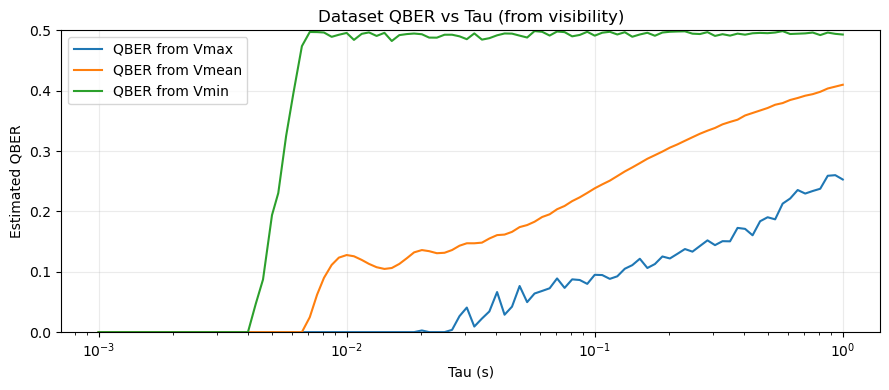

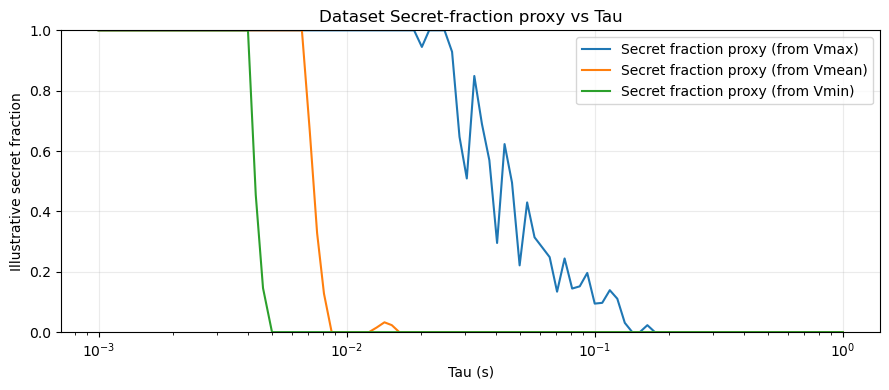

Operating tau (s): 0.1
Knee tau mean (s): 0.1233
Knee tau median (s): 0.115


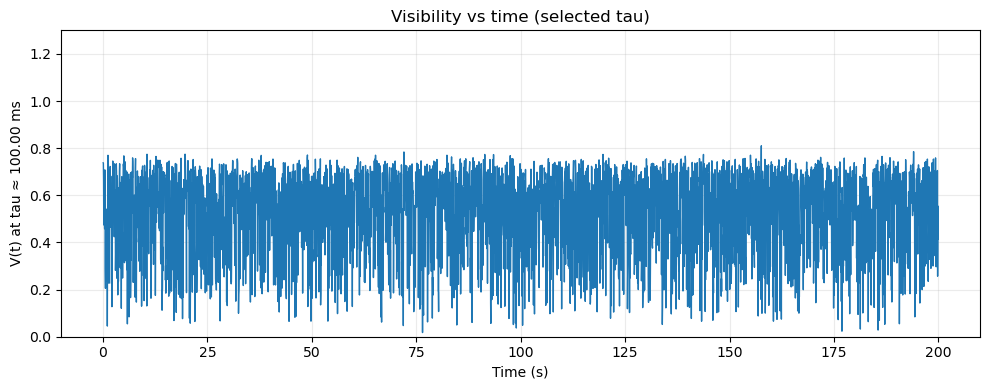

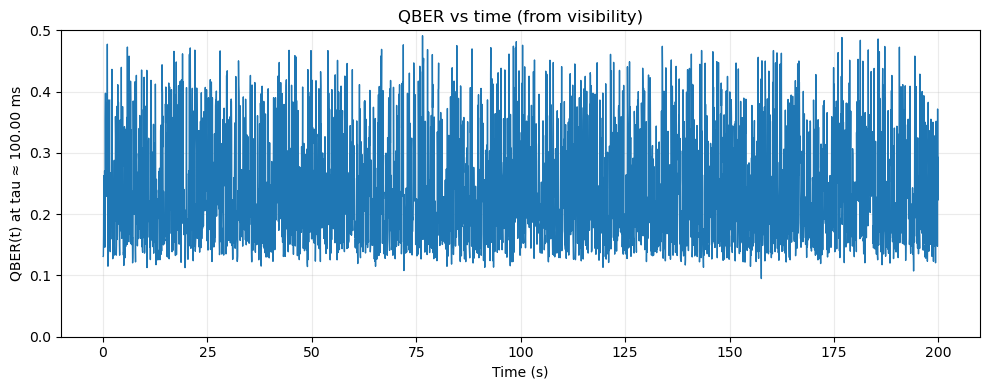

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 1000, 'S': 500, 'tau': 0.1, 'step': 0.05, 'n_windows_total': 3999, 'n_windows_used': 3999, 'mean_counts_per_window_used': 2224.3130782695675}
V median: 0.567779559978943
V mean:   0.5234916093913541
V 10–90%: 0.2536529521403071 … 0.7171692652671345


In [582]:
if __name__ == "__main__":
    # Example: load your npy which stores (ts, counts)
    ts, counts = DNF_100_em[1][0],DNF_100_em[1][1]

    # Set your ramp frequency
    f_ramp = 100.0
    dt = np.mean(np.diff(ts))
    tau_min = 1e-3
    tau_max = 1
    n_taus = 100

    K_min = int(np.ceil(tau_min / dt))
    K_max = int(np.floor(tau_max / dt))

    Ks = np.unique(
        np.round(
            np.logspace(
                np.log10(K_min),
                np.log10(K_max),
                n_taus
            )
        ).astype(int)
    )

    taus = Ks * dt
    # Run tau sweep
    res = lockin_visibility_summary_vs_tau(ts, counts, f_ramp=f_ramp, taus=taus,overlap=0.5, n_min=0, clip=False)
    # Plot results
    plot_visibility_vs_tau(res)
    plot_qber_and_secret_proxy(res, title_prefix="Dataset")
    cycles=10
    # Choose operating tau and knee
    tau_op = choose_operating_tau(res, f_ramp=f_ramp, cycles_min=cycles, within_frac=0.98, use="median")
    tau_knee_mean = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=cycles, drop_frac=0.95, use="mean")
    tau_knee_med  = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=cycles, drop_frac=0.95, use="median")
    print("Operating tau (s):", tau_op)
    print("Knee tau mean (s):", tau_knee_mean)
    print("Knee tau median (s):", tau_knee_med)

    #Plot time series at operating tau
    plot_visibility_time_series_at_tau(ts, counts, f_ramp=f_ramp, tau=tau_op, overlap=0.5, n_min=0)
    pass

In [620]:
for i in range(len(DNF)):
    print(i,DNF[i]['name'])

0 Day_2_1MhzGate_107uWperArm_Rmp1000Hz_voaramp
1 Day_2_1MhzGate_107uWperArm_Rmp100Hz_voaramp
2 Day_2_1MhzGate_107uWperArm_Rmp10Hz_voaramp
3 Day_2_1MhzGate_107uWperArm_Rmp1Hz_voaramp
4 Day_2_1MhzGate_107uWperArm_Rmp1000Hz_nomodulation
5 Day_2_1MhzGate_107uWperArm_Rmp100Hz_nomodulation
6 Day_2_1MhzGate_107uWperArm_Rmp10Hz_nomodulation
7 Day_2_1MhzGate_107uWperArm_Rmp1Hz_nomodulation
8 Day_2_1MhzGate_107uWperArm_Rmp1000Hz
9 Day_2_1MhzGate_107uWperArm_Rmp100Hz
10 Day_2_1MhzGate_107uWperArm_Rmp10Hz
11 Day_2_1MhzGate_107uWperArm_Rmp1Hz


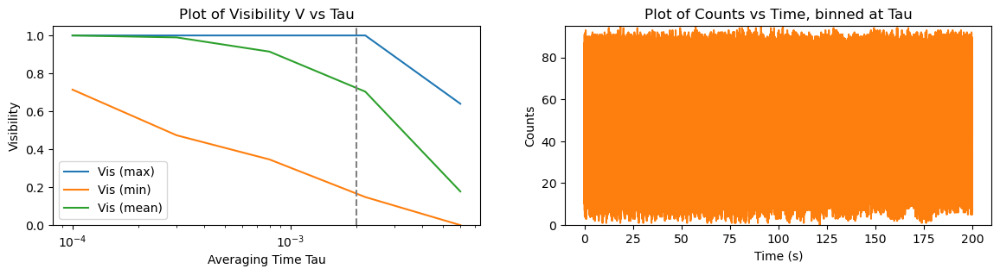

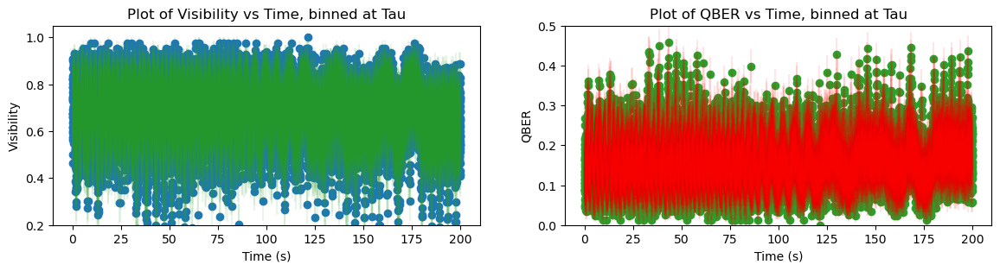

In [606]:
DF_100_nm=Vis.AnalyseMeasurement(DF,6,10,0.002,0.01,secondhalf=True)

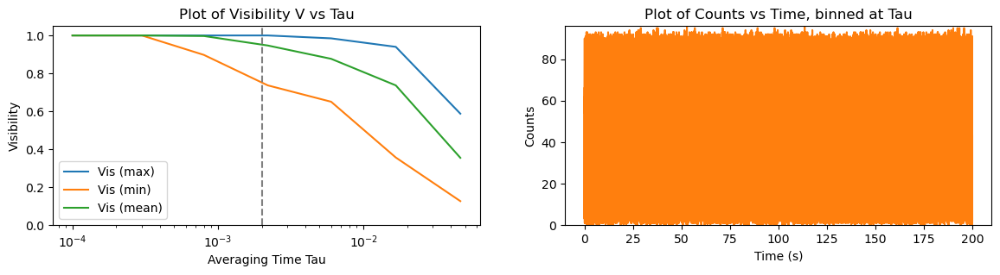

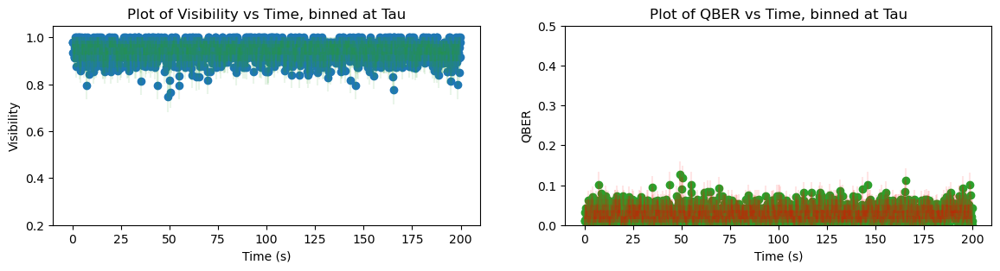

In [608]:
DF_10_nm=Vis.AnalyseMeasurement(DF,7,10,0.002,0.1,secondhalf=True)

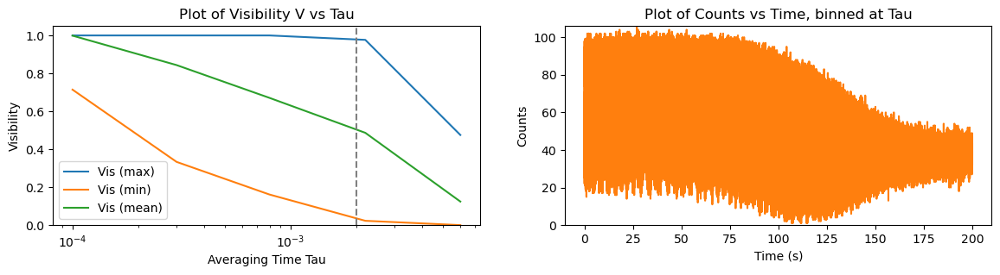

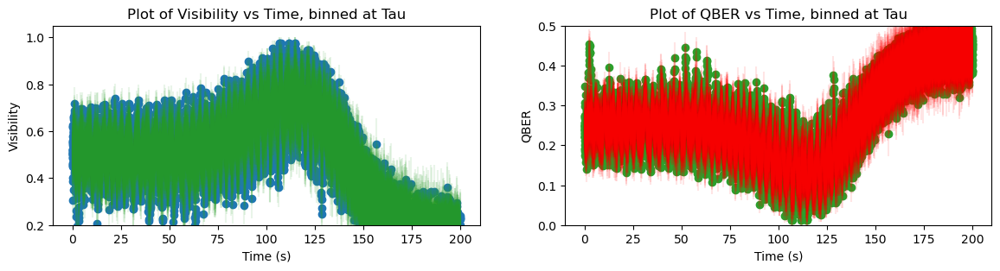

In [604]:
DF_100_voa=Vis.AnalyseMeasurement(DF,2,10,0.002,0.01,secondhalf=True)

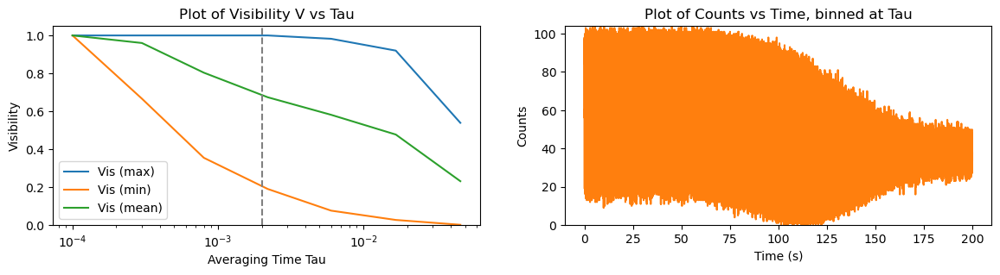

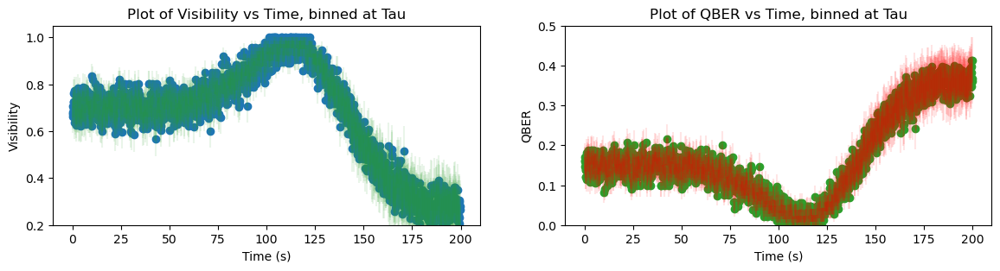

In [610]:
DF_10_voa=Vis.AnalyseMeasurement(DF,3,10,0.002,0.1,secondhalf=True)

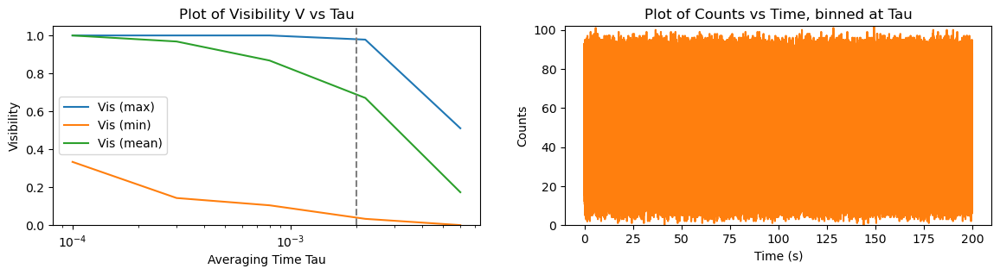

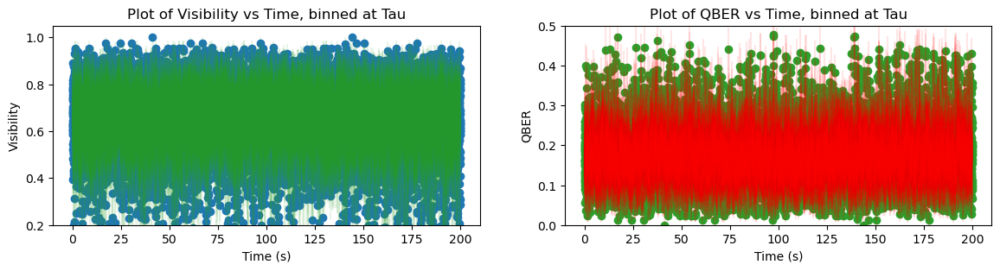

In [602]:
DF_100_em=Vis.AnalyseMeasurement(DF,10,10,0.002,0.01,secondhalf=True)

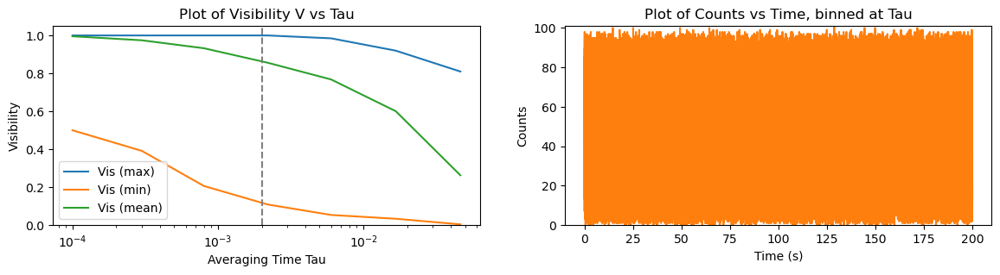

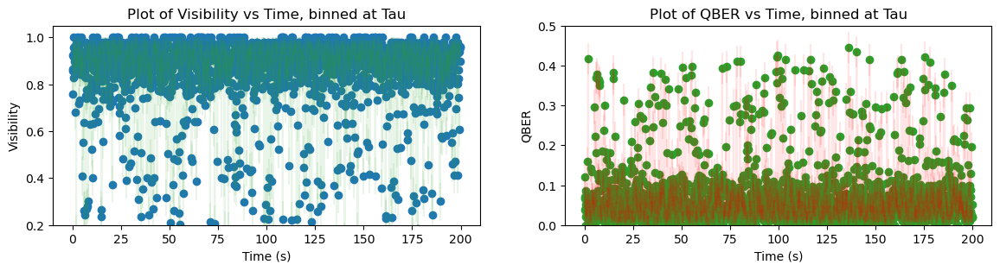

In [612]:
DF_10_em=Vis.AnalyseMeasurement(DF,11,10,0.002,0.1,secondhalf=True)

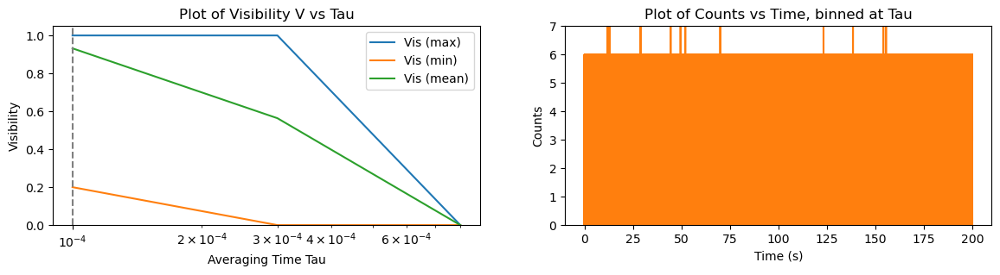

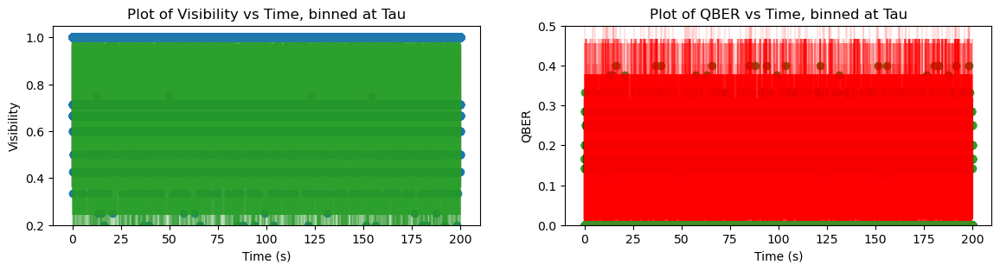

In [614]:
DF_1000_em=Vis.AnalyseMeasurement(DF,9,10,0.0001,0.001,secondhalf=True)

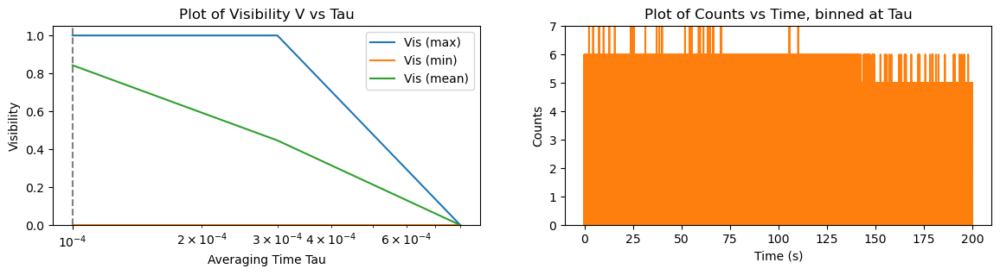

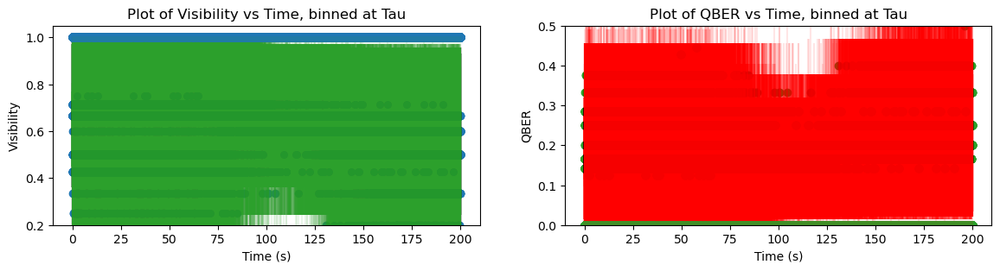

In [616]:
DF_1000_voa=Vis.AnalyseMeasurement(DF,1,10,0.0001,0.001,secondhalf=True)

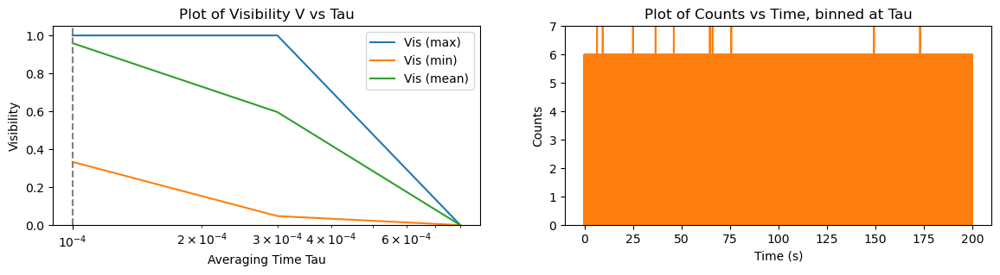

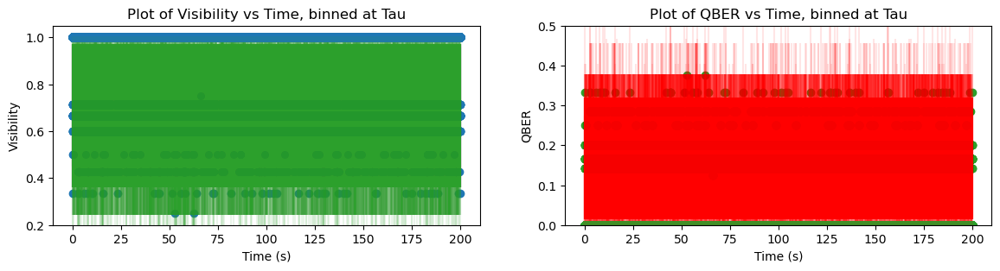

In [618]:
DF_1000_em=Vis.AnalyseMeasurement(DF,5,10,0.0001,0.001,secondhalf=True)

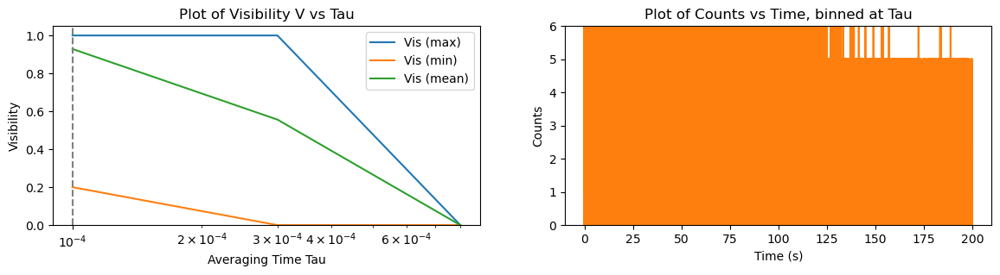

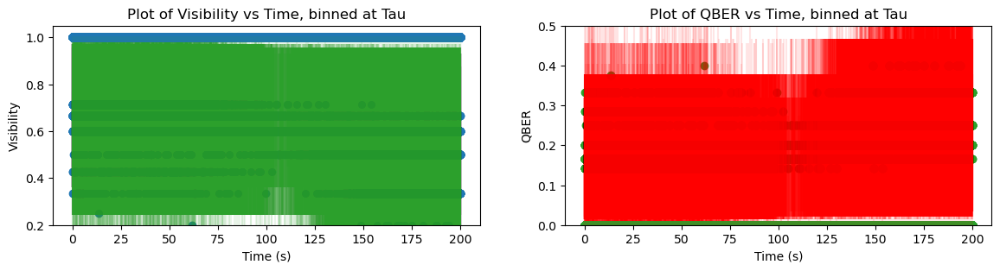

In [622]:
DNF_1000_voa=Vis.AnalyseMeasurement(DNF,0,10,0.0001,0.001,secondhalf=True)

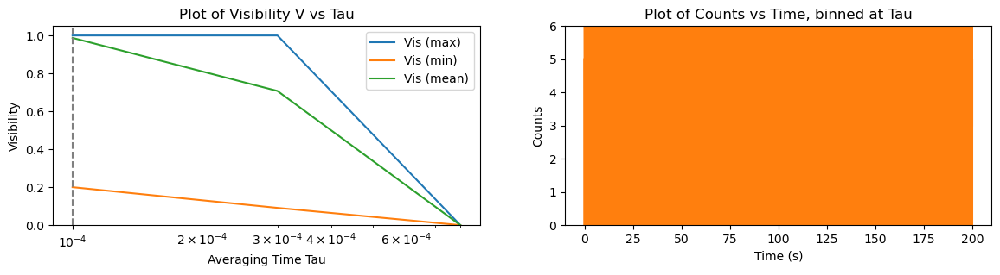

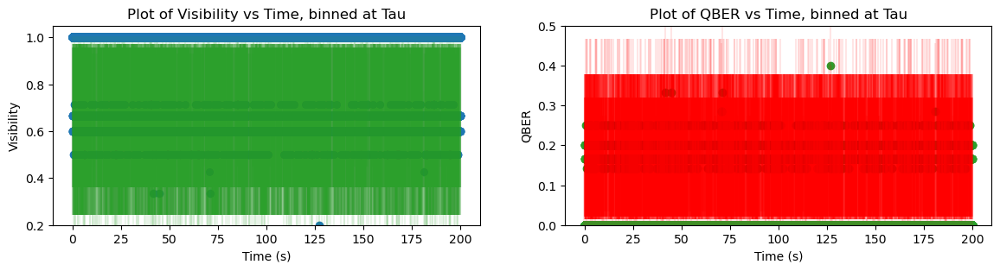

In [623]:
DNF_1000_nm=Vis.AnalyseMeasurement(DNF,4,10,0.0001,0.001,secondhalf=True)

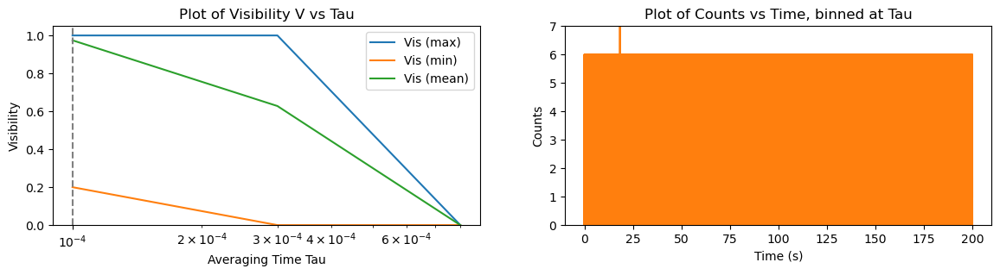

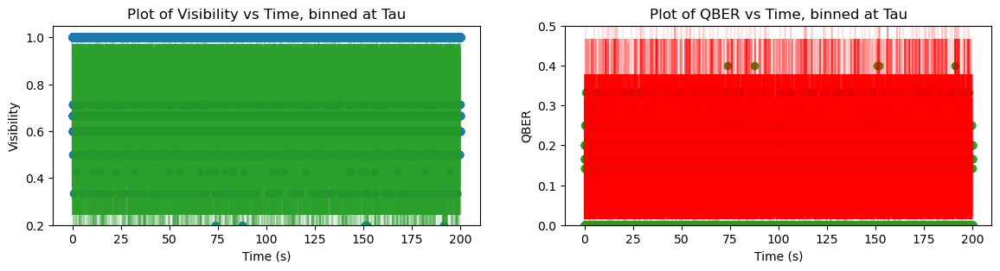

In [646]:
DNF_1000_em=Vis.AnalyseMeasurement(DNF,8,10,0.0001,0.001,secondhalf=True)

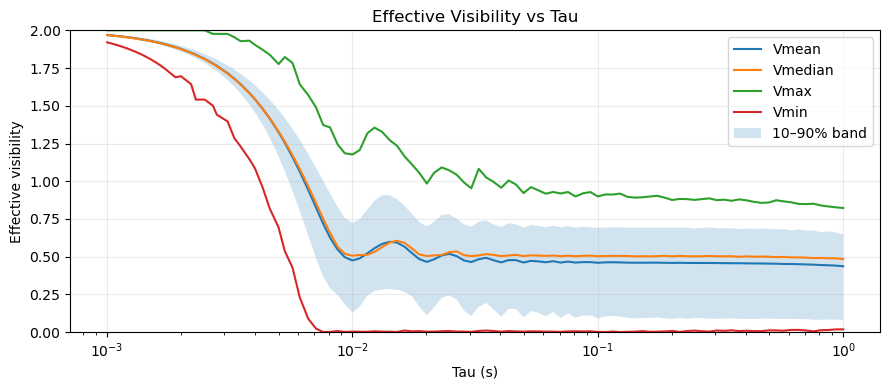

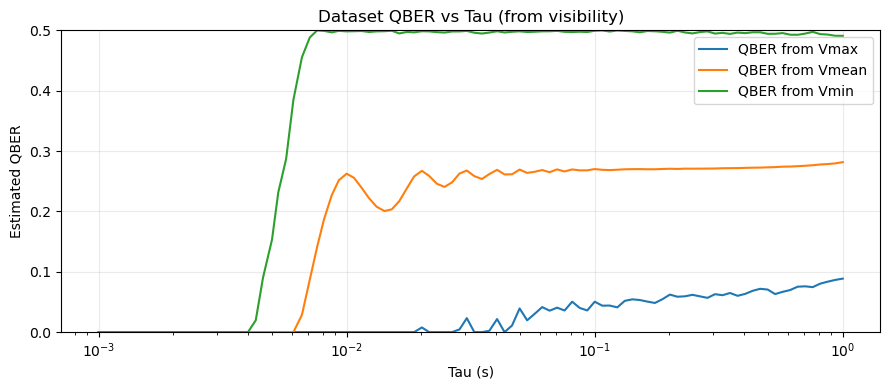

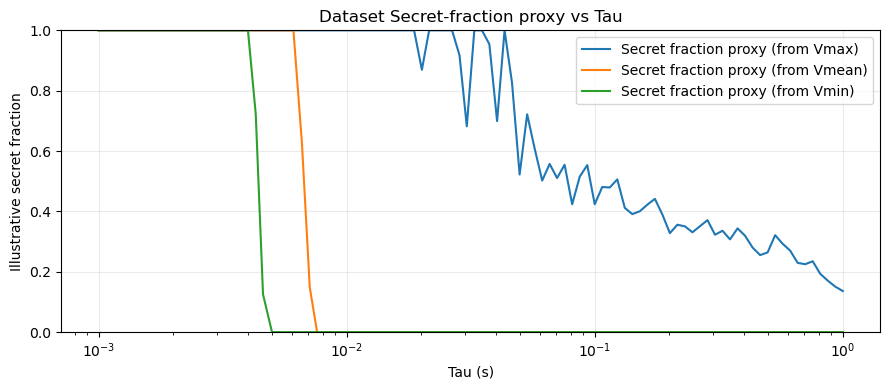

Operating tau (s): 0.1
Knee tau mean (s): 1.0
Knee tau median (s): nan


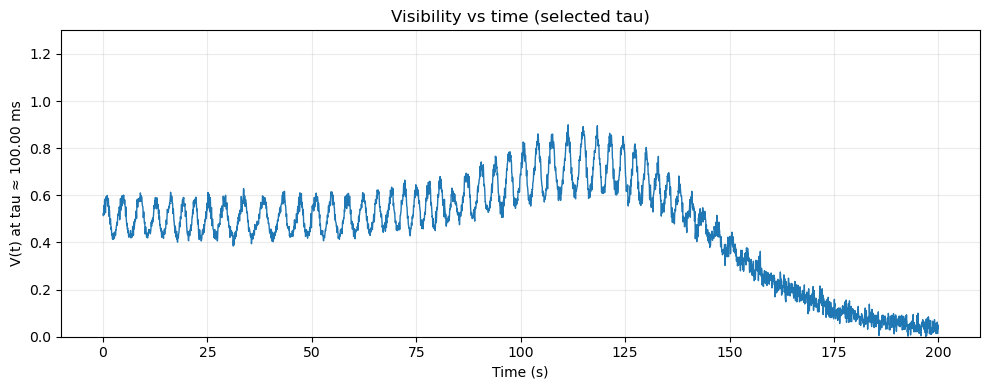

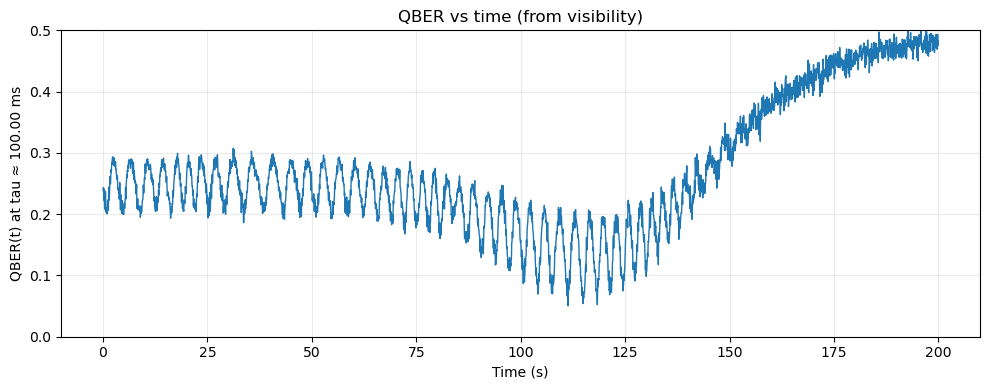

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 1000, 'S': 500, 'tau': 0.1, 'step': 0.05, 'n_windows_total': 3999, 'n_windows_used': 3999, 'mean_counts_per_window_used': 2695.2568142035507}
V median: 0.5032798747460849
V mean:   0.45972088677384576
V 10–90%: 0.0906759192186794 … 0.6908963355732781


In [596]:
if __name__ == "__main__":
    # Example: load your npy which stores (ts, counts)
    ts, counts = DF_100_voa[1][0],DF_100_voa[1][1]

    # Set your ramp frequency
    f_ramp = 100.0
    dt = np.mean(np.diff(ts))
    tau_min = 1e-3
    tau_max = 1
    n_taus = 100

    K_min = int(np.ceil(tau_min / dt))
    K_max = int(np.floor(tau_max / dt))

    Ks = np.unique(
        np.round(
            np.logspace(
                np.log10(K_min),
                np.log10(K_max),
                n_taus
            )
        ).astype(int)
    )

    taus = Ks * dt
    # Run tau sweep
    res = lockin_visibility_summary_vs_tau(ts, counts, f_ramp=f_ramp, taus=taus,overlap=0.5, n_min=0, clip=False)
    # Plot results
    plot_visibility_vs_tau(res)
    plot_qber_and_secret_proxy(res, title_prefix="Dataset")
    cycles=10
    # Choose operating tau and knee
    tau_op = choose_operating_tau(res, f_ramp=f_ramp, cycles_min=cycles, within_frac=0.98, use="median")
    tau_knee_mean = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=cycles, drop_frac=0.95, use="mean")
    tau_knee_med  = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=cycles, drop_frac=0.95, use="median")
    print("Operating tau (s):", tau_op)
    print("Knee tau mean (s):", tau_knee_mean)
    print("Knee tau median (s):", tau_knee_med)

    #Plot time series at operating tau
    plot_visibility_time_series_at_tau(ts, counts, f_ramp=f_ramp, tau=tau_op, overlap=0.5, n_min=0)
    pass

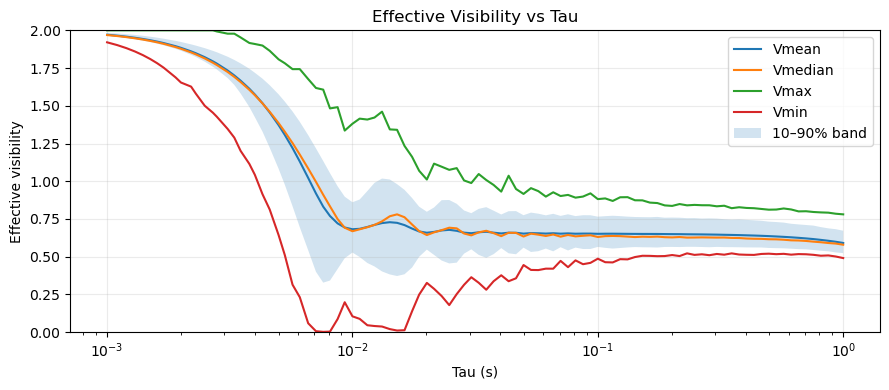

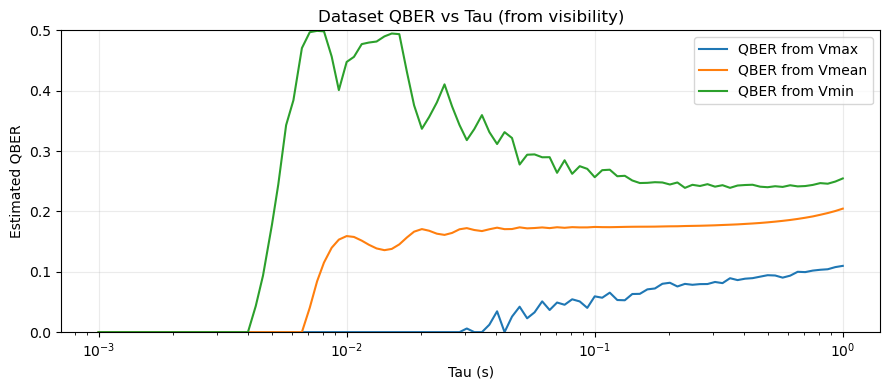

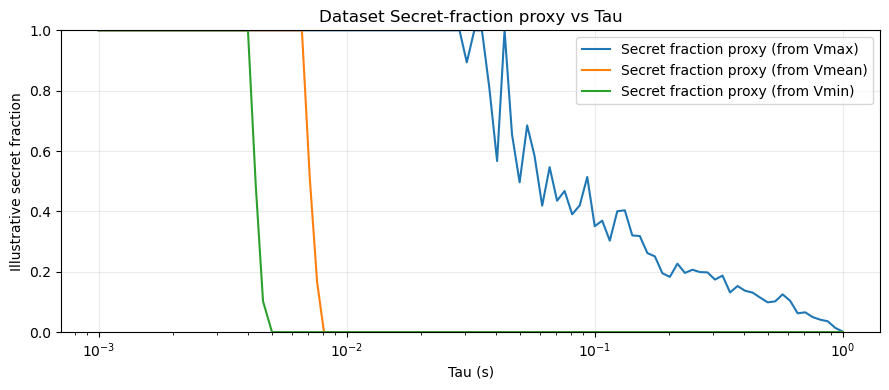

Operating tau (s): 0.1
Knee tau mean (s): 0.7565000000000001
Knee tau median (s): 0.7055


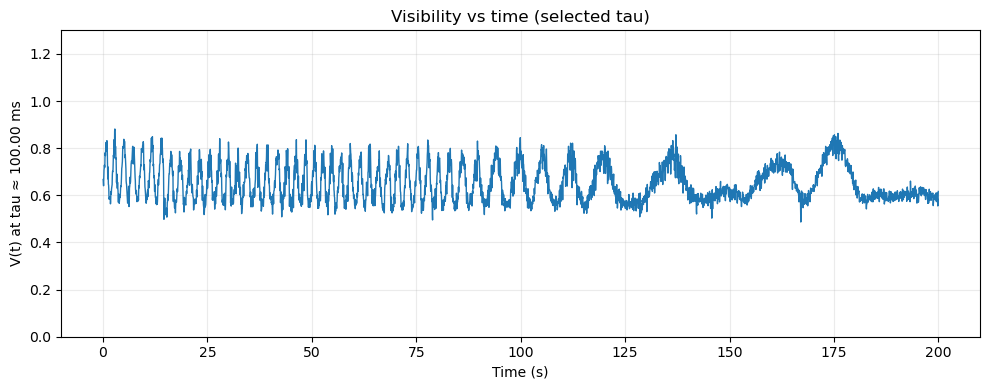

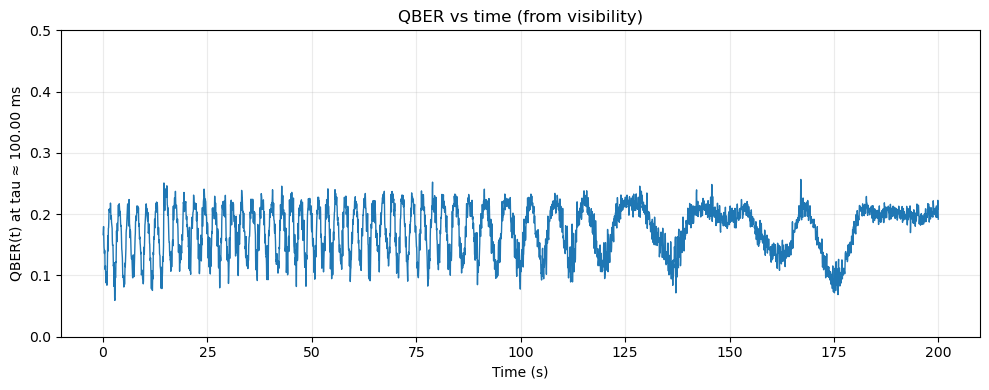

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 1000, 'S': 500, 'tau': 0.1, 'step': 0.05, 'n_windows_total': 3999, 'n_windows_used': 3999, 'mean_counts_per_window_used': 2743.6121530382597}
V median: 0.6306610528048
V mean:   0.65148923061791
V 10–90%: 0.5647105768410825 … 0.7652893523239832


In [598]:
if __name__ == "__main__":
    # Example: load your npy which stores (ts, counts)
    ts, counts = DF_100_nm[1][0],DF_100_nm[1][1]

    # Set your ramp frequency
    f_ramp = 100.0
    dt = np.mean(np.diff(ts))
    tau_min = 1e-3
    tau_max = 1
    n_taus = 100

    K_min = int(np.ceil(tau_min / dt))
    K_max = int(np.floor(tau_max / dt))

    Ks = np.unique(
        np.round(
            np.logspace(
                np.log10(K_min),
                np.log10(K_max),
                n_taus
            )
        ).astype(int)
    )

    taus = Ks * dt
    # Run tau sweep
    res = lockin_visibility_summary_vs_tau(ts, counts, f_ramp=f_ramp, taus=taus,overlap=0.5, n_min=0, clip=False)
    # Plot results
    plot_visibility_vs_tau(res)
    plot_qber_and_secret_proxy(res, title_prefix="Dataset")
    cycles=10
    # Choose operating tau and knee
    tau_op = choose_operating_tau(res, f_ramp=f_ramp, cycles_min=cycles, within_frac=0.98, use="median")
    tau_knee_mean = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=cycles, drop_frac=0.95, use="mean")
    tau_knee_med  = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=cycles, drop_frac=0.95, use="median")
    print("Operating tau (s):", tau_op)
    print("Knee tau mean (s):", tau_knee_mean)
    print("Knee tau median (s):", tau_knee_med)

    #Plot time series at operating tau
    plot_visibility_time_series_at_tau(ts, counts, f_ramp=f_ramp, tau=tau_op, overlap=0.5, n_min=0)
    pass

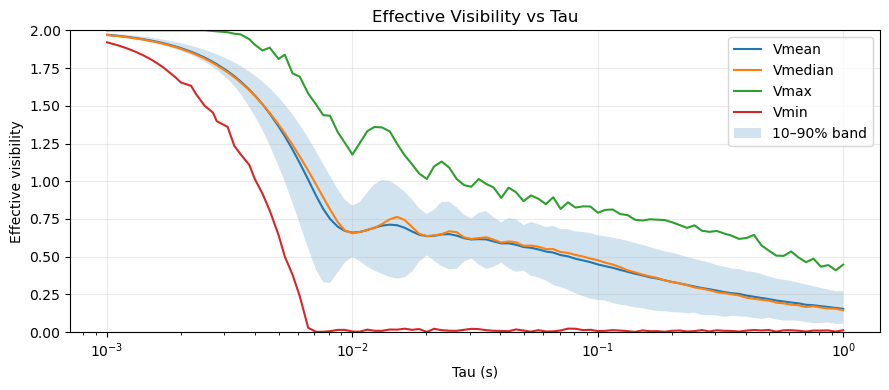

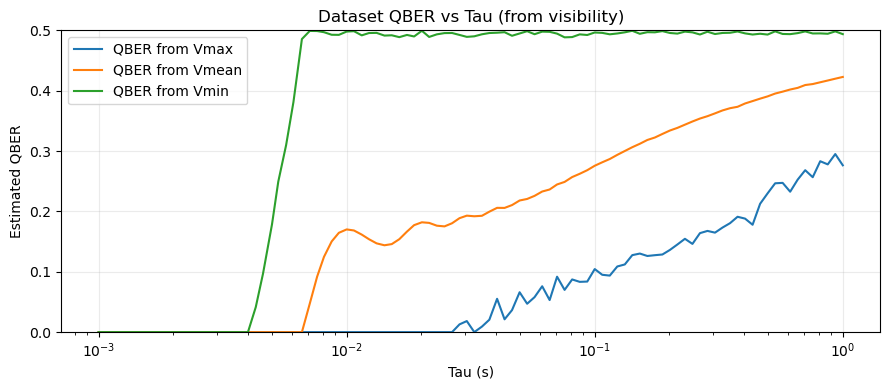

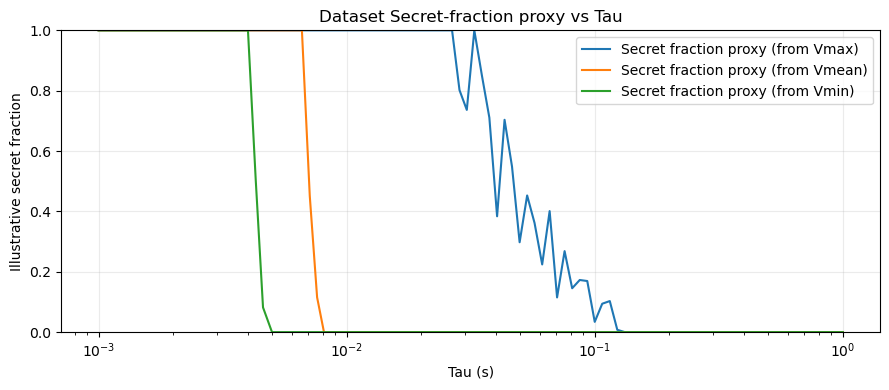

Operating tau (s): 0.1
Knee tau mean (s): 0.1233
Knee tau median (s): 0.115


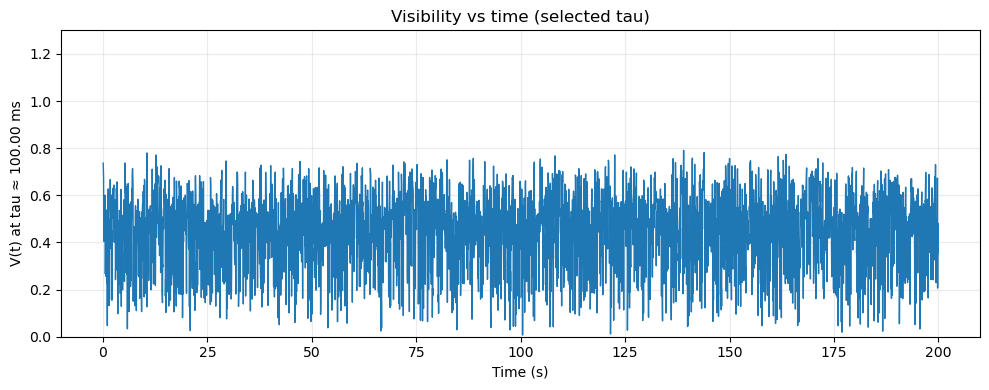

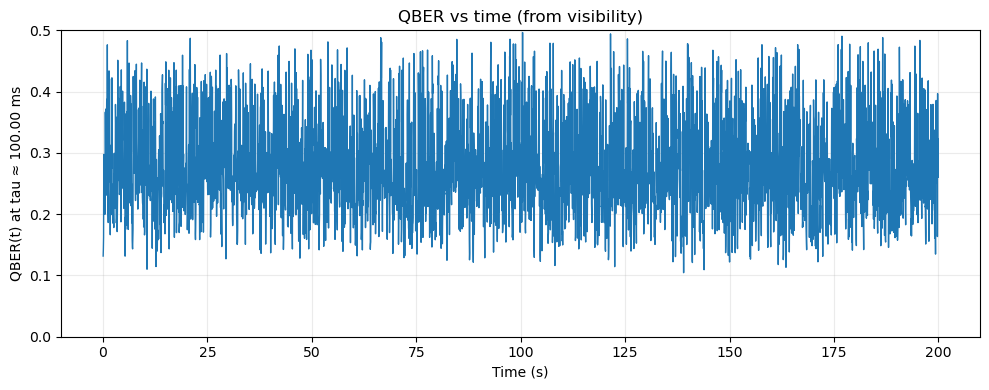

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 1000, 'S': 500, 'tau': 0.1, 'step': 0.05, 'n_windows_total': 3999, 'n_windows_used': 3999, 'mean_counts_per_window_used': 2725.7429357339333}
V median: 0.4763536864683627
V mean:   0.4487028934687434
V 10–90%: 0.21259982120996992 … 0.6414393057298883


In [600]:
if __name__ == "__main__":
    # Example: load your npy which stores (ts, counts)
    ts, counts = DF_100_em[1][0],DF_100_em[1][1]

    # Set your ramp frequency
    f_ramp = 100.0
    dt = np.mean(np.diff(ts))
    tau_min = 1e-3
    tau_max = 1
    n_taus = 100

    K_min = int(np.ceil(tau_min / dt))
    K_max = int(np.floor(tau_max / dt))

    Ks = np.unique(
        np.round(
            np.logspace(
                np.log10(K_min),
                np.log10(K_max),
                n_taus
            )
        ).astype(int)
    )

    taus = Ks * dt
    # Run tau sweep
    res = lockin_visibility_summary_vs_tau(ts, counts, f_ramp=f_ramp, taus=taus,overlap=0.5, n_min=0, clip=False)
    # Plot results
    plot_visibility_vs_tau(res)
    plot_qber_and_secret_proxy(res, title_prefix="Dataset")
    cycles=10
    # Choose operating tau and knee
    tau_op = choose_operating_tau(res, f_ramp=f_ramp, cycles_min=cycles, within_frac=0.98, use="median")
    tau_knee_mean = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=cycles, drop_frac=0.95, use="mean")
    tau_knee_med  = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=cycles, drop_frac=0.95, use="median")
    print("Operating tau (s):", tau_op)
    print("Knee tau mean (s):", tau_knee_mean)
    print("Knee tau median (s):", tau_knee_med)

    #Plot time series at operating tau
    plot_visibility_time_series_at_tau(ts, counts, f_ramp=f_ramp, tau=tau_op, overlap=0.5, n_min=0)
    pass

In [490]:
%matplotlib qt
plt.plot(NL_100_nm[1][0], pm)

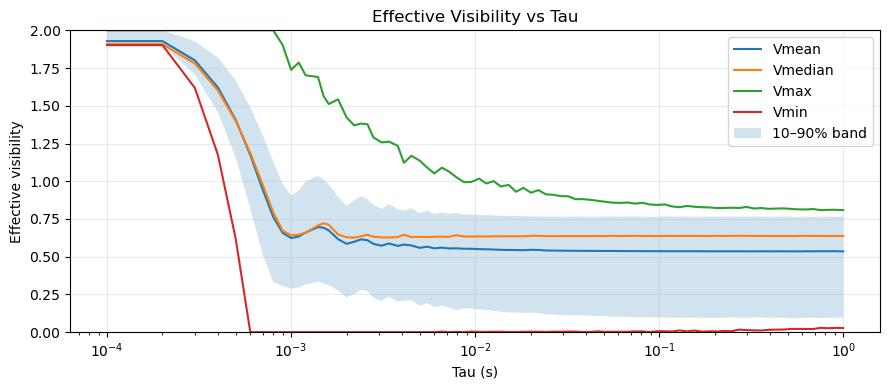

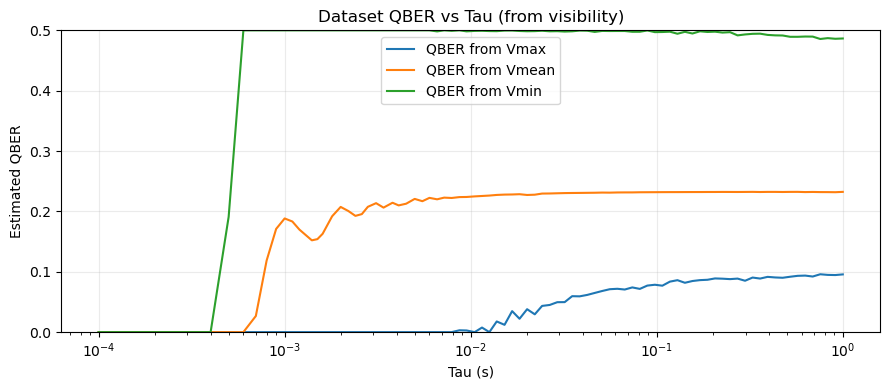

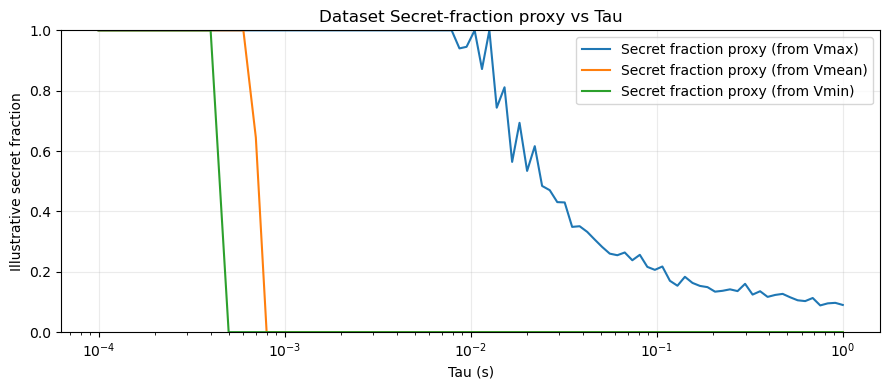

Operating tau (s): 0.0105
Knee tau mean (s): nan
Knee tau median (s): nan


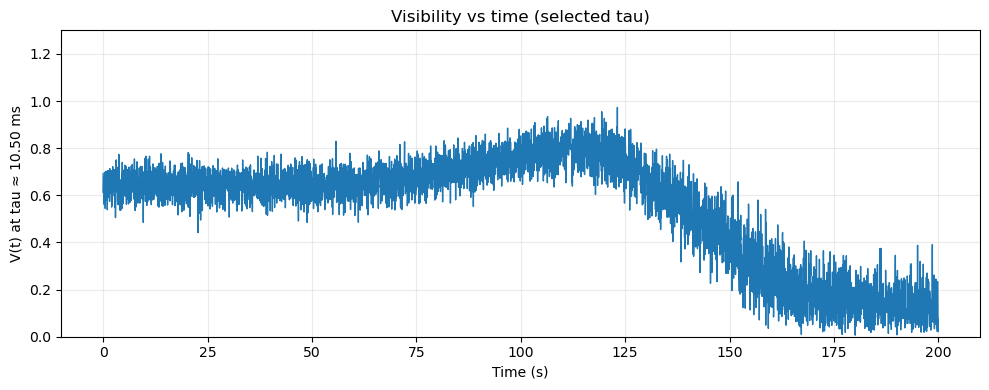

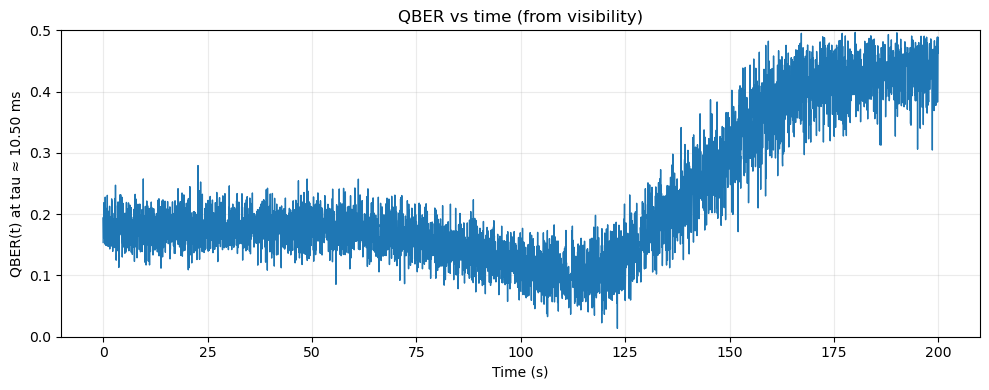

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 105, 'S': 52, 'tau': 0.0105, 'step': 0.005200000000000001, 'n_windows_total': 38460, 'n_windows_used': 38460, 'mean_counts_per_window_used': 230.67254290171607}
V median: 0.6341989529142638
V mean:   0.5502556251195074
V 10–90%: 0.14926953553028327 … 0.7766971017803451


In [640]:
if __name__ == "__main__":
    # Example: load your npy which stores (ts, counts)
    ts, counts = DNF_1000_voa[1][0],DNF_1000_voa[1][1]

    # Set your ramp frequency
    f_ramp = 1000.0
    dt = np.mean(np.diff(ts))
    tau_min = 1e-4
    tau_max = 1
    n_taus = 100

    K_min = int(np.ceil(tau_min / dt))
    K_max = int(np.floor(tau_max / dt))

    Ks = np.unique(
        np.round(
            np.logspace(
                np.log10(K_min),
                np.log10(K_max),
                n_taus
            )
        ).astype(int)
    )

    taus = Ks * dt
    # Run tau sweep
    res = lockin_visibility_summary_vs_tau(ts, counts, f_ramp=f_ramp, taus=taus,overlap=0.5, n_min=0, clip=False)
    # Plot results
    plot_visibility_vs_tau(res)
    plot_qber_and_secret_proxy(res, title_prefix="Dataset")
    cycles=10
    # Choose operating tau and knee
    tau_op = choose_operating_tau(res, f_ramp=f_ramp, cycles_min=cycles, within_frac=0.98, use="median")
    tau_knee_mean = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=cycles, drop_frac=0.95, use="mean")
    tau_knee_med  = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=cycles, drop_frac=0.95, use="median")
    print("Operating tau (s):", tau_op)
    print("Knee tau mean (s):", tau_knee_mean)
    print("Knee tau median (s):", tau_knee_med)

    #Plot time series at operating tau
    plot_visibility_time_series_at_tau(ts, counts, f_ramp=f_ramp, tau=tau_op, overlap=0.5, n_min=0)
    pass

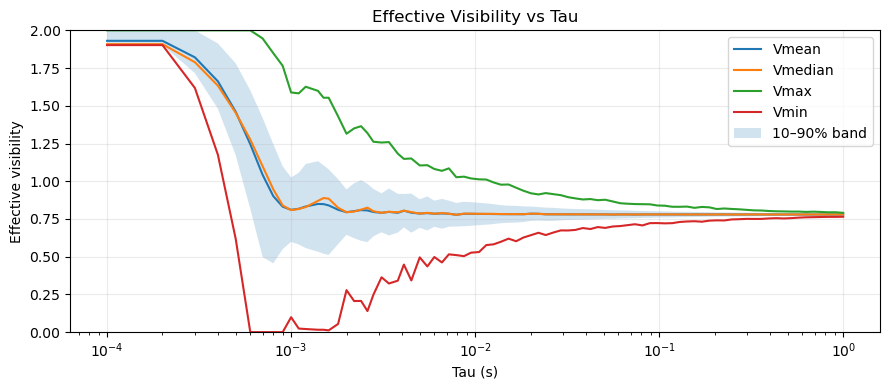

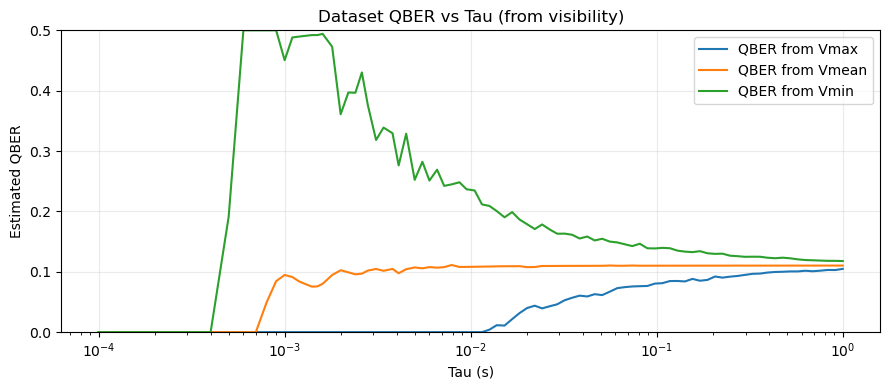

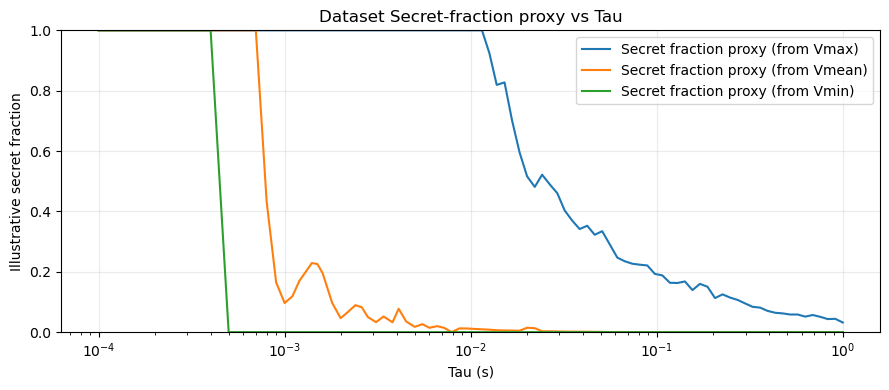

Operating tau (s): 0.0105
Knee tau mean (s): nan
Knee tau median (s): nan


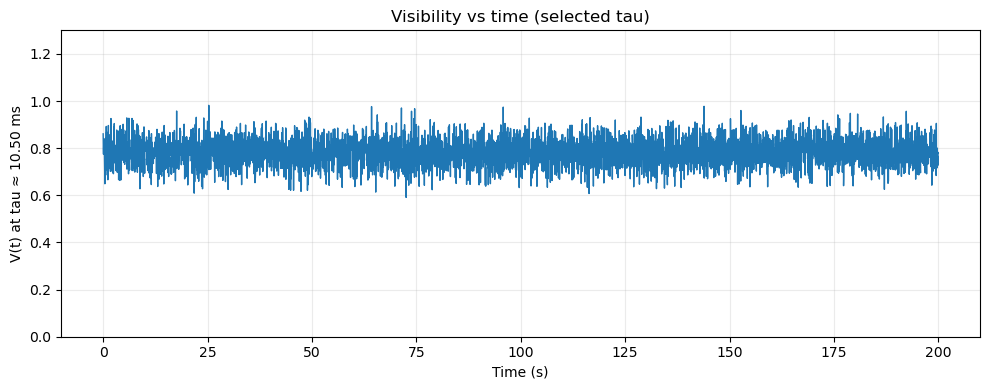

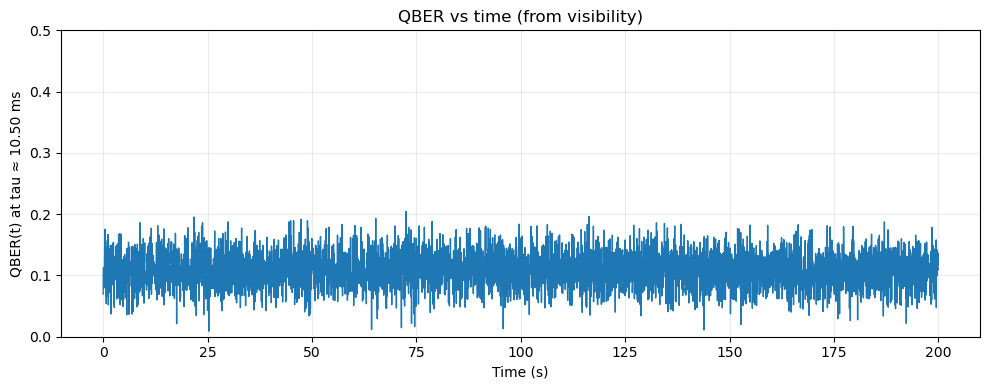

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 105, 'S': 52, 'tau': 0.0105, 'step': 0.005200000000000001, 'n_windows_total': 38460, 'n_windows_used': 38460, 'mean_counts_per_window_used': 230.9385075403016}
V median: 0.7839694299802135
V mean:   0.783435958736046
V 10–90%: 0.7090472432113414 … 0.8569615939444172


In [642]:
if __name__ == "__main__":
    # Example: load your npy which stores (ts, counts)
    ts, counts = DNF_1000_nm[1][0],DNF_1000_nm[1][1]

    # Set your ramp frequency
    f_ramp = 1000.0
    dt = np.mean(np.diff(ts))
    tau_min = 1e-4
    tau_max = 1
    n_taus = 100

    K_min = int(np.ceil(tau_min / dt))
    K_max = int(np.floor(tau_max / dt))

    Ks = np.unique(
        np.round(
            np.logspace(
                np.log10(K_min),
                np.log10(K_max),
                n_taus
            )
        ).astype(int)
    )

    taus = Ks * dt
    # Run tau sweep
    res = lockin_visibility_summary_vs_tau(ts, counts, f_ramp=f_ramp, taus=taus,overlap=0.5, n_min=0, clip=False)
    # Plot results
    plot_visibility_vs_tau(res)
    plot_qber_and_secret_proxy(res, title_prefix="Dataset")
    cycles=10
    # Choose operating tau and knee
    tau_op = choose_operating_tau(res, f_ramp=f_ramp, cycles_min=cycles, within_frac=0.98, use="median")
    tau_knee_mean = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=cycles, drop_frac=0.95, use="mean")
    tau_knee_med  = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=cycles, drop_frac=0.95, use="median")
    print("Operating tau (s):", tau_op)
    print("Knee tau mean (s):", tau_knee_mean)
    print("Knee tau median (s):", tau_knee_med)

    #Plot time series at operating tau
    plot_visibility_time_series_at_tau(ts, counts, f_ramp=f_ramp, tau=tau_op, overlap=0.5, n_min=0)
    pass

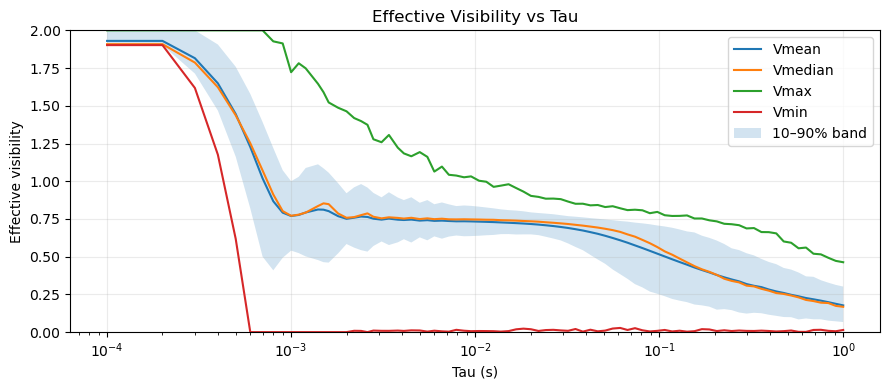

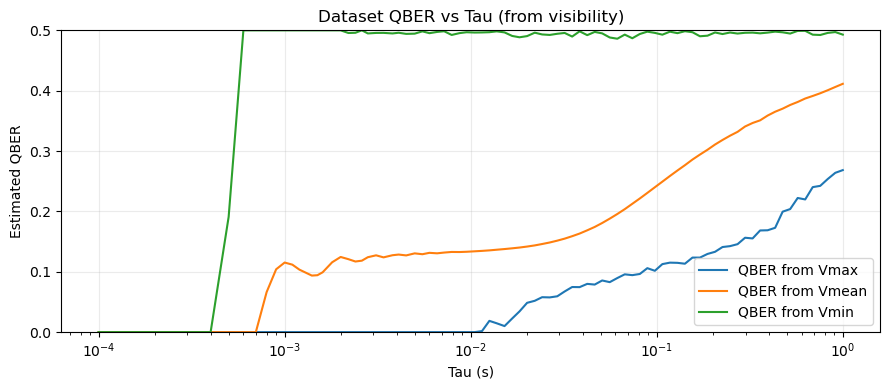

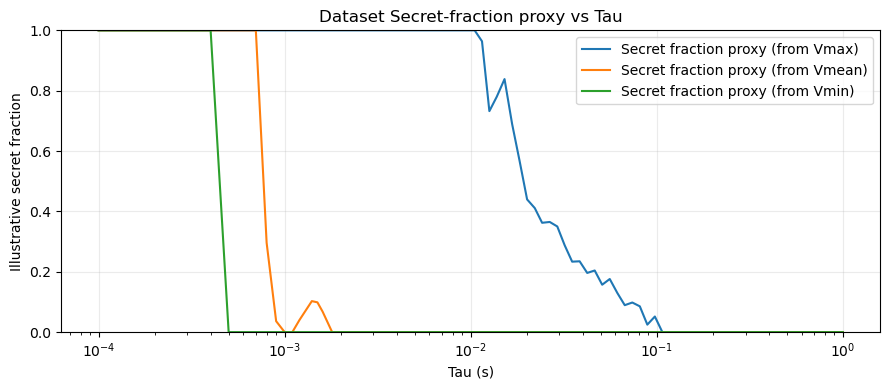

Operating tau (s): 0.0105
Knee tau mean (s): 0.032
Knee tau median (s): 0.0385


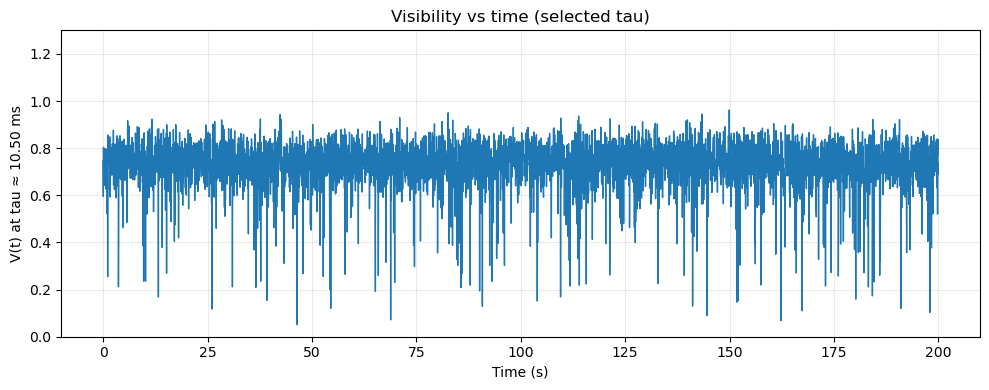

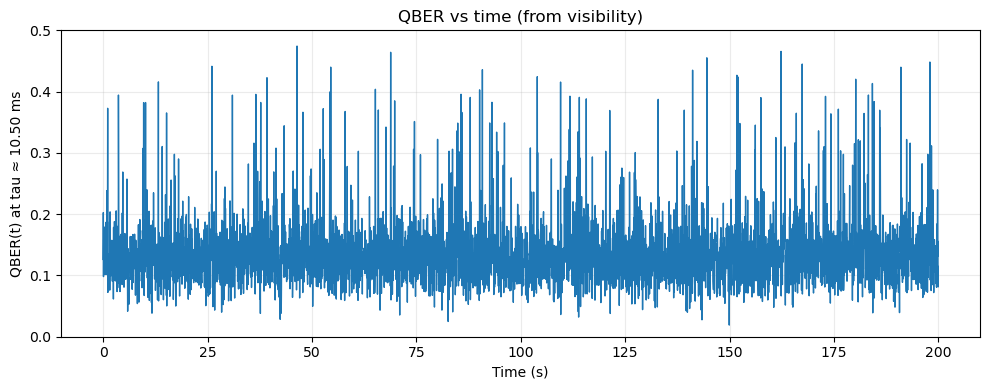

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 105, 'S': 52, 'tau': 0.0105, 'step': 0.005200000000000001, 'n_windows_total': 38460, 'n_windows_used': 38460, 'mean_counts_per_window_used': 233.07654706188248}
V median: 0.7460617852354867
V mean:   0.7322273181815618
V 10–90%: 0.6387350969539102 … 0.8314967997643847


In [648]:
if __name__ == "__main__":
    # Example: load your npy which stores (ts, counts)
    ts, counts = DNF_1000_em[1][0],DNF_1000_em[1][1]

    # Set your ramp frequency
    f_ramp = 1000.0
    dt = np.mean(np.diff(ts))
    tau_min = 1e-4
    tau_max = 1
    n_taus = 100

    K_min = int(np.ceil(tau_min / dt))
    K_max = int(np.floor(tau_max / dt))

    Ks = np.unique(
        np.round(
            np.logspace(
                np.log10(K_min),
                np.log10(K_max),
                n_taus
            )
        ).astype(int)
    )

    taus = Ks * dt
    # Run tau sweep
    res = lockin_visibility_summary_vs_tau(ts, counts, f_ramp=f_ramp, taus=taus,overlap=0.5, n_min=0, clip=False)
    # Plot results
    plot_visibility_vs_tau(res)
    plot_qber_and_secret_proxy(res, title_prefix="Dataset")
    cycles=10
    # Choose operating tau and knee
    tau_op = choose_operating_tau(res, f_ramp=f_ramp, cycles_min=cycles, within_frac=0.98, use="median")
    tau_knee_mean = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=cycles, drop_frac=0.95, use="mean")
    tau_knee_med  = estimate_knee_tau(res, f_ramp=f_ramp, cycles_min=cycles, drop_frac=0.95, use="median")
    print("Operating tau (s):", tau_op)
    print("Knee tau mean (s):", tau_knee_mean)
    print("Knee tau median (s):", tau_knee_med)

    #Plot time series at operating tau
    plot_visibility_time_series_at_tau(ts, counts, f_ramp=f_ramp, tau=tau_op, overlap=0.5, n_min=0)
    pass

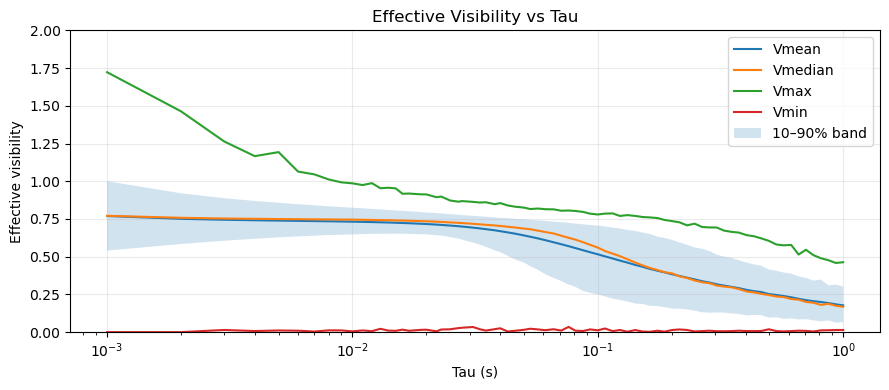

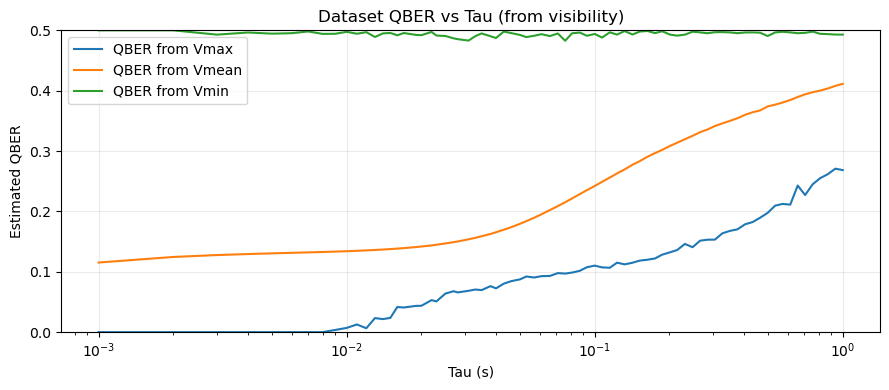

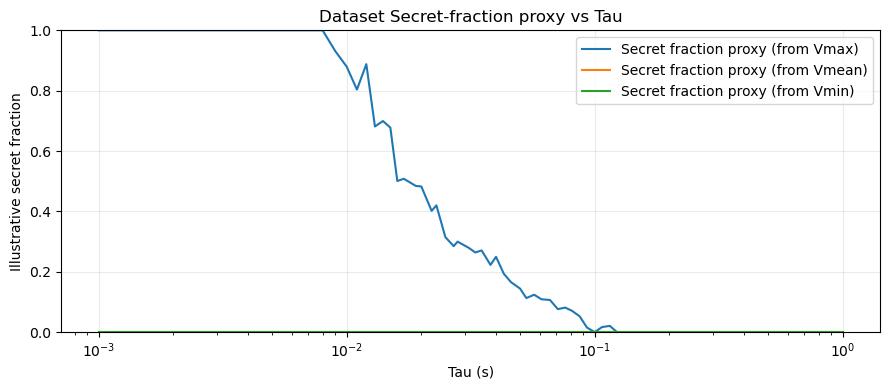

Operating tau (s): 0.01
Knee tau mean (s): 0.031
Knee tau median (s): 0.038


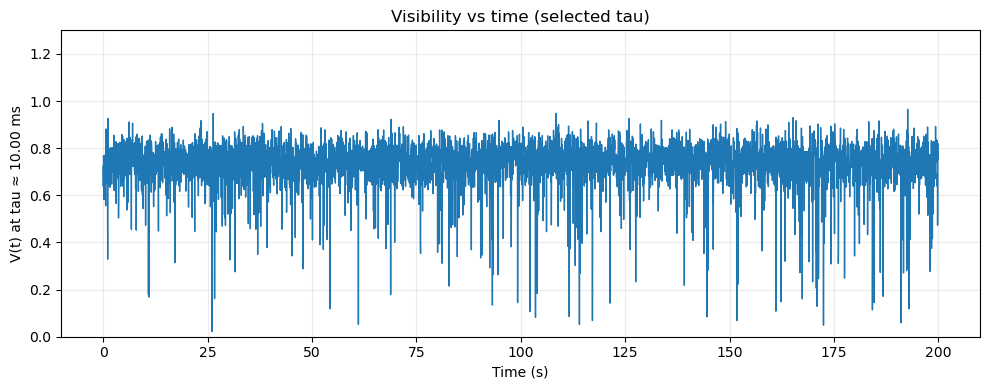

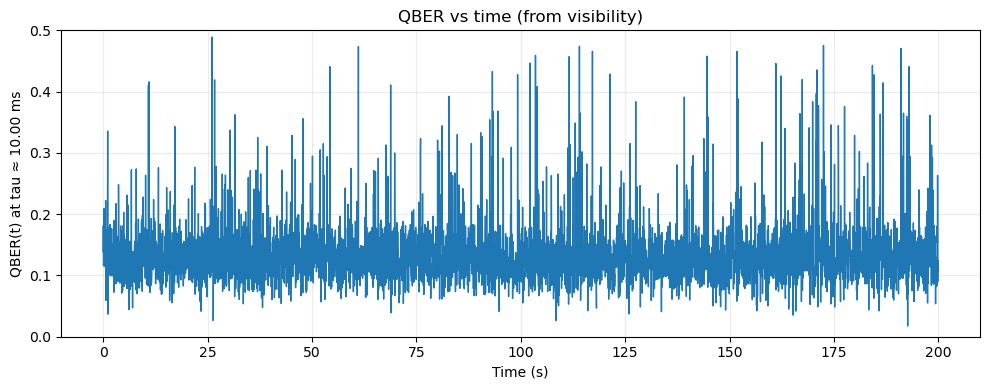

[Selected tau diagnostics]
{'dt': 0.0001, 'K': 100, 'S': 50, 'tau': 0.01, 'step': 0.005, 'n_windows_total': 39999, 'n_windows_used': 39999, 'mean_counts_per_window_used': 221.98149953748845}
V median: 0.7455273486519507
V mean:   0.7318835098218526
V 10–90%: 0.6475932680337773 … 0.8245211778850766


In [7]:
Vis.AnalyseMeasurement_New(DNF,8,100,1000,1e-4,1,None,10)

In [656]:
def timestamps_to_elapsed_seconds(timestamps: np.ndarray) -> np.ndarray:
    """
    Convert an array of absolute timestamps (numpy datetime64)
    into time since start of measurement, in seconds.
    """
    ts = np.asarray(timestamps)

    if ts.dtype.kind != 'M':  # not a datetime64
        raise TypeError(f"Expected datetime64 array, got {ts.dtype}")

    # time offset from first sample
    dt = ts - ts[0]

    # convert timedeltas to float seconds
    elapsed_sec = dt / np.timedelta64(1, 's')
    return elapsed_sec.astype(float)